In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 8
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 64

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 64
Discriminator feature maps: 64
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 182,657
Discriminator parameters: 138,689
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(8, 1, 1))
    (1): ConvTranspose2d(8, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.502881	G_loss: 1.091164
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.253388	G_loss: 0.966164
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.193250	G_loss: 0.973157
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.512816	G_loss: 0.881417
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.235214	G_loss: 0.861637
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.255283	G_loss: 0.963156
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.192732	G_loss: 0.888733
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.185355	G_loss: 0.947143
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.329623	G_loss: 1.001591
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.232660	G_loss: 1.111606
====> Epoch: 1 Train D_loss: 1.2596, Train G_loss: 0.9776
====> Epoch: 1 Val D_loss: 1.2550, Val G_loss: 0.8559
📈 Epoch 1 Summary:
   Train D Loss: 1.2596, Val D Loss: 1.2550
   Train G Loss: 0.9776, Val G Loss: 0.8559

📊 Epoch 2/100
------------------------

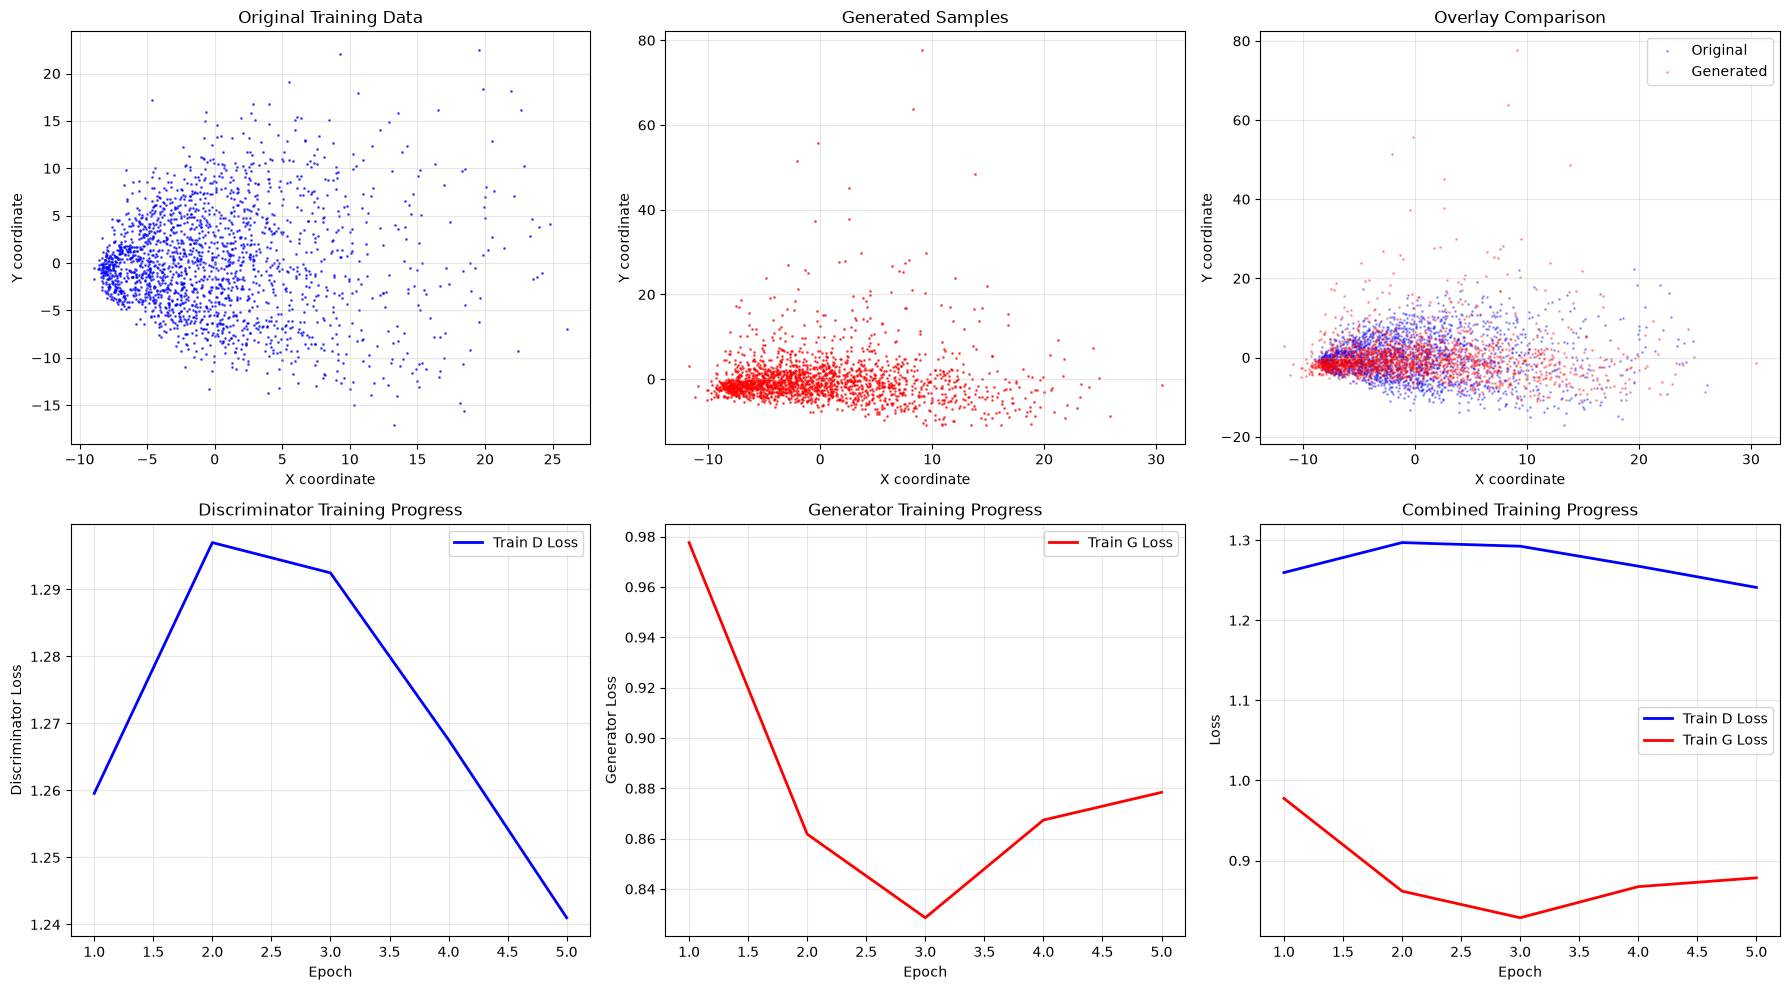

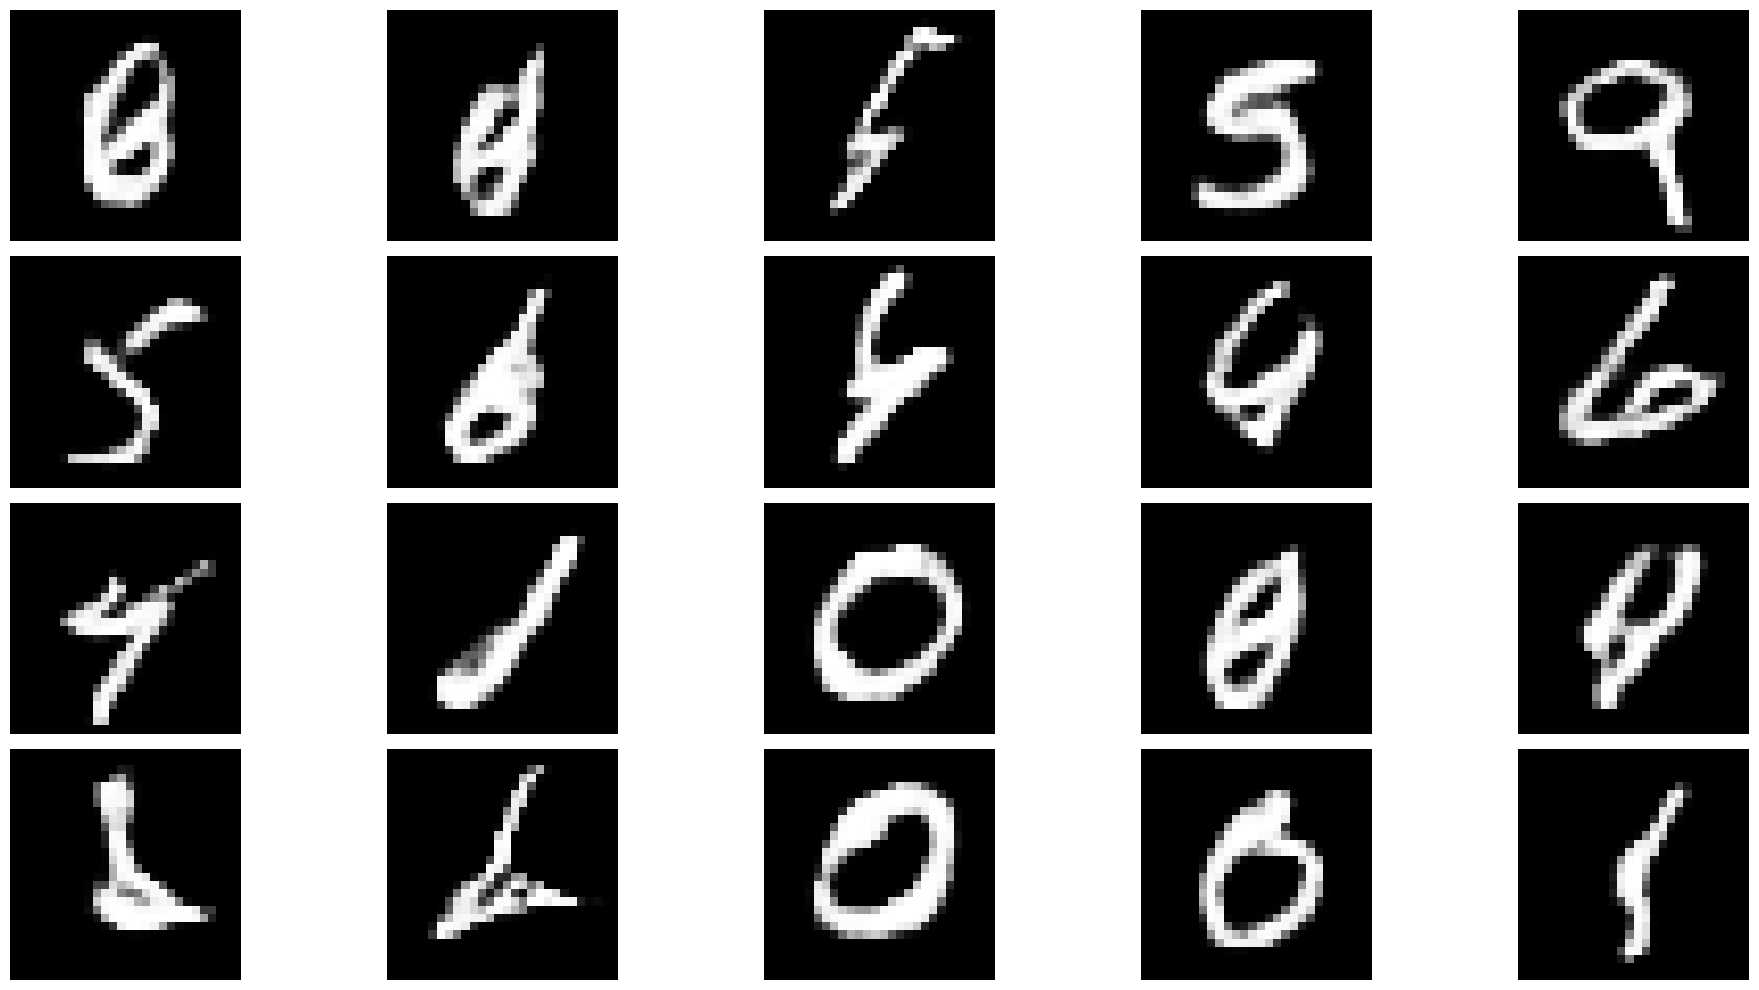

📈 Epoch 5 Summary:
   Train D Loss: 1.2410, Val D Loss: 1.2897
   Train G Loss: 0.8784, Val G Loss: 0.8674

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.227095	G_loss: 0.884565
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.280224	G_loss: 0.803771
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.195077	G_loss: 0.880248
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.236354	G_loss: 1.048475
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.210961	G_loss: 0.871915
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.167020	G_loss: 0.912496
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.166219	G_loss: 1.091318
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.155990	G_loss: 0.939962
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.422170	G_loss: 1.276605
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.171582	G_loss: 0.859194
====> Epoch: 6 Train D_loss: 1.2272, Train G_loss: 0.8989
====> Epoch: 6 Val D_loss: 1.3540, Val G_loss: 0.5156
📈 Epoch 6 Summary:
   Train D Loss: 1.2272, Val D Loss: 1.3540
   Train G Loss: 0.8989, Val G Loss: 0

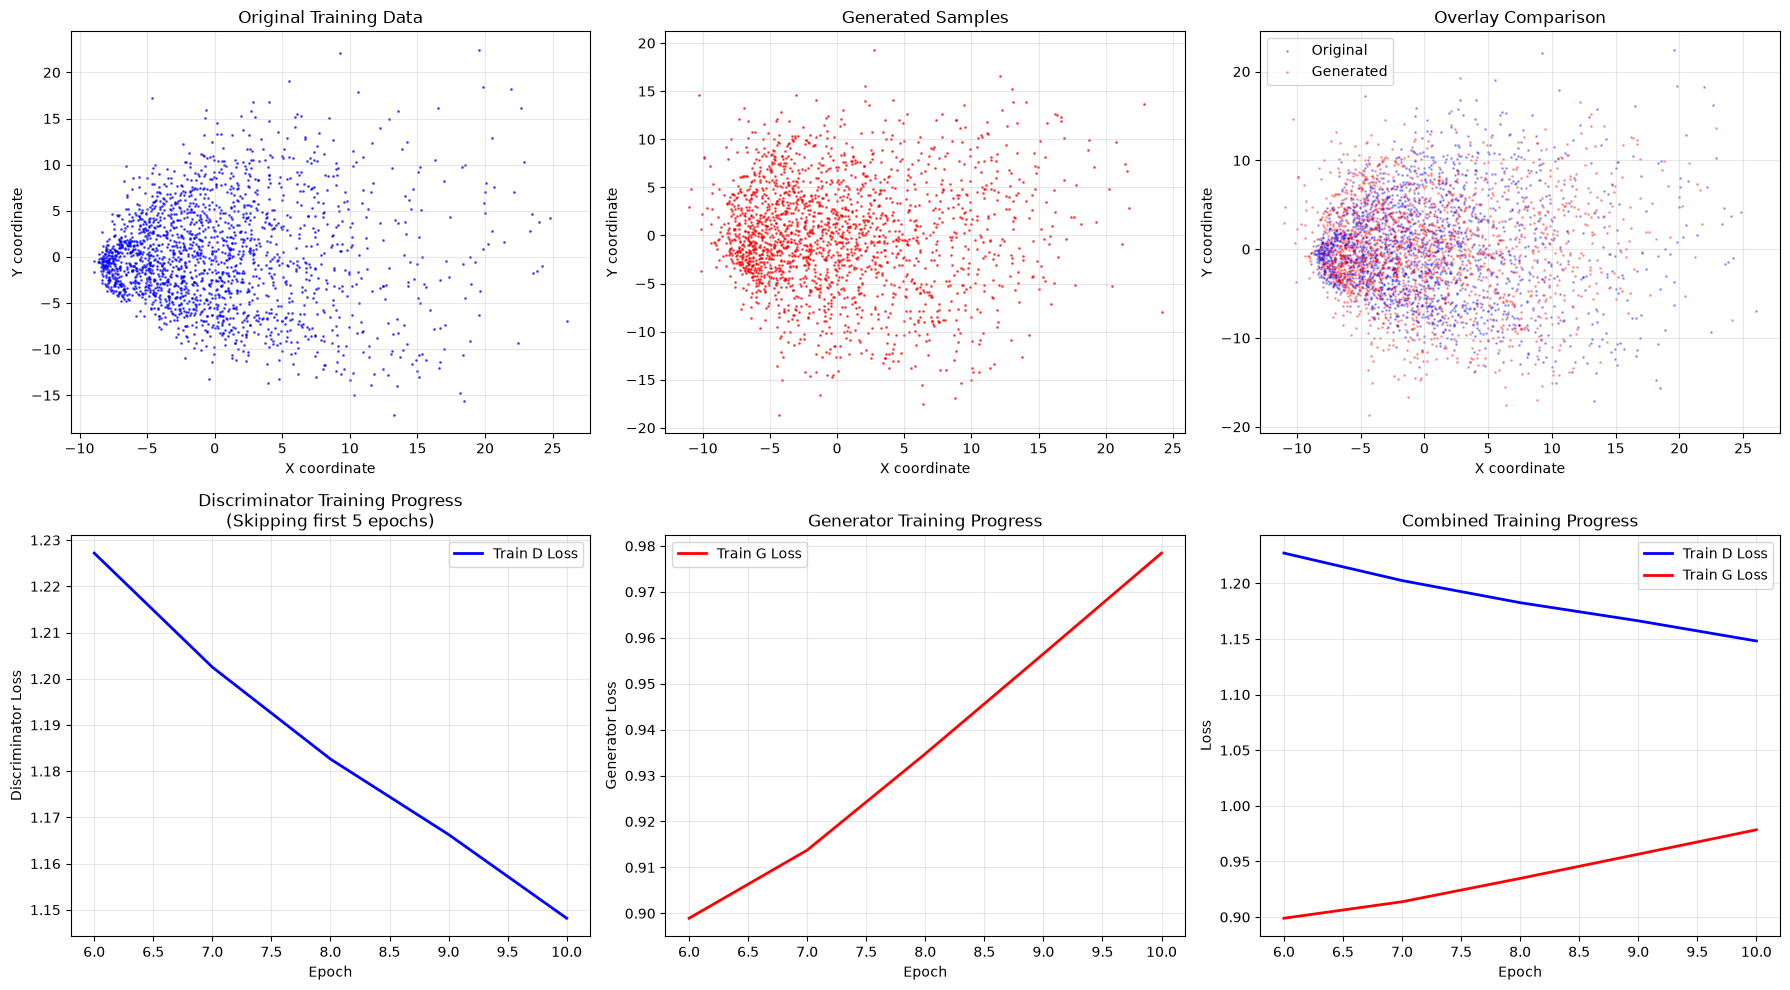

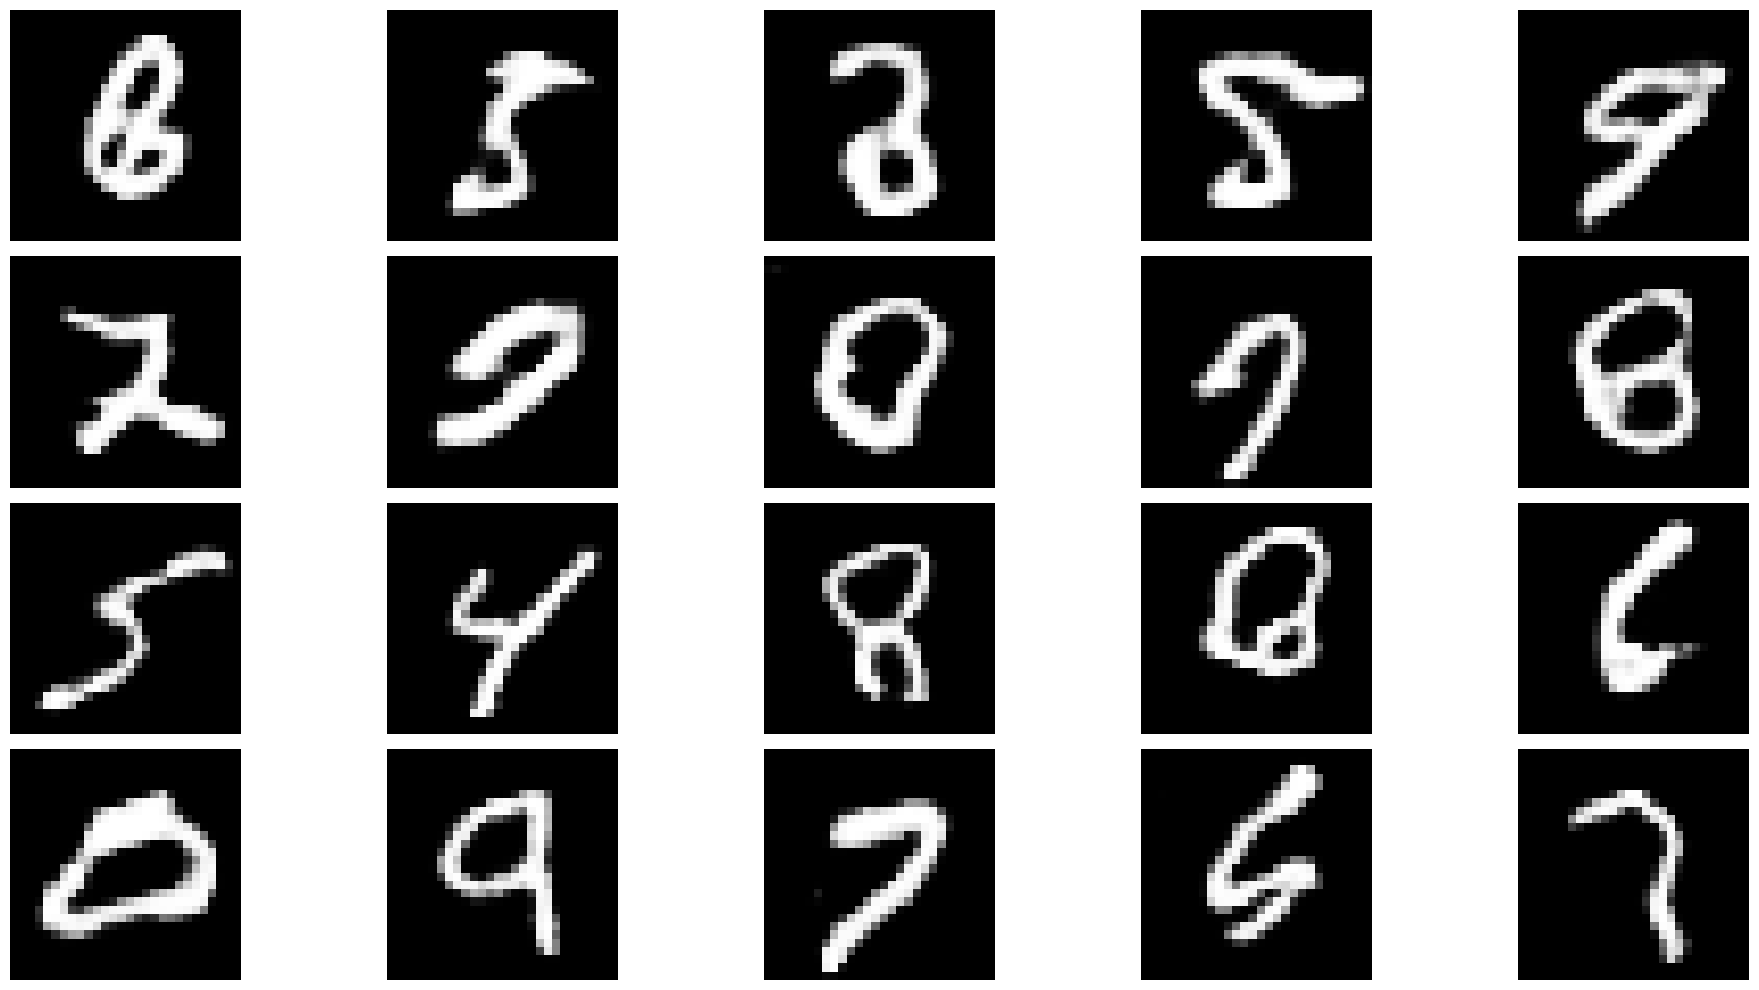

📈 Epoch 10 Summary:
   Train D Loss: 1.1482, Val D Loss: 1.2360
   Train G Loss: 0.9784, Val G Loss: 1.0008

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.107459	G_loss: 0.766591
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.110436	G_loss: 0.901498
Epoch: 11 [12800/60000 (21%)]	D_loss: 1.156268	G_loss: 0.781492
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.136095	G_loss: 1.479569
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.163853	G_loss: 1.085442
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.206705	G_loss: 0.580268
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.095411	G_loss: 0.865534
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.505046	G_loss: 0.587226
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.020643	G_loss: 0.797782
Epoch: 11 [57600/60000 (96%)]	D_loss: 1.213906	G_loss: 1.486294
====> Epoch: 11 Train D_loss: 1.1284, Train G_loss: 1.0006
====> Epoch: 11 Val D_loss: 1.5683, Val G_loss: 1.7606
📈 Epoch 11 Summary:
   Train D Loss: 1.1284, Val D Loss: 1.5683
   Train G Loss: 1.0006

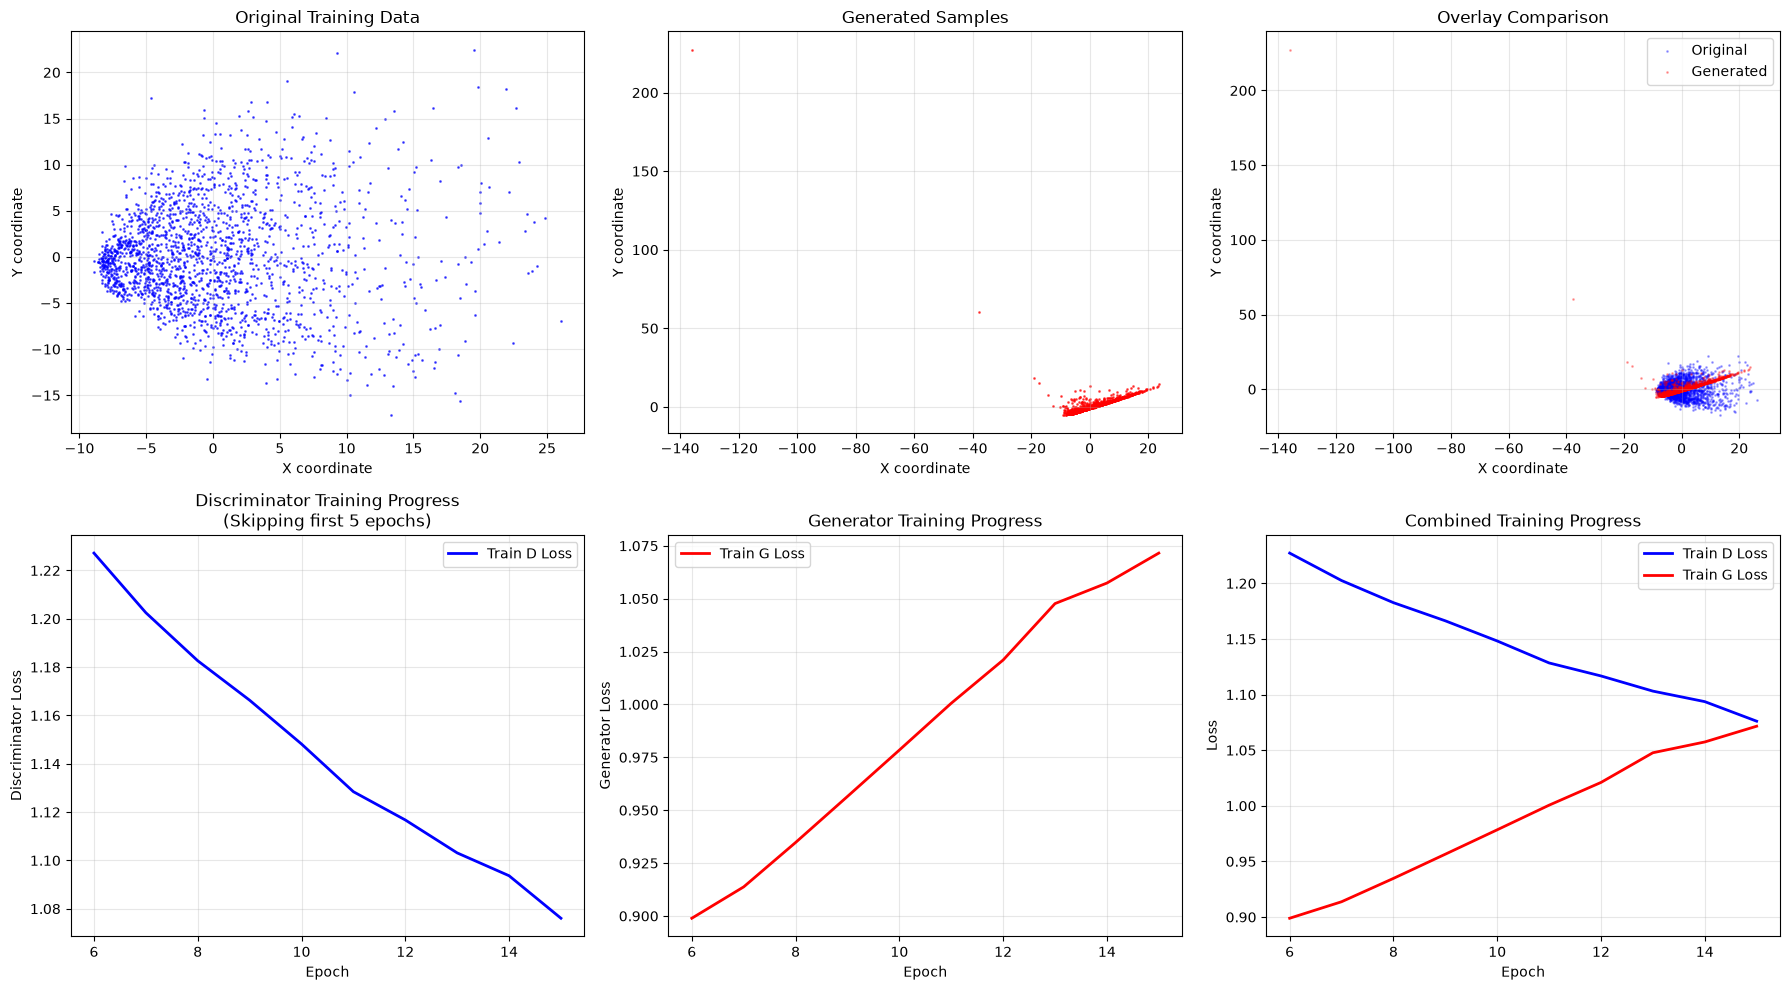

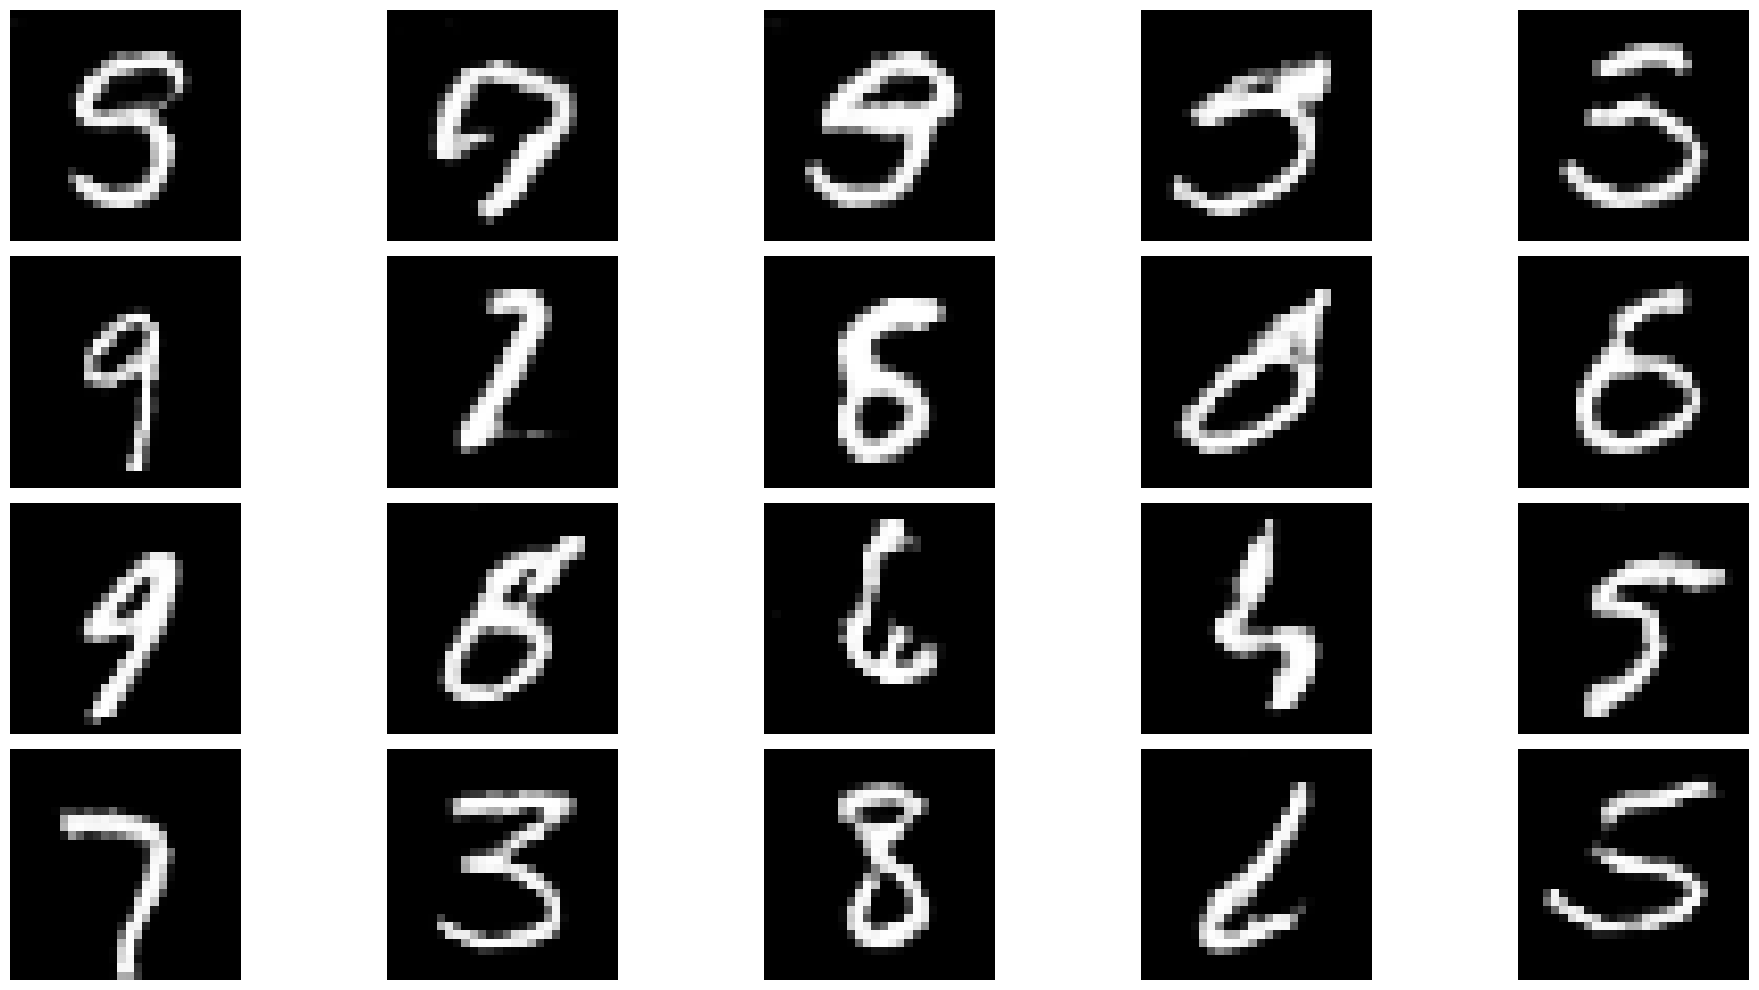

📈 Epoch 15 Summary:
   Train D Loss: 1.0761, Val D Loss: 1.1924
   Train G Loss: 1.0716, Val G Loss: 0.9570

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.039648	G_loss: 0.817218
Epoch: 16 [6400/60000 (11%)]	D_loss: 1.027617	G_loss: 1.239407
Epoch: 16 [12800/60000 (21%)]	D_loss: 1.238659	G_loss: 0.712773
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.012355	G_loss: 1.059706
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.046146	G_loss: 1.311337
Epoch: 16 [32000/60000 (53%)]	D_loss: 1.056655	G_loss: 1.385106
Epoch: 16 [38400/60000 (64%)]	D_loss: 1.123211	G_loss: 0.926093
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.128713	G_loss: 0.694126
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.059067	G_loss: 1.123840
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.084556	G_loss: 0.801300
====> Epoch: 16 Train D_loss: 1.0671, Train G_loss: 1.0868
====> Epoch: 16 Val D_loss: 1.2012, Val G_loss: 1.0209
📈 Epoch 16 Summary:
   Train D Loss: 1.0671, Val D Loss: 1.2012
   Train G Loss: 1.0868

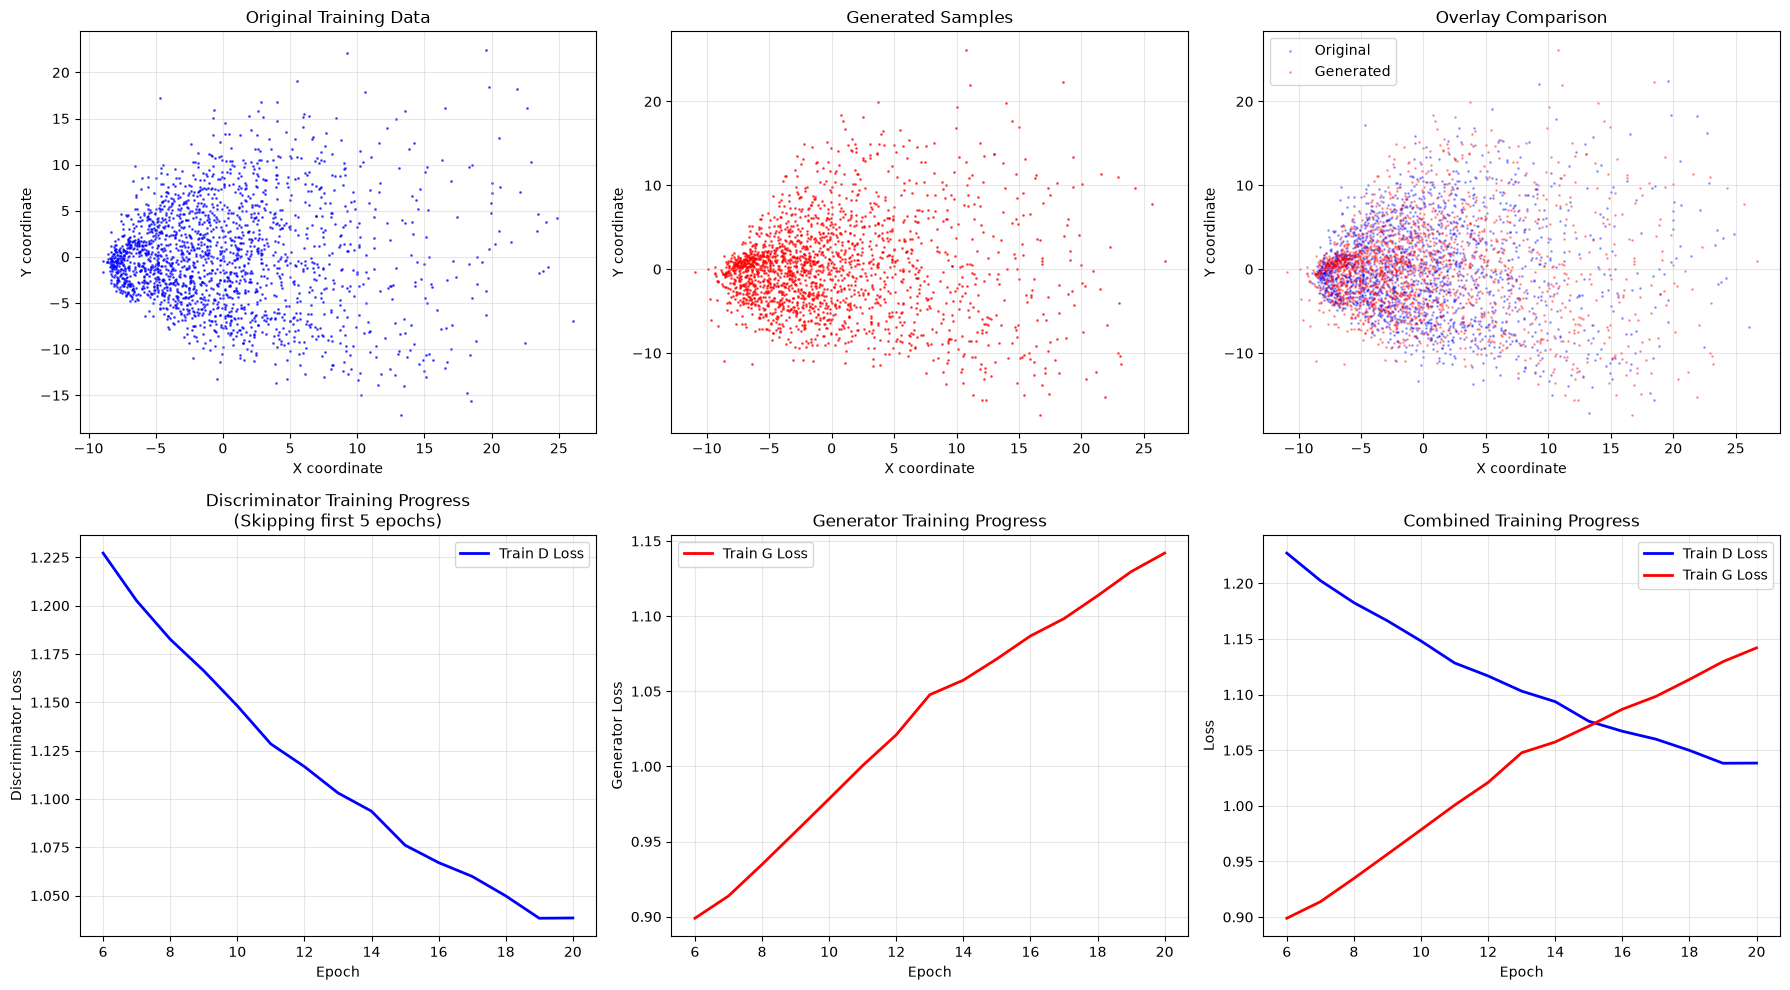

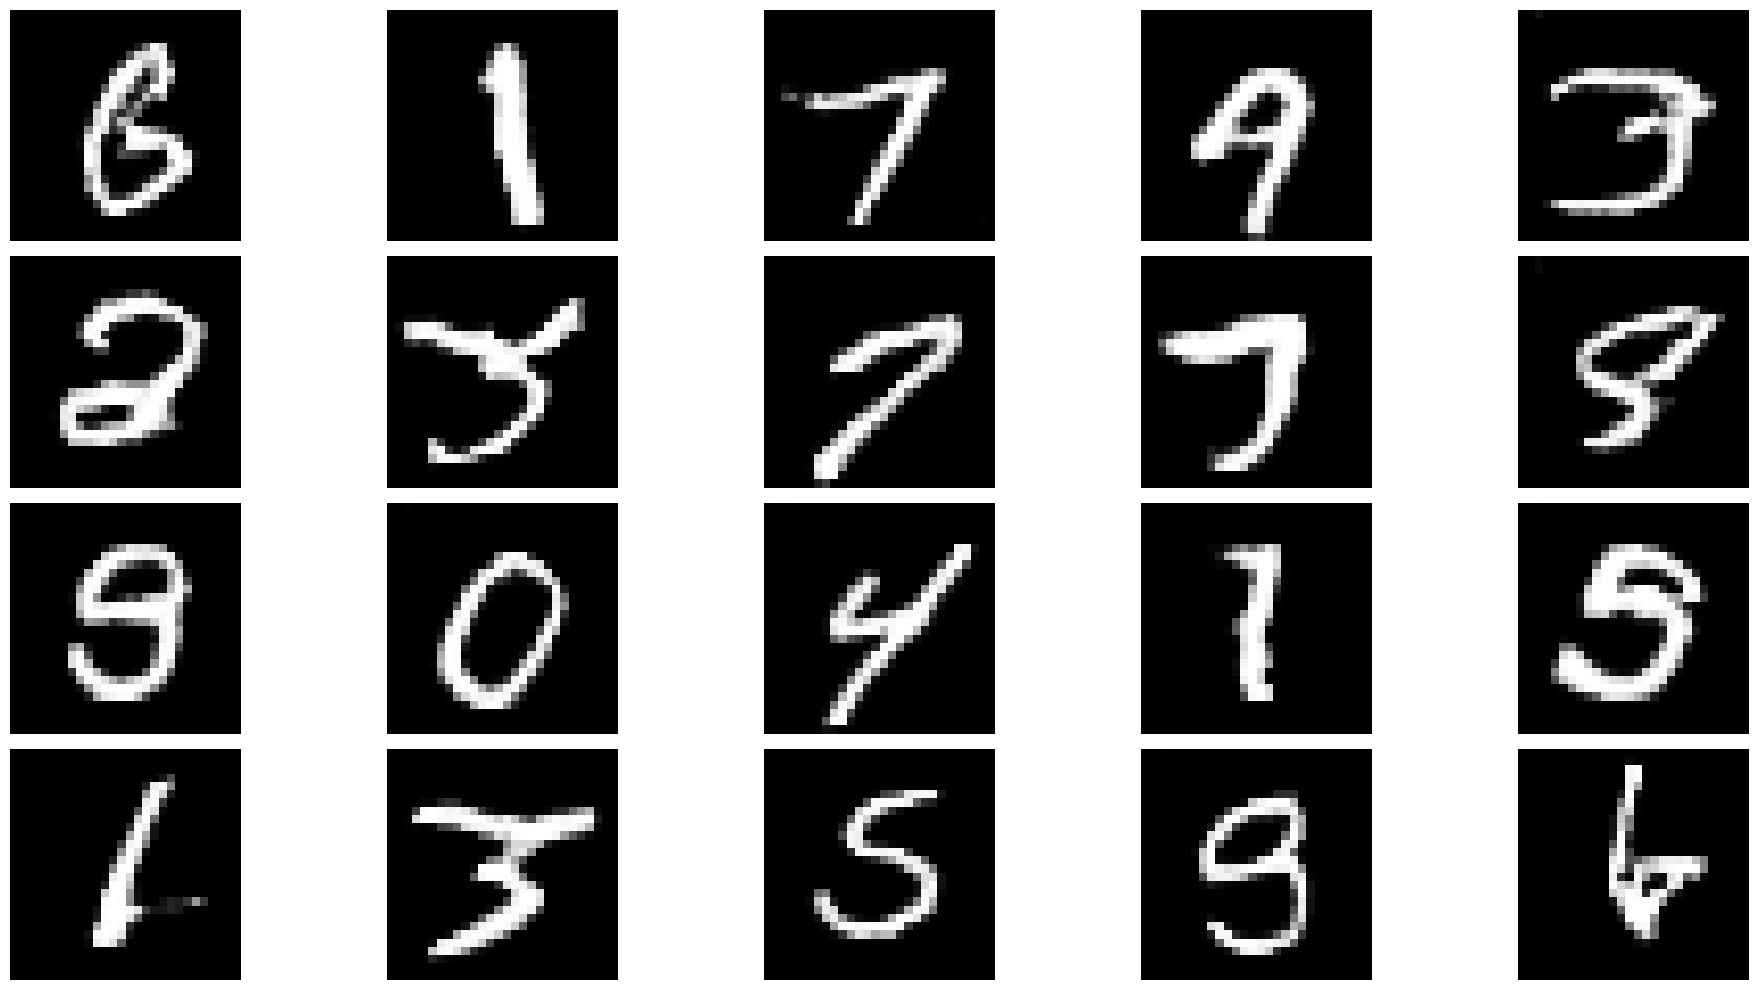

📈 Epoch 20 Summary:
   Train D Loss: 1.0384, Val D Loss: 1.4198
   Train G Loss: 1.1420, Val G Loss: 1.7412

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 1.122572	G_loss: 0.712629
Epoch: 21 [6400/60000 (11%)]	D_loss: 1.089532	G_loss: 1.521830
Epoch: 21 [12800/60000 (21%)]	D_loss: 1.054810	G_loss: 0.866503
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.991312	G_loss: 0.996280
Epoch: 21 [25600/60000 (43%)]	D_loss: 1.107567	G_loss: 1.153516
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.045878	G_loss: 0.744471
Epoch: 21 [38400/60000 (64%)]	D_loss: 1.003356	G_loss: 1.033394
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.933196	G_loss: 1.109862
Epoch: 21 [51200/60000 (85%)]	D_loss: 1.018294	G_loss: 1.193682
Epoch: 21 [57600/60000 (96%)]	D_loss: 1.090151	G_loss: 0.910668
====> Epoch: 21 Train D_loss: 1.0273, Train G_loss: 1.1554
====> Epoch: 21 Val D_loss: 1.1551, Val G_loss: 0.8236
📈 Epoch 21 Summary:
   Train D Loss: 1.0273, Val D Loss: 1.1551
   Train G Loss: 1.1554

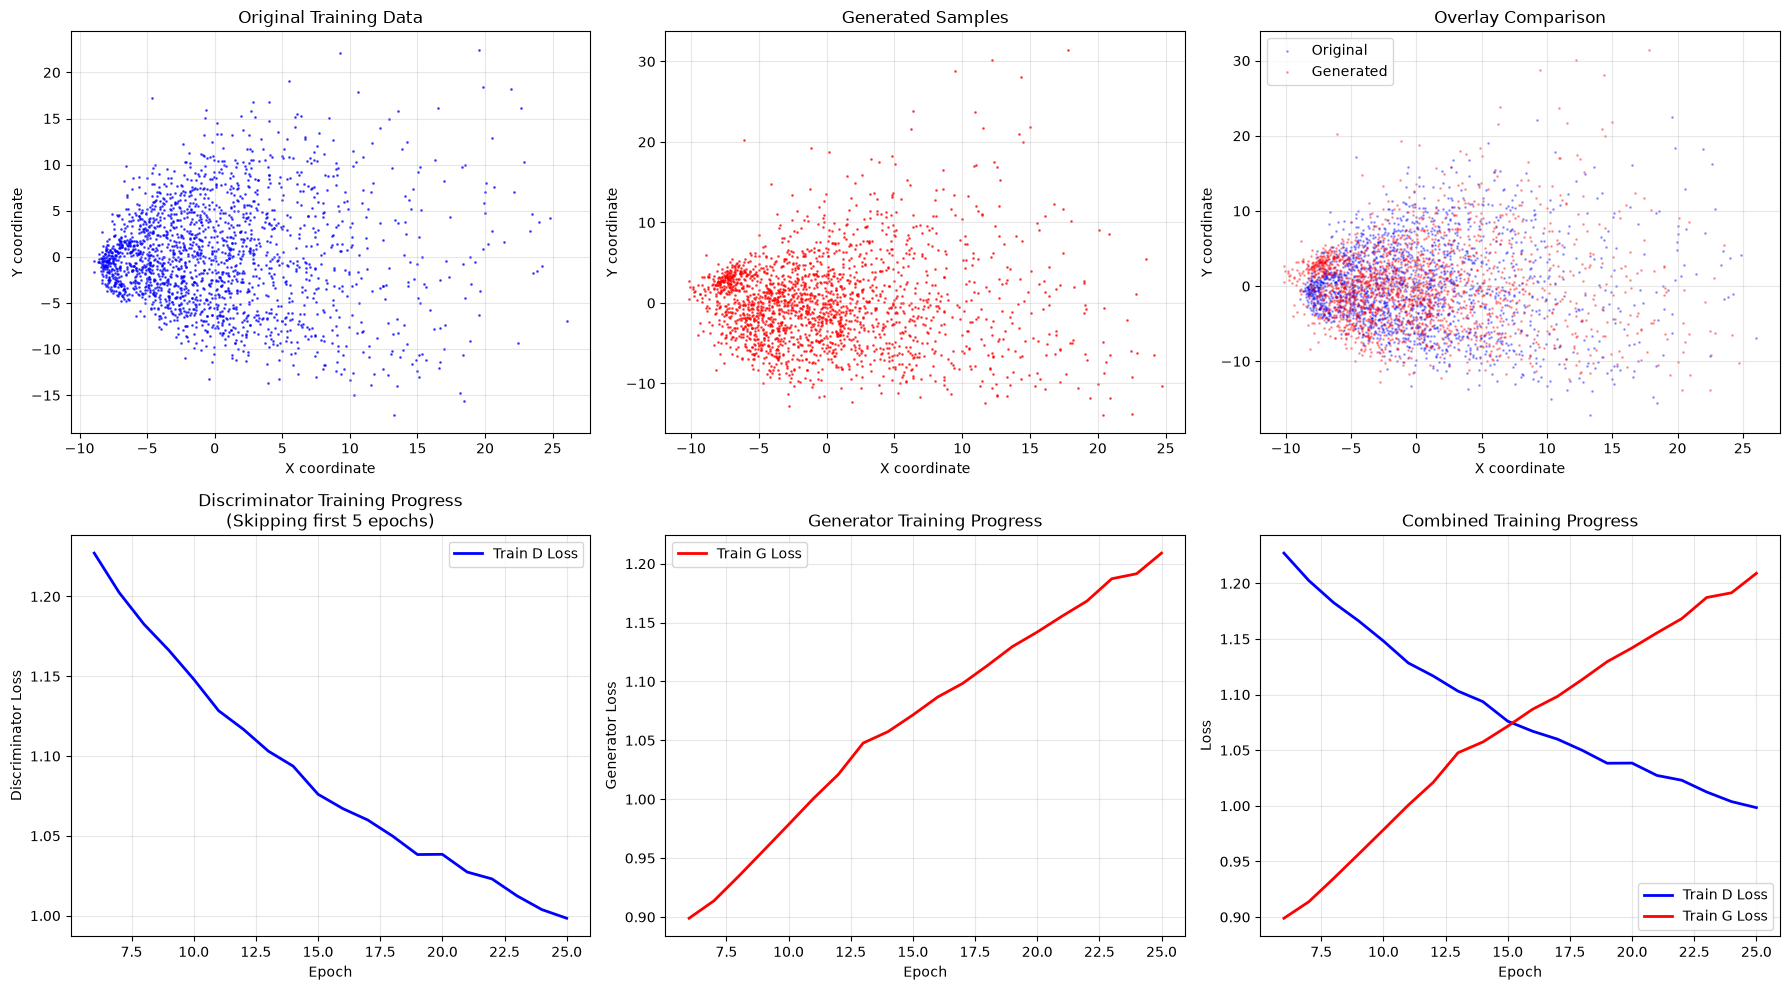

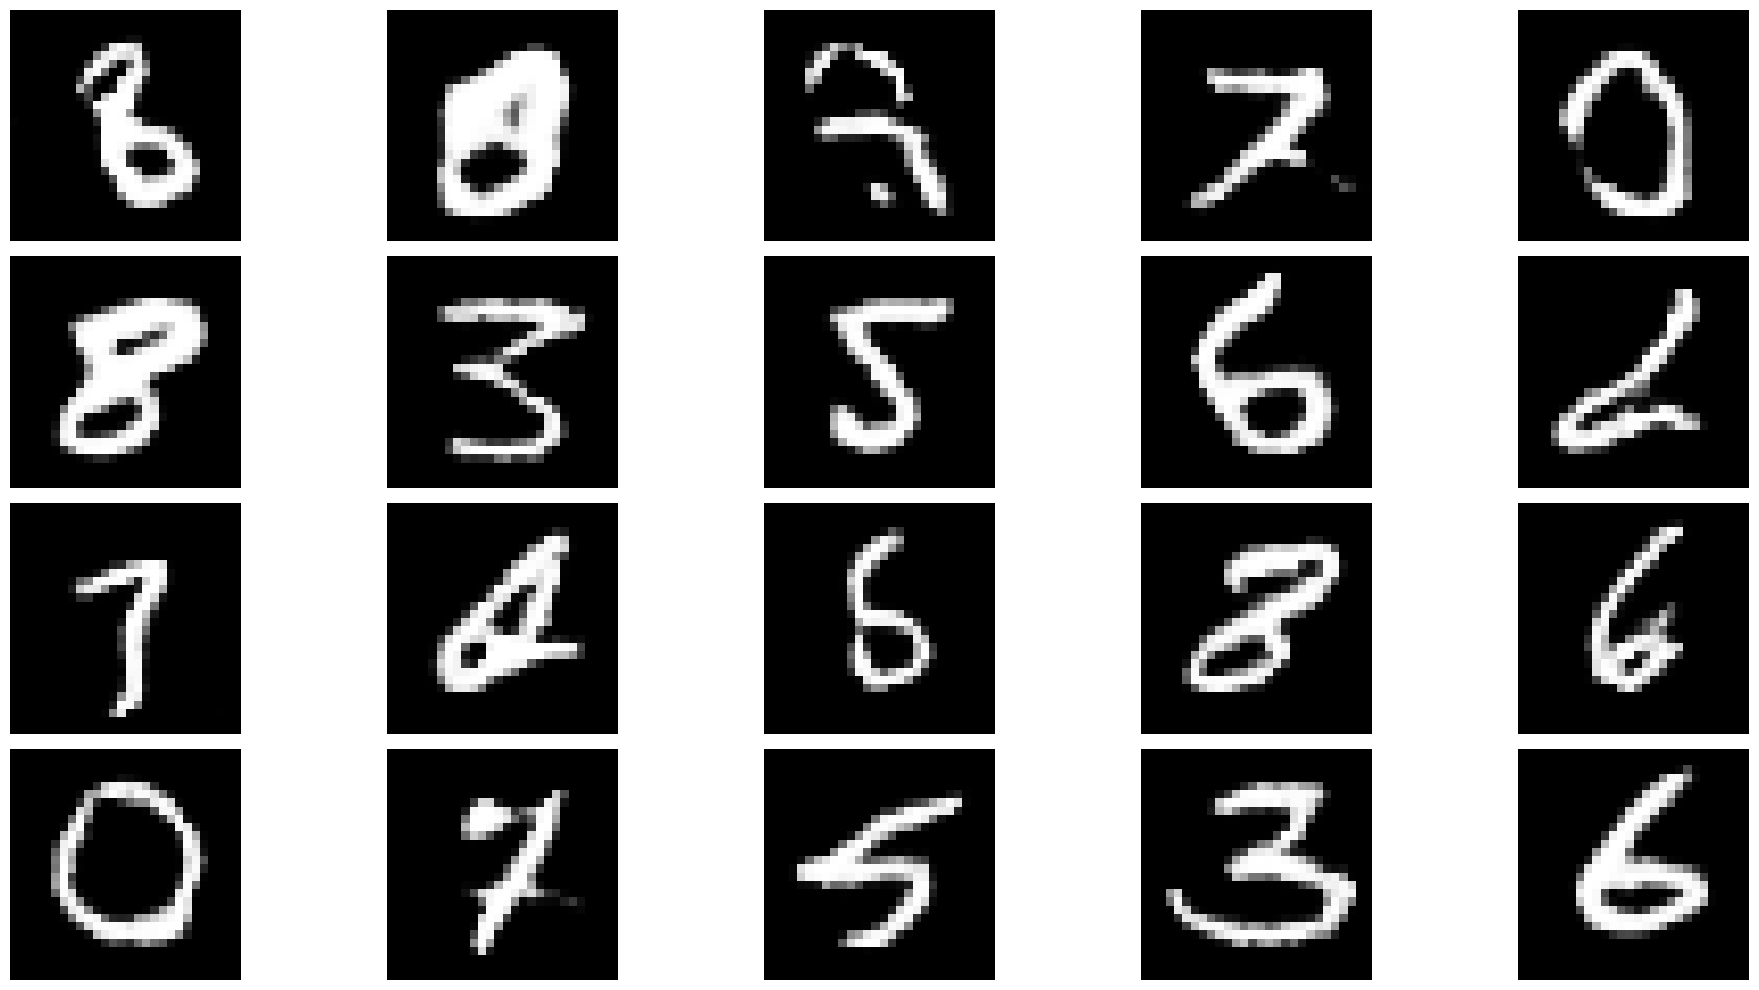

📈 Epoch 25 Summary:
   Train D Loss: 0.9984, Val D Loss: 1.4485
   Train G Loss: 1.2090, Val G Loss: 0.4420

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 1.197147	G_loss: 2.133985
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.877011	G_loss: 1.118427
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.950892	G_loss: 0.651137
Epoch: 26 [19200/60000 (32%)]	D_loss: 1.052178	G_loss: 0.901898
Epoch: 26 [25600/60000 (43%)]	D_loss: 1.076640	G_loss: 0.751799
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.913392	G_loss: 0.809905
Epoch: 26 [38400/60000 (64%)]	D_loss: 1.056517	G_loss: 0.840642
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.925714	G_loss: 0.958446
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.929422	G_loss: 1.127200
Epoch: 26 [57600/60000 (96%)]	D_loss: 1.051841	G_loss: 1.323954
====> Epoch: 26 Train D_loss: 0.9906, Train G_loss: 1.2180
====> Epoch: 26 Val D_loss: 1.1794, Val G_loss: 1.2215
📈 Epoch 26 Summary:
   Train D Loss: 0.9906, Val D Loss: 1.1794
   Train G Loss: 1.2180

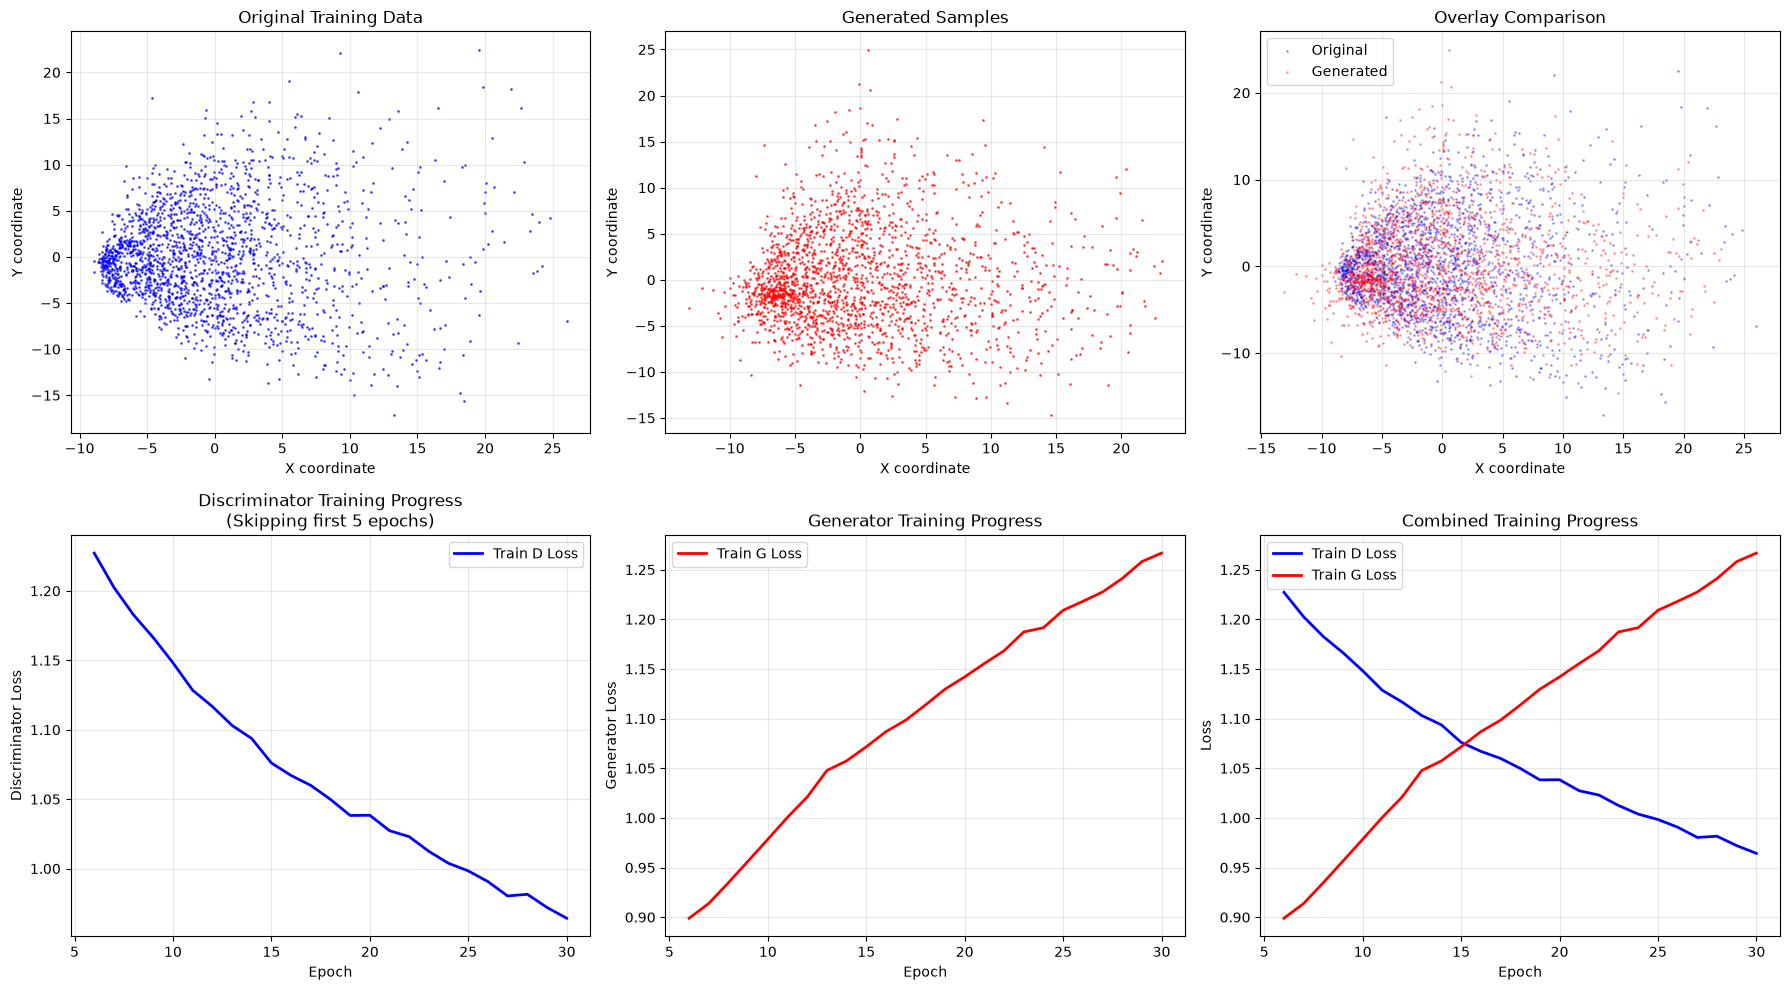

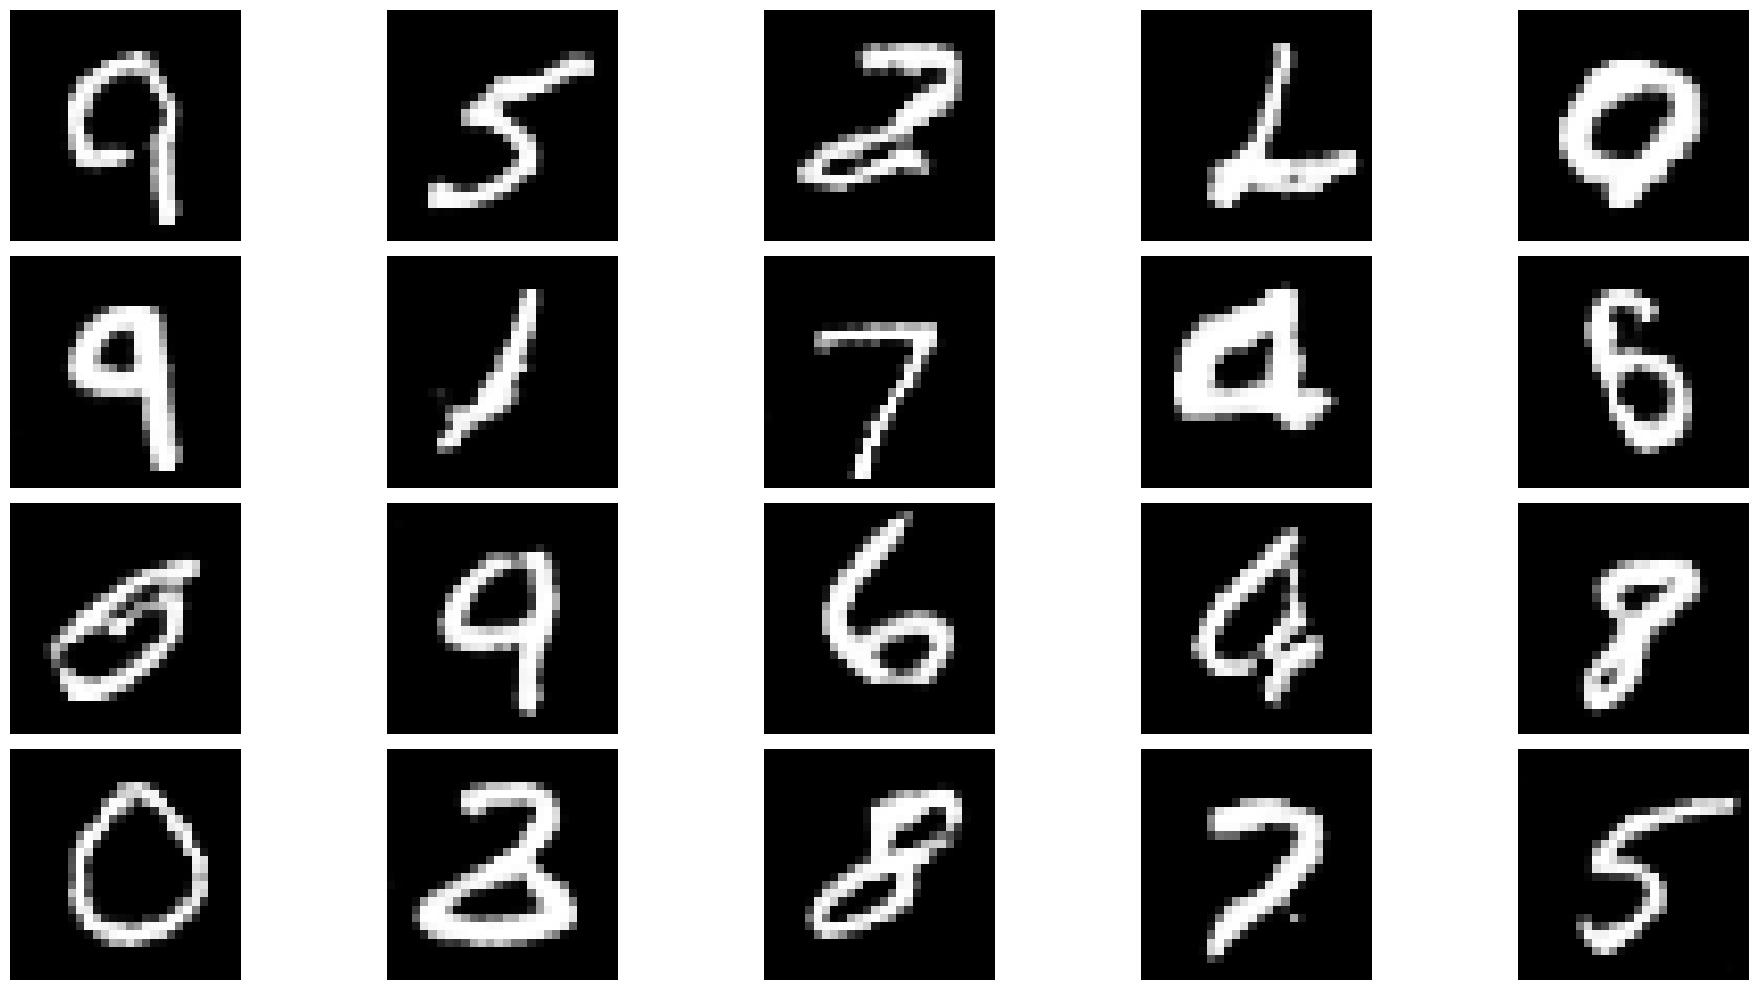

📈 Epoch 30 Summary:
   Train D Loss: 0.9643, Val D Loss: 1.2059
   Train G Loss: 1.2666, Val G Loss: 0.6847

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.944033	G_loss: 1.581717
Epoch: 31 [6400/60000 (11%)]	D_loss: 1.083901	G_loss: 1.855390
Epoch: 31 [12800/60000 (21%)]	D_loss: 1.028983	G_loss: 0.797117
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.921993	G_loss: 1.639600
Epoch: 31 [25600/60000 (43%)]	D_loss: 1.013306	G_loss: 1.457522
Epoch: 31 [32000/60000 (53%)]	D_loss: 1.045820	G_loss: 0.996578
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.993267	G_loss: 1.420357
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.953019	G_loss: 1.107347
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.870910	G_loss: 1.012788
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.880243	G_loss: 1.901734
====> Epoch: 31 Train D_loss: 0.9646, Train G_loss: 1.2701
====> Epoch: 31 Val D_loss: 1.2423, Val G_loss: 1.4382
📈 Epoch 31 Summary:
   Train D Loss: 0.9646, Val D Loss: 1.2423
   Train G Loss: 1.2701

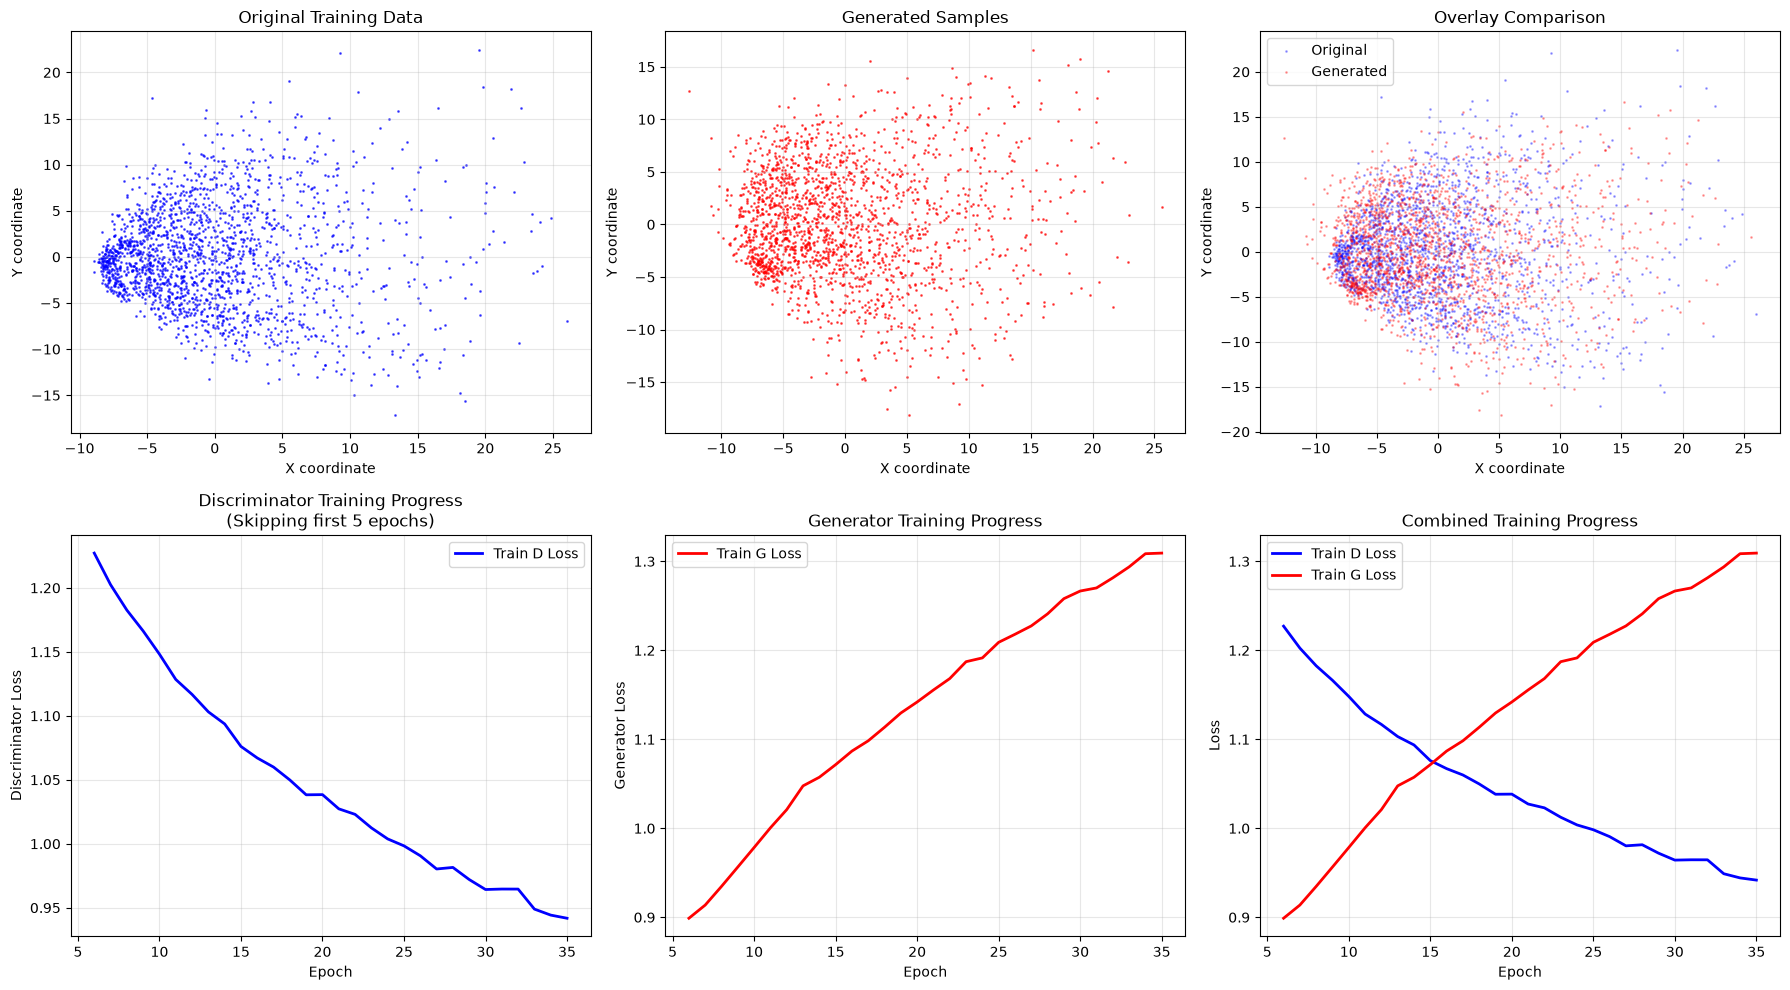

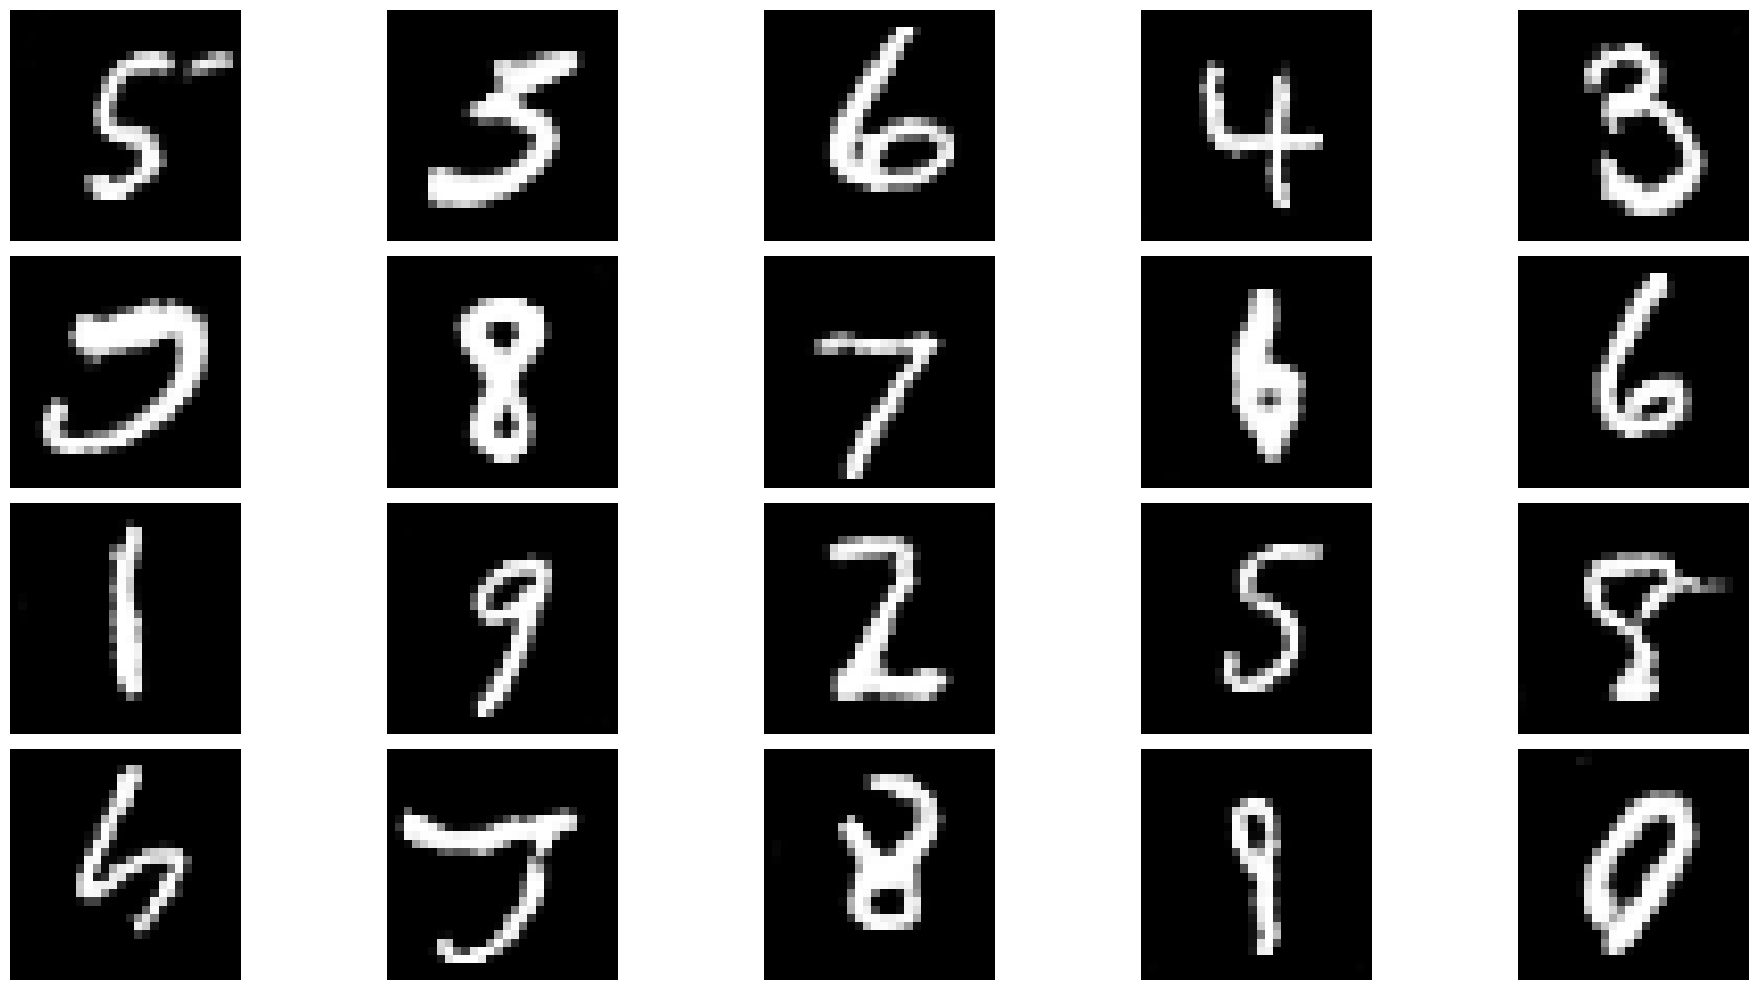

📈 Epoch 35 Summary:
   Train D Loss: 0.9418, Val D Loss: 1.1192
   Train G Loss: 1.3093, Val G Loss: 1.1343

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.777313	G_loss: 1.936163
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.852219	G_loss: 1.461615
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.942303	G_loss: 2.322943
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.820690	G_loss: 1.200727
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.954646	G_loss: 0.977229
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.914928	G_loss: 0.859130
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.817708	G_loss: 1.473716
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.812579	G_loss: 1.232419
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.870305	G_loss: 1.325309
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.855767	G_loss: 1.367964
====> Epoch: 36 Train D_loss: 0.9338, Train G_loss: 1.3243
====> Epoch: 36 Val D_loss: 1.1649, Val G_loss: 1.2810
📈 Epoch 36 Summary:
   Train D Loss: 0.9338, Val D Loss: 1.1649
   Train G Loss: 1.3243

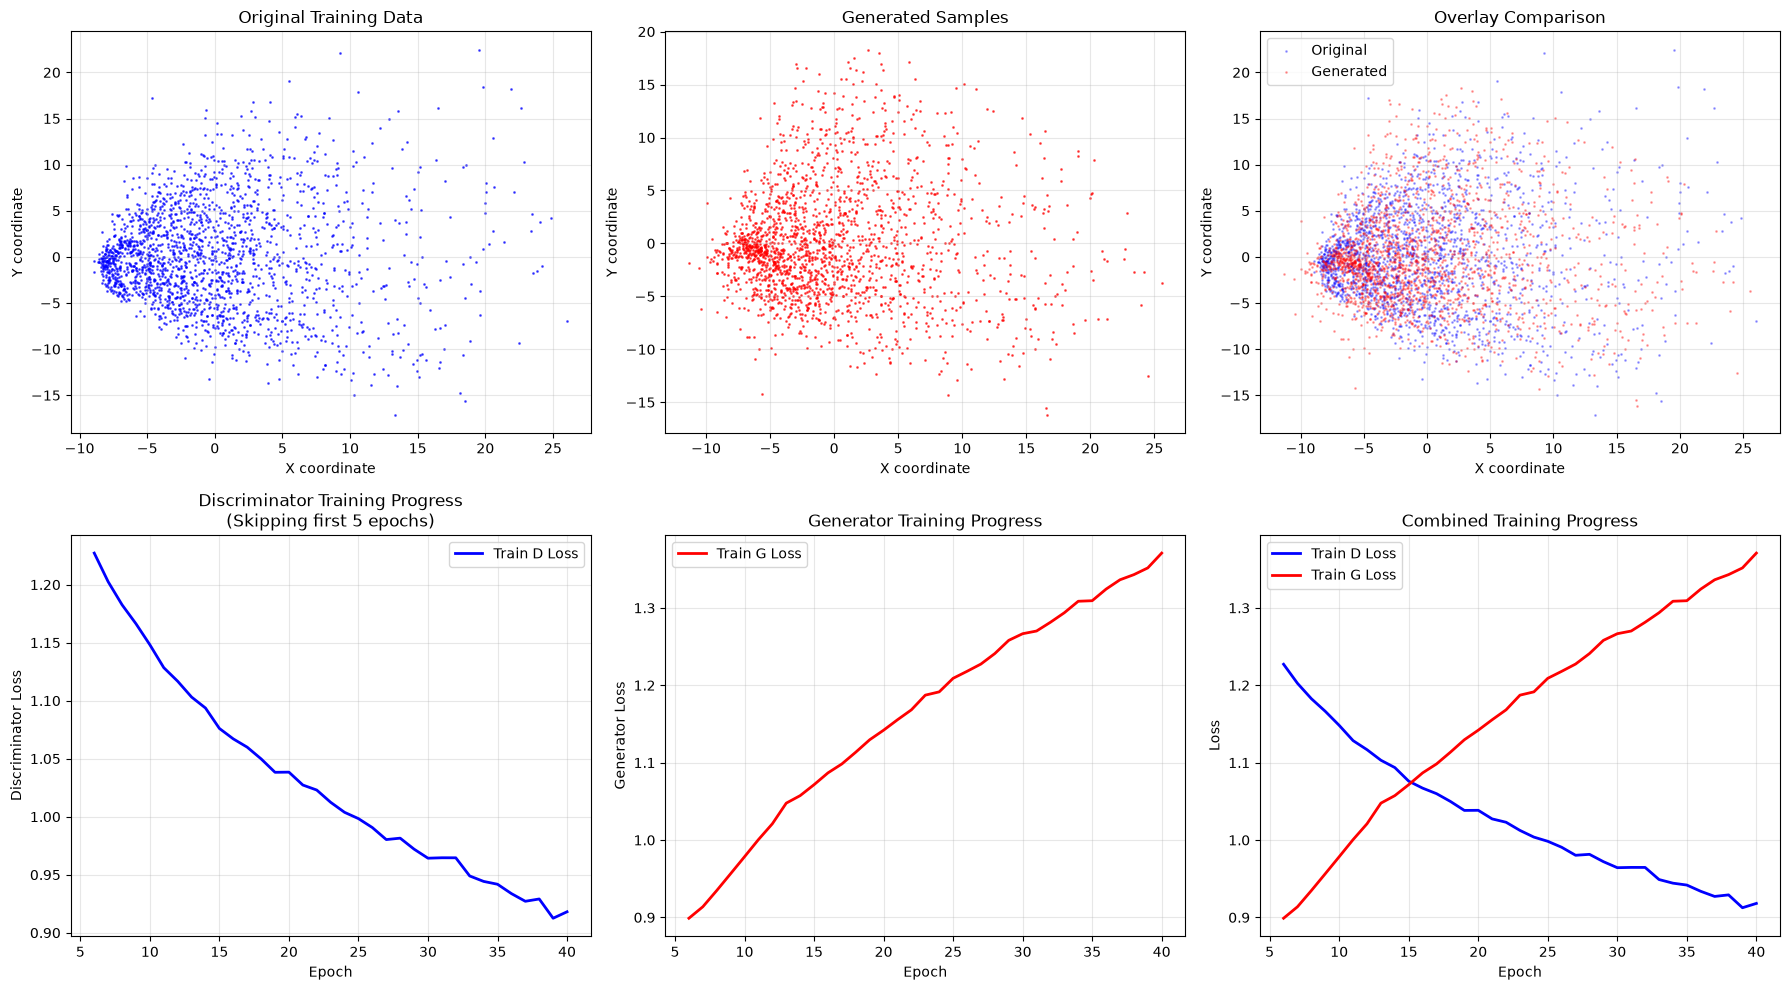

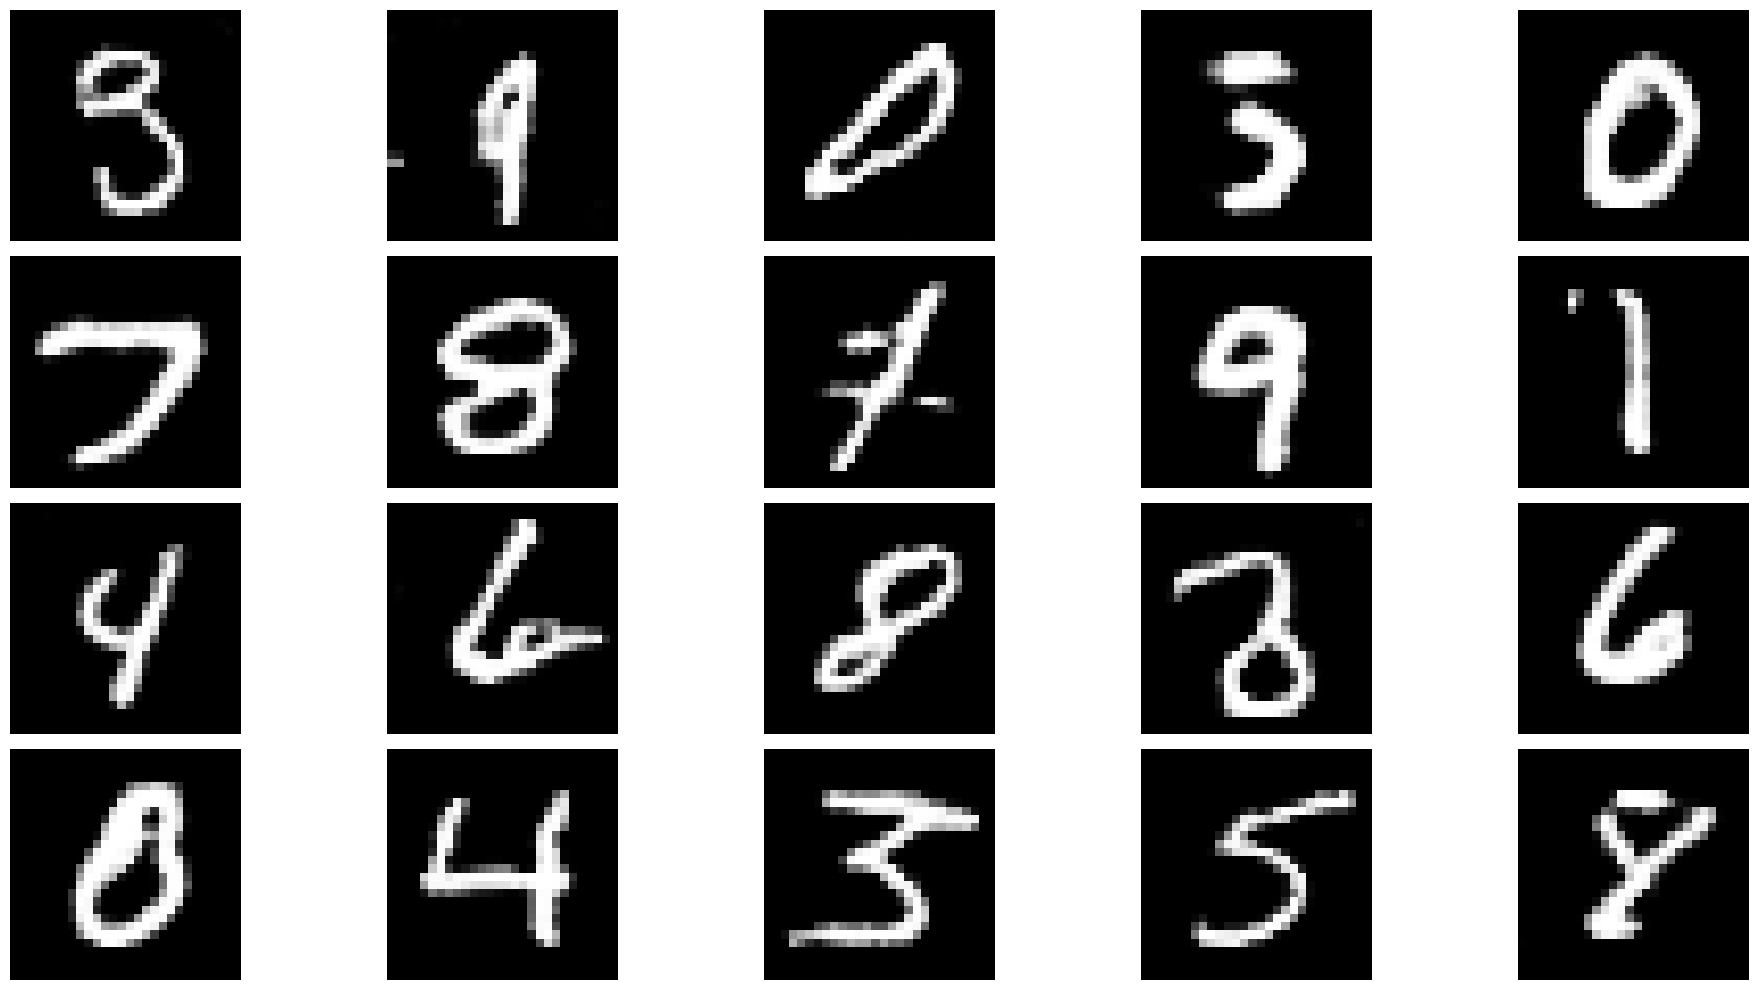

📈 Epoch 40 Summary:
   Train D Loss: 0.9181, Val D Loss: 1.0876
   Train G Loss: 1.3708, Val G Loss: 0.9579

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.793815	G_loss: 1.133314
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.794427	G_loss: 0.956888
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.907516	G_loss: 1.044297
Epoch: 41 [19200/60000 (32%)]	D_loss: 1.178947	G_loss: 2.191456
Epoch: 41 [25600/60000 (43%)]	D_loss: 1.027312	G_loss: 2.188747
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.867941	G_loss: 1.782445
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.816824	G_loss: 1.438541
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.793726	G_loss: 1.319744
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.977173	G_loss: 2.265112
Epoch: 41 [57600/60000 (96%)]	D_loss: 1.022343	G_loss: 1.646212
====> Epoch: 41 Train D_loss: 0.9093, Train G_loss: 1.3718
====> Epoch: 41 Val D_loss: 1.1565, Val G_loss: 1.2669
📈 Epoch 41 Summary:
   Train D Loss: 0.9093, Val D Loss: 1.1565
   Train G Loss: 1.3718

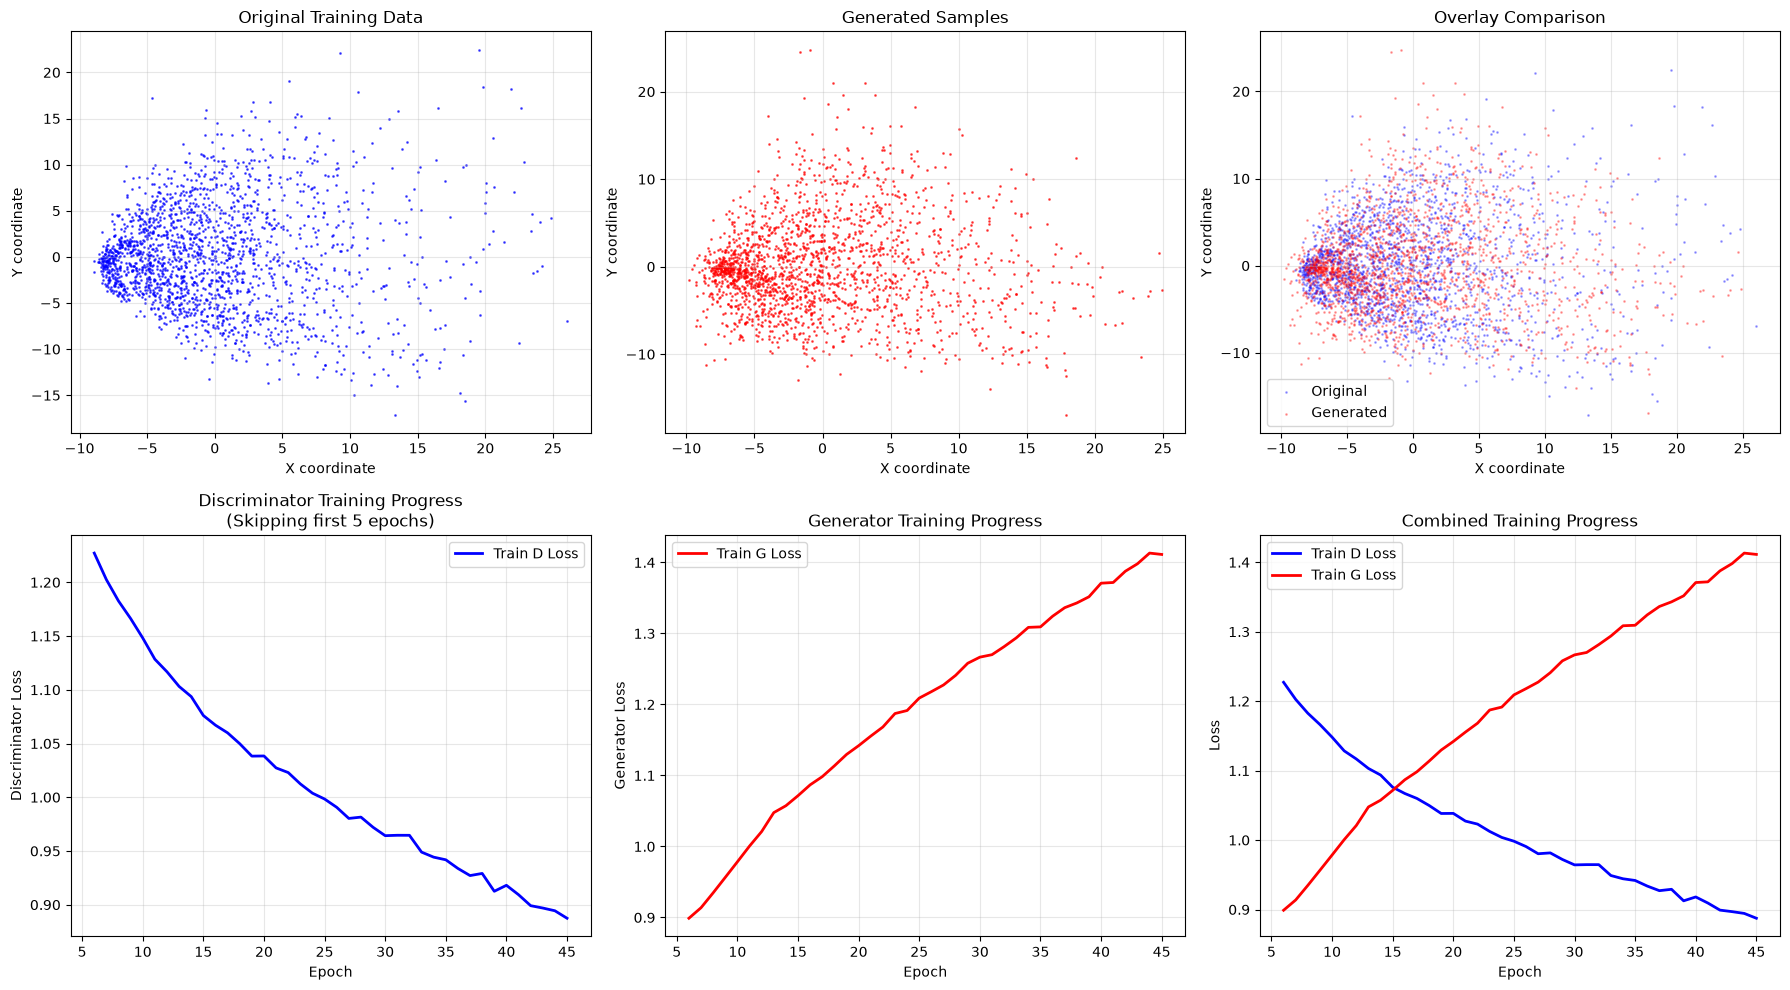

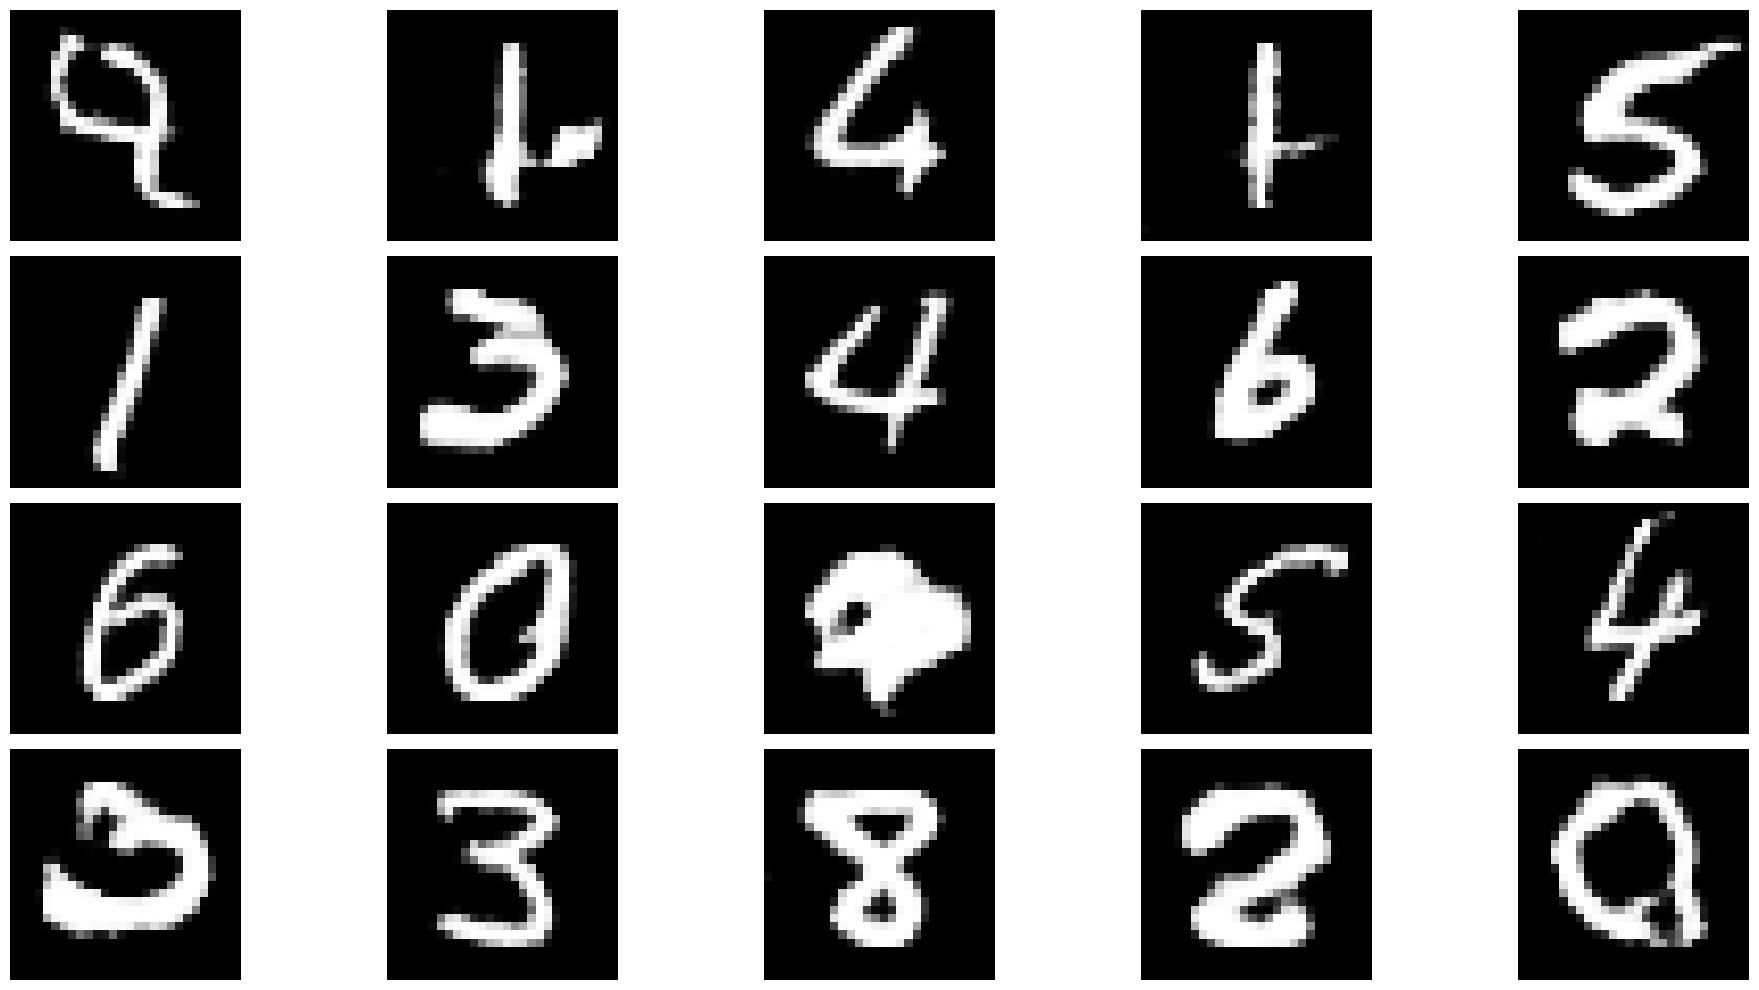

📈 Epoch 45 Summary:
   Train D Loss: 0.8874, Val D Loss: 1.1464
   Train G Loss: 1.4113, Val G Loss: 0.8766

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.965047	G_loss: 1.405572
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.949076	G_loss: 0.949220
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.921088	G_loss: 1.902255
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.856947	G_loss: 1.241003
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.947487	G_loss: 2.225080
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.794217	G_loss: 1.575465
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.883774	G_loss: 0.683251
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.988802	G_loss: 1.014056
Epoch: 46 [51200/60000 (85%)]	D_loss: 1.043839	G_loss: 2.308629
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.760914	G_loss: 1.583545
====> Epoch: 46 Train D_loss: 0.8851, Train G_loss: 1.4318
====> Epoch: 46 Val D_loss: 1.1180, Val G_loss: 0.9875
📈 Epoch 46 Summary:
   Train D Loss: 0.8851, Val D Loss: 1.1180
   Train G Loss: 1.4318

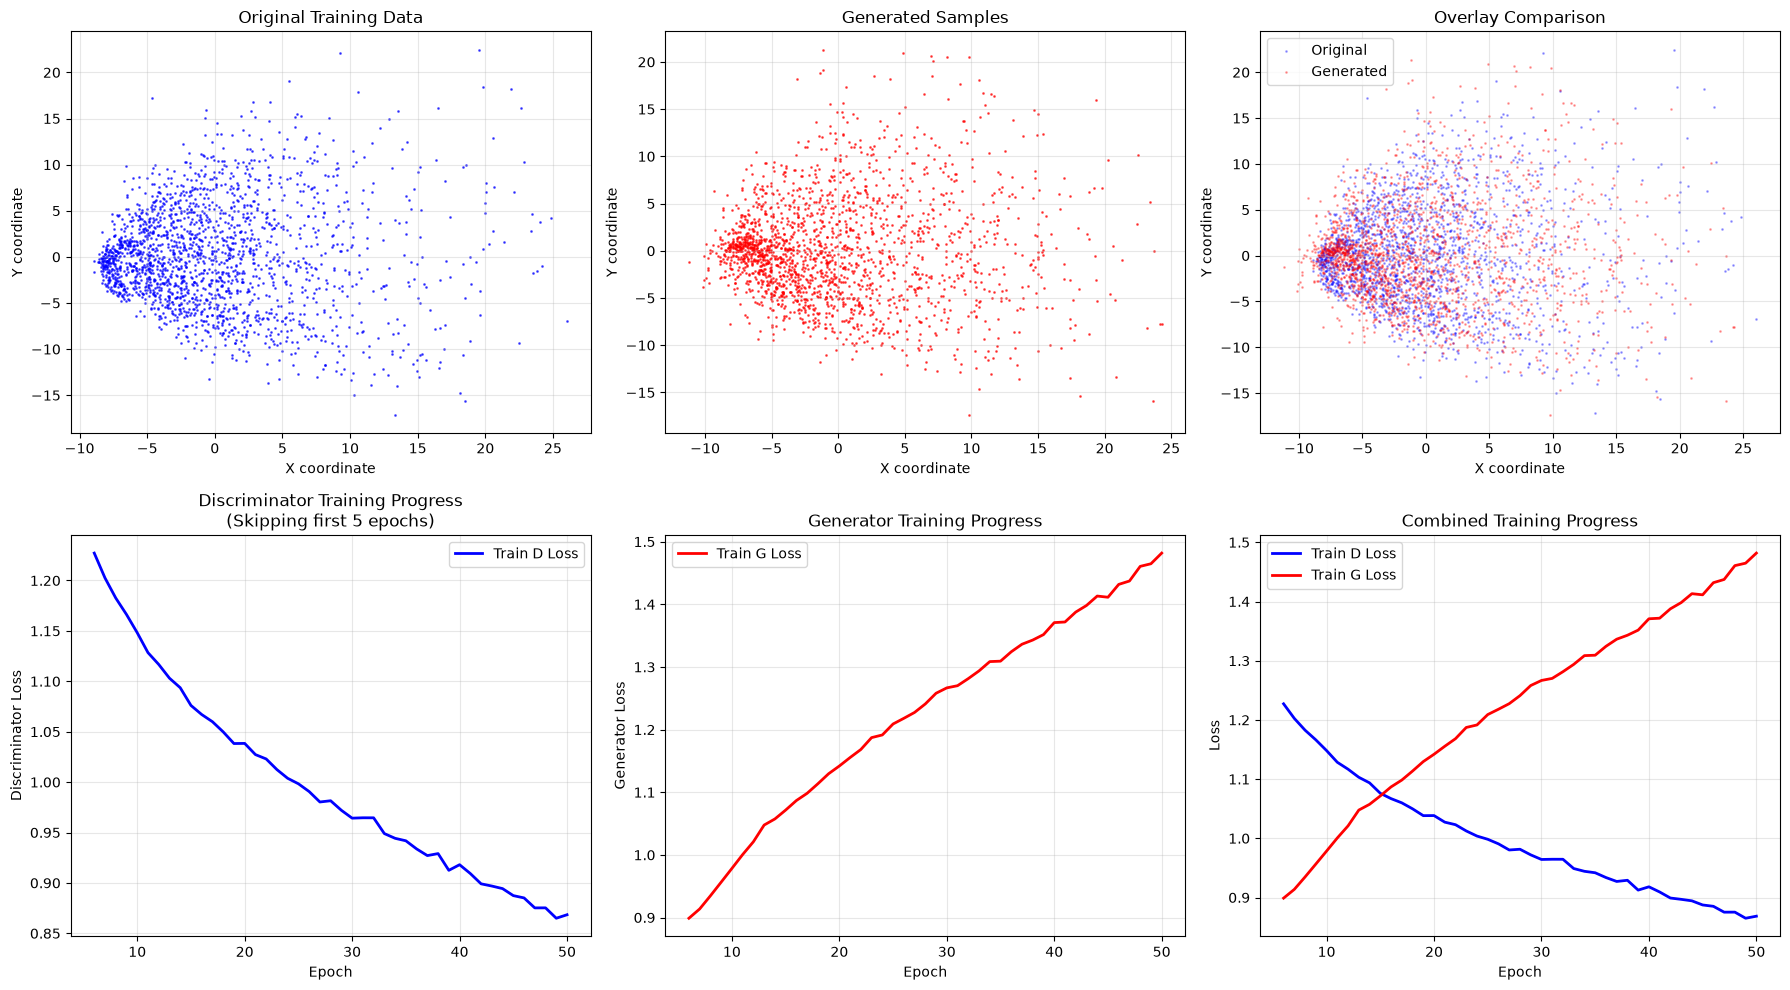

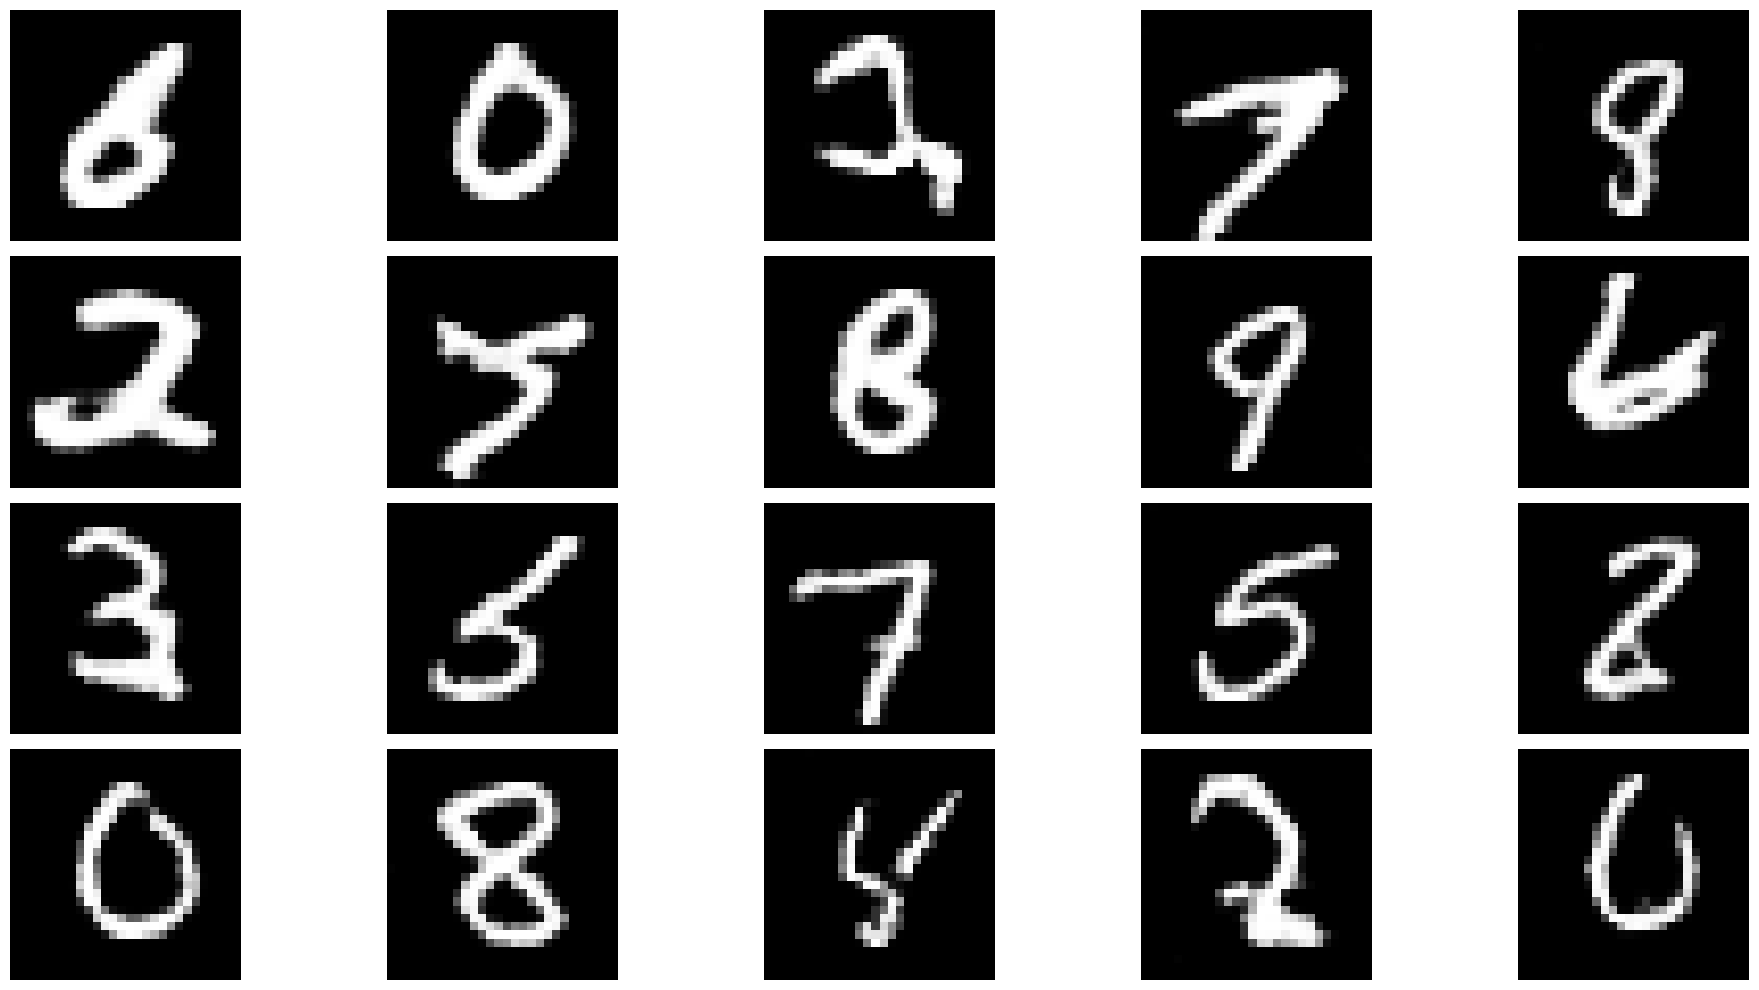

📈 Epoch 50 Summary:
   Train D Loss: 0.8685, Val D Loss: 1.1183
   Train G Loss: 1.4818, Val G Loss: 0.9882

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.719899	G_loss: 1.492529
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.865591	G_loss: 1.019997
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.779823	G_loss: 1.856252
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.989012	G_loss: 0.764281
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.815546	G_loss: 1.309672
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.917269	G_loss: 0.951997
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.762231	G_loss: 1.622918
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.985761	G_loss: 0.972778
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.836625	G_loss: 1.693911
Epoch: 51 [57600/60000 (96%)]	D_loss: 1.474684	G_loss: 0.479539
====> Epoch: 51 Train D_loss: 0.8581, Train G_loss: 1.4952
====> Epoch: 51 Val D_loss: 1.1552, Val G_loss: 0.8872
📈 Epoch 51 Summary:
   Train D Loss: 0.8581, Val D Loss: 1.1552
   Train G Loss: 1.4952

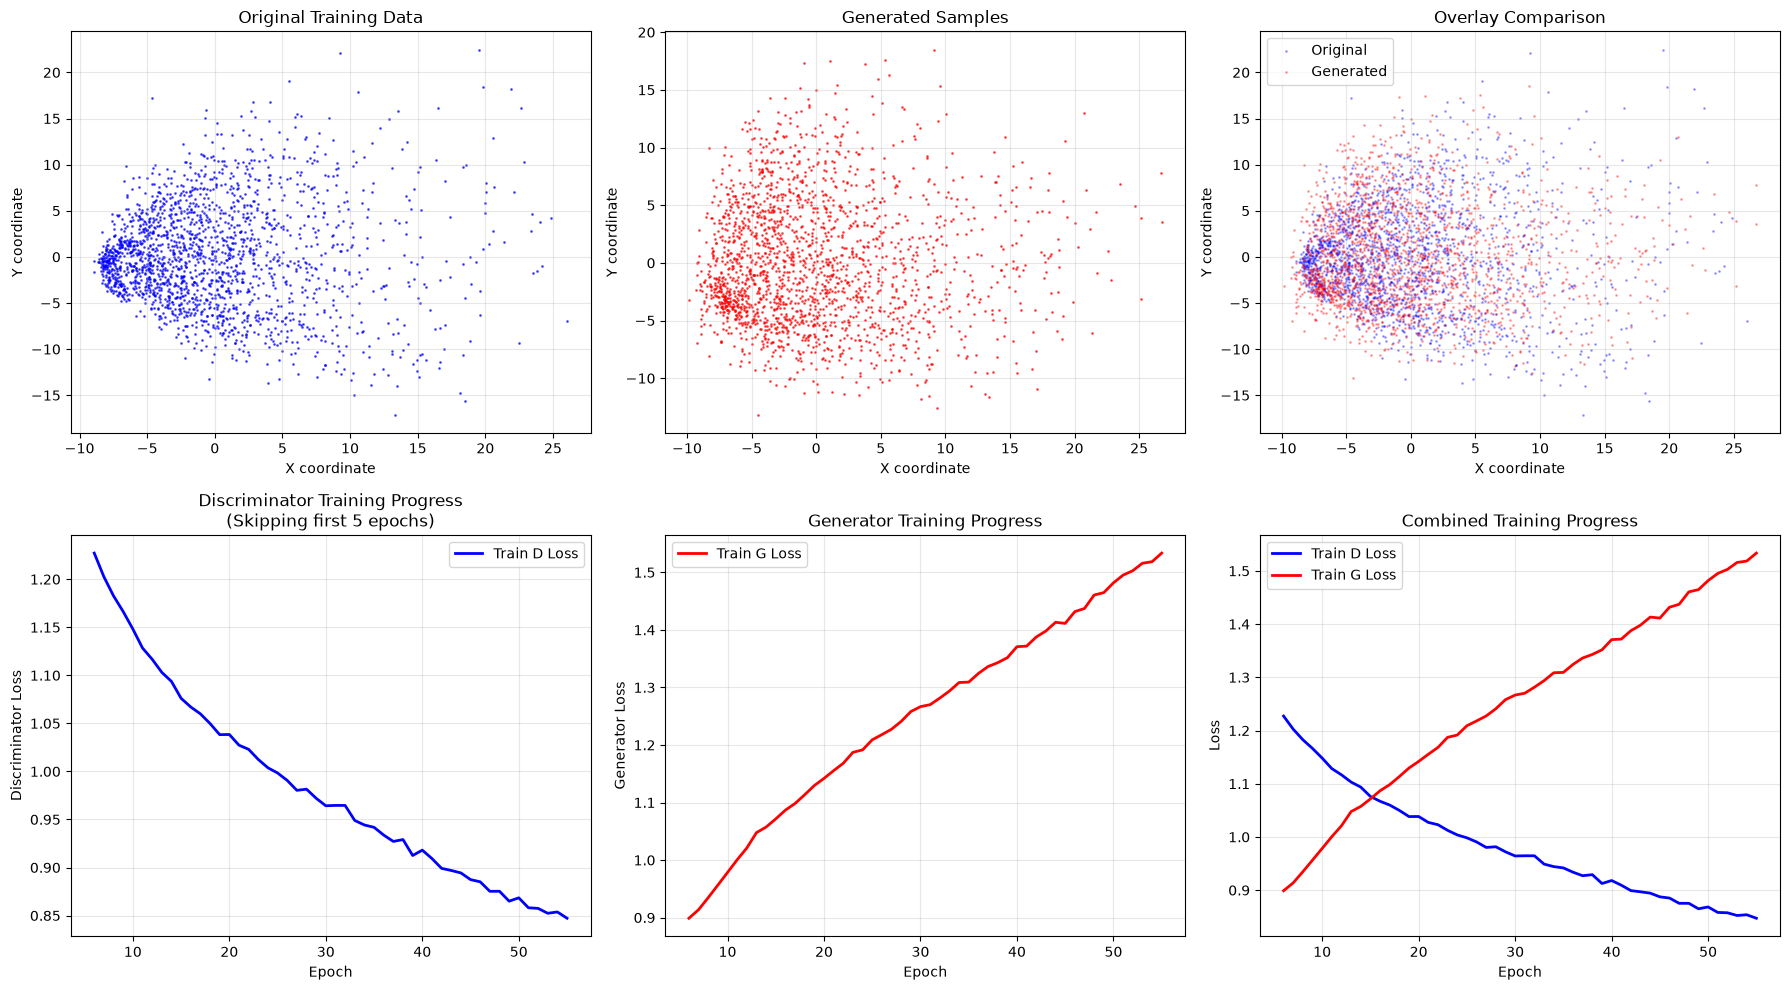

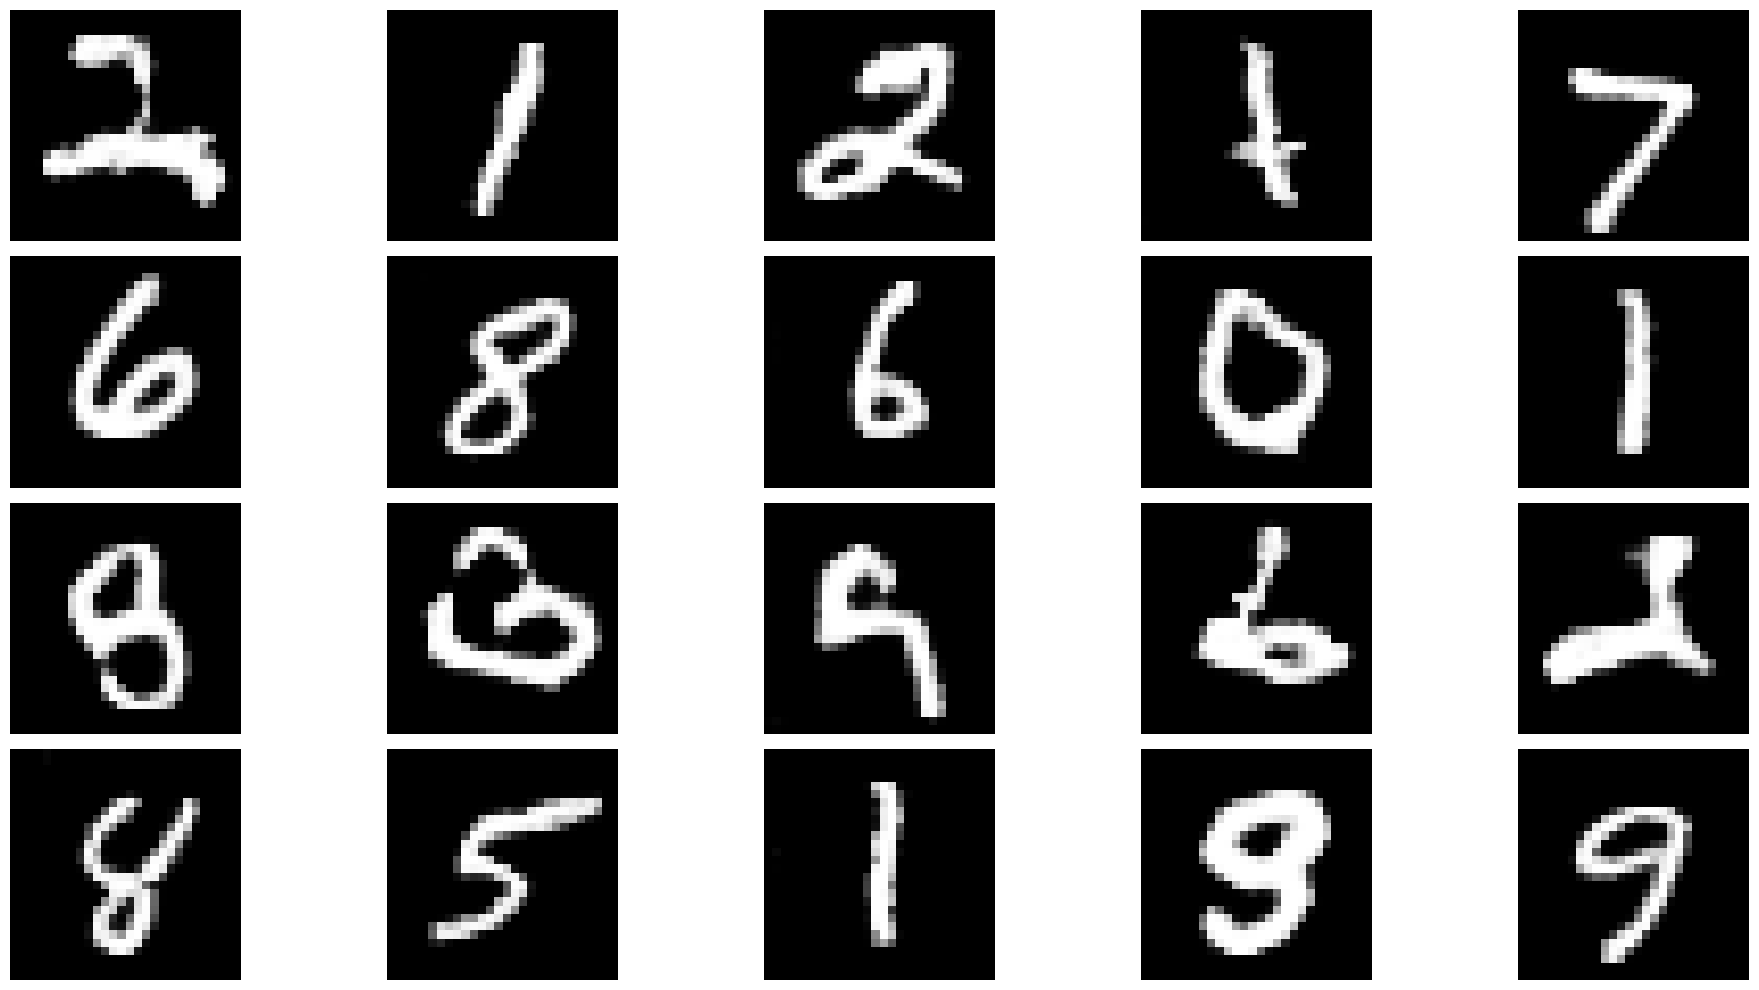

📈 Epoch 55 Summary:
   Train D Loss: 0.8472, Val D Loss: 1.4507
   Train G Loss: 1.5335, Val G Loss: 2.1564

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 1.043303	G_loss: 0.915369
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.791873	G_loss: 1.732925
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.803633	G_loss: 1.551488
Epoch: 56 [19200/60000 (32%)]	D_loss: 1.082293	G_loss: 2.197881
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.825166	G_loss: 1.125098
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.978922	G_loss: 2.121431
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.748679	G_loss: 1.715990
Epoch: 56 [44800/60000 (75%)]	D_loss: 1.069981	G_loss: 1.153180
Epoch: 56 [51200/60000 (85%)]	D_loss: 1.011576	G_loss: 2.070347
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.841449	G_loss: 1.394216
====> Epoch: 56 Train D_loss: 0.8356, Train G_loss: 1.5301
====> Epoch: 56 Val D_loss: 1.2920, Val G_loss: 0.6042
📈 Epoch 56 Summary:
   Train D Loss: 0.8356, Val D Loss: 1.2920
   Train G Loss: 1.5301

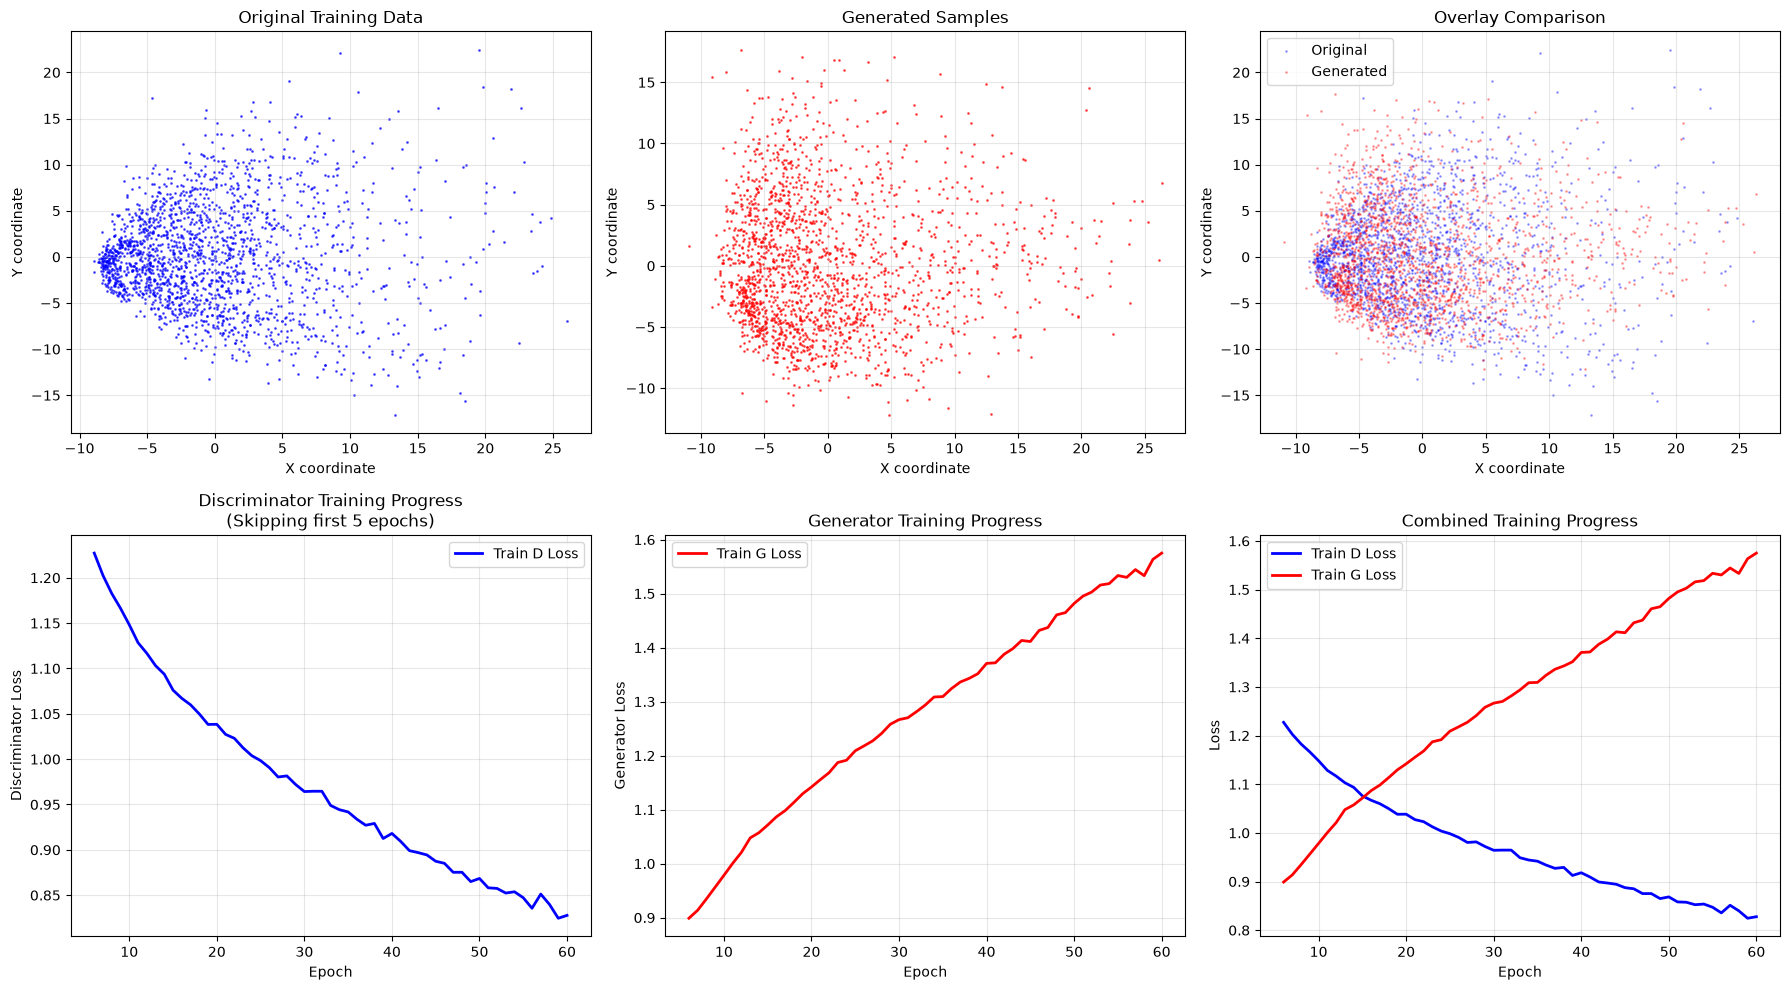

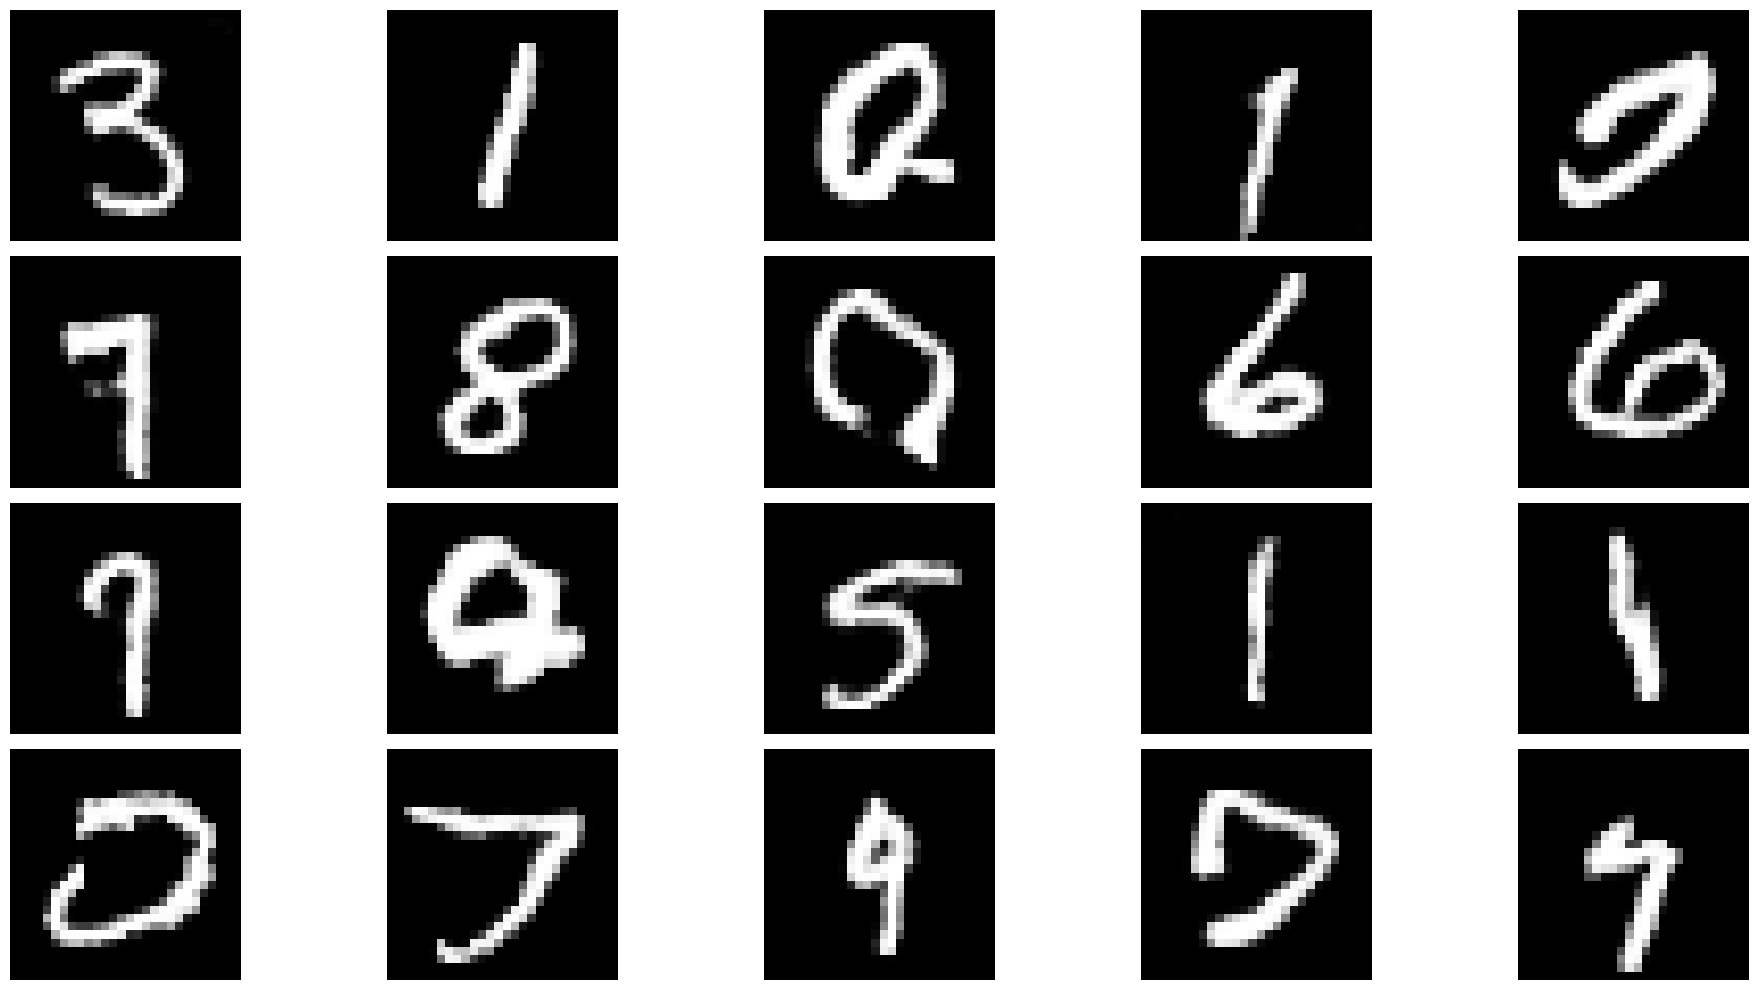

📈 Epoch 60 Summary:
   Train D Loss: 0.8277, Val D Loss: 1.2926
   Train G Loss: 1.5750, Val G Loss: 1.8871

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.832276	G_loss: 0.942768
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.804118	G_loss: 2.017154
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.984421	G_loss: 0.630823
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.765163	G_loss: 1.759366
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.983850	G_loss: 2.132419
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.937135	G_loss: 1.007393
Epoch: 61 [38400/60000 (64%)]	D_loss: 1.154783	G_loss: 0.613913
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.735358	G_loss: 1.357795
Epoch: 61 [51200/60000 (85%)]	D_loss: 1.296347	G_loss: 3.527651
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.716523	G_loss: 1.305070
====> Epoch: 61 Train D_loss: 0.8279, Train G_loss: 1.5739
====> Epoch: 61 Val D_loss: 1.3820, Val G_loss: 0.5587
📈 Epoch 61 Summary:
   Train D Loss: 0.8279, Val D Loss: 1.3820
   Train G Loss: 1.5739

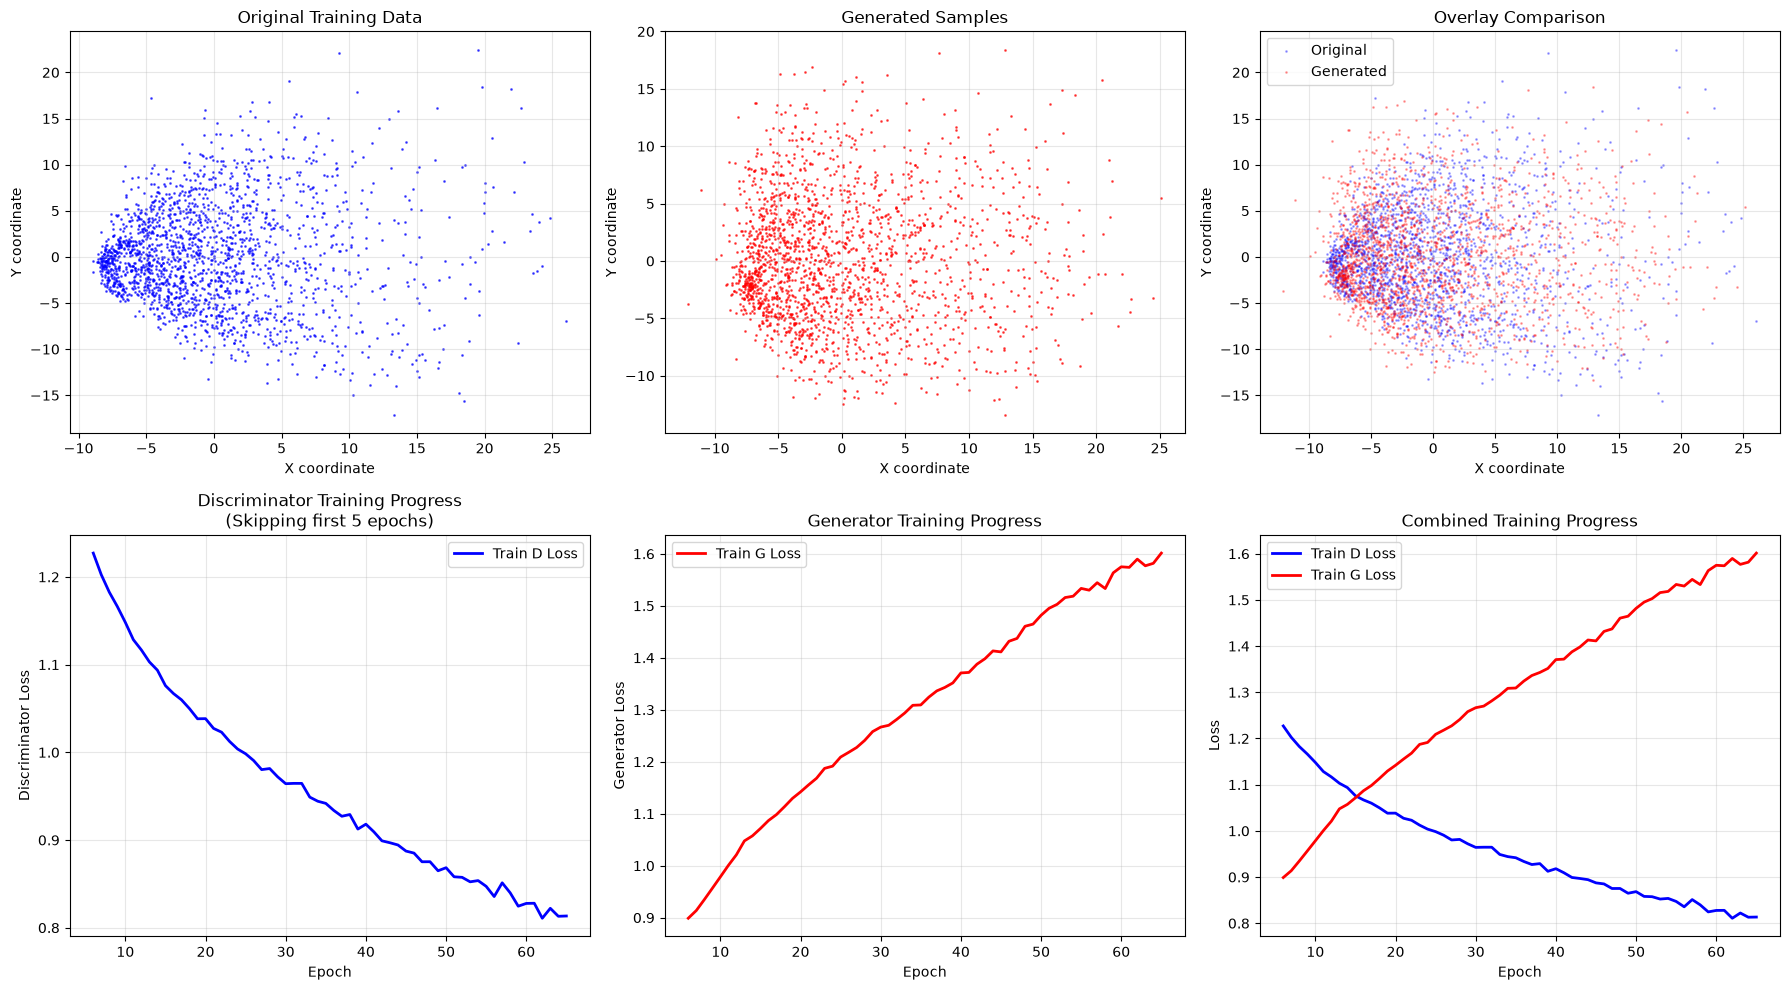

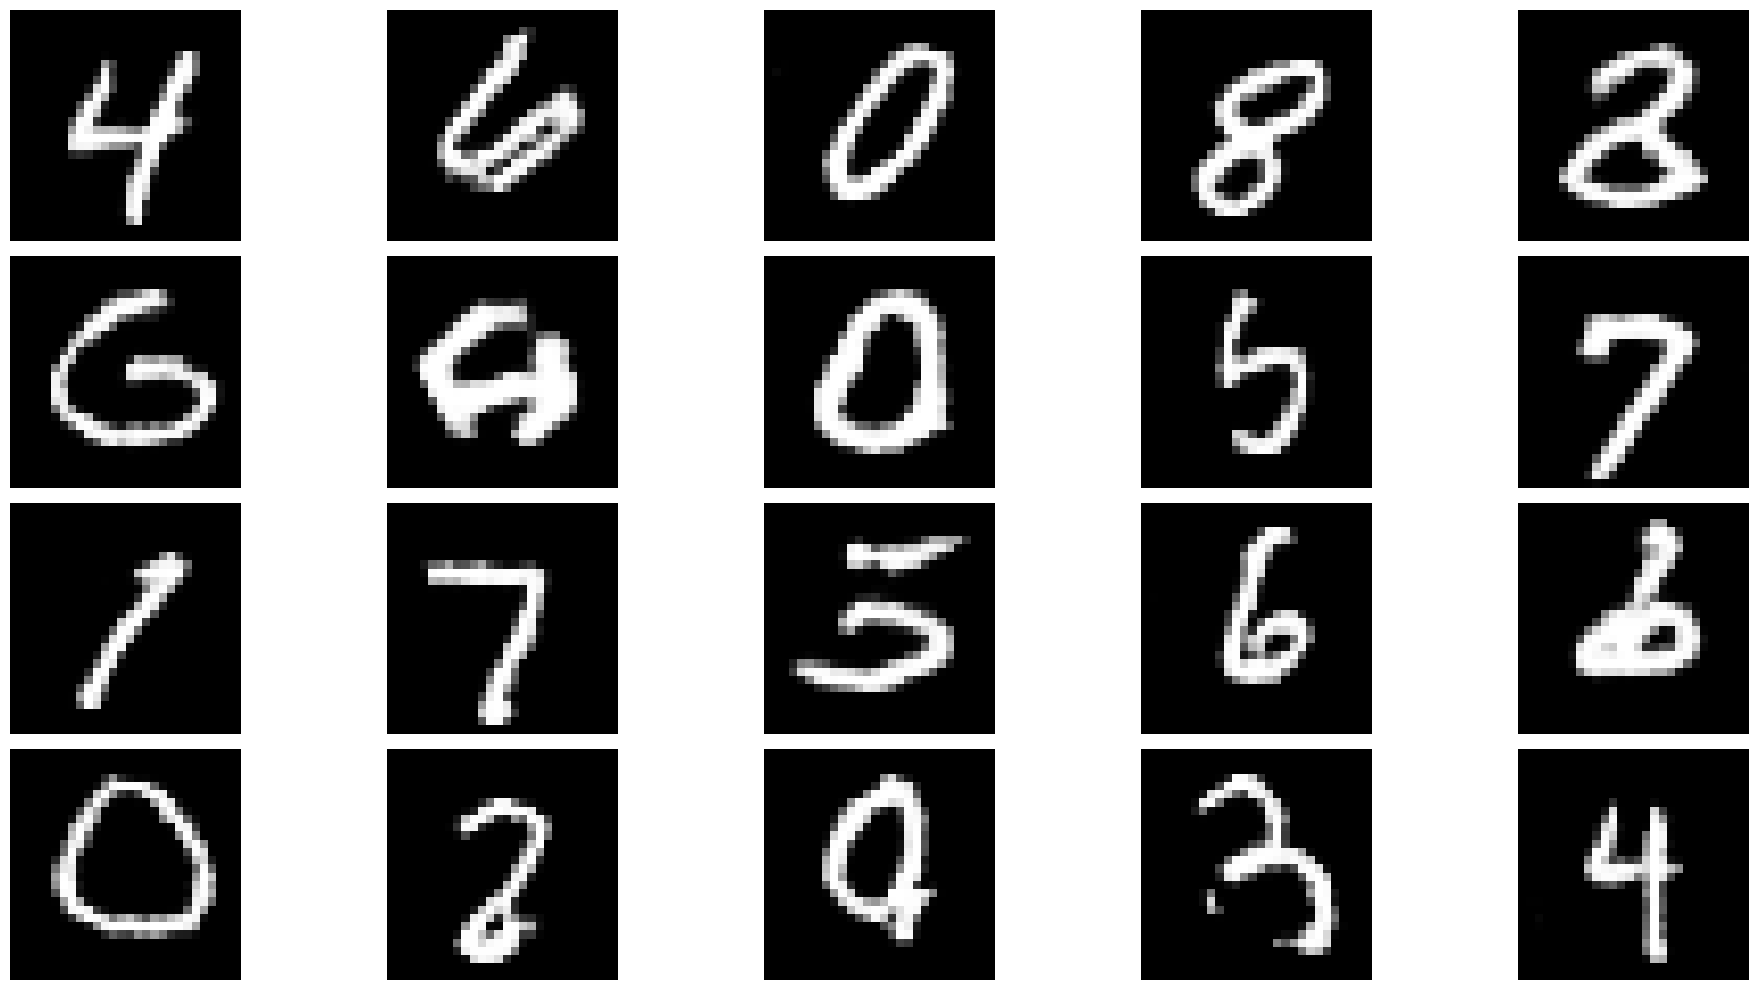

📈 Epoch 65 Summary:
   Train D Loss: 0.8134, Val D Loss: 1.1217
   Train G Loss: 1.6014, Val G Loss: 1.5238

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.688573	G_loss: 1.993118
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.759127	G_loss: 1.662122
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.908525	G_loss: 2.014029
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.680130	G_loss: 1.436802
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.806471	G_loss: 1.285994
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.687184	G_loss: 1.737225
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.694525	G_loss: 2.092136
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.798923	G_loss: 1.829440
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.667329	G_loss: 1.639920
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.839894	G_loss: 2.906487
====> Epoch: 66 Train D_loss: 0.8011, Train G_loss: 1.6133
====> Epoch: 66 Val D_loss: 1.4481, Val G_loss: 2.3022
📈 Epoch 66 Summary:
   Train D Loss: 0.8011, Val D Loss: 1.4481
   Train G Loss: 1.6133

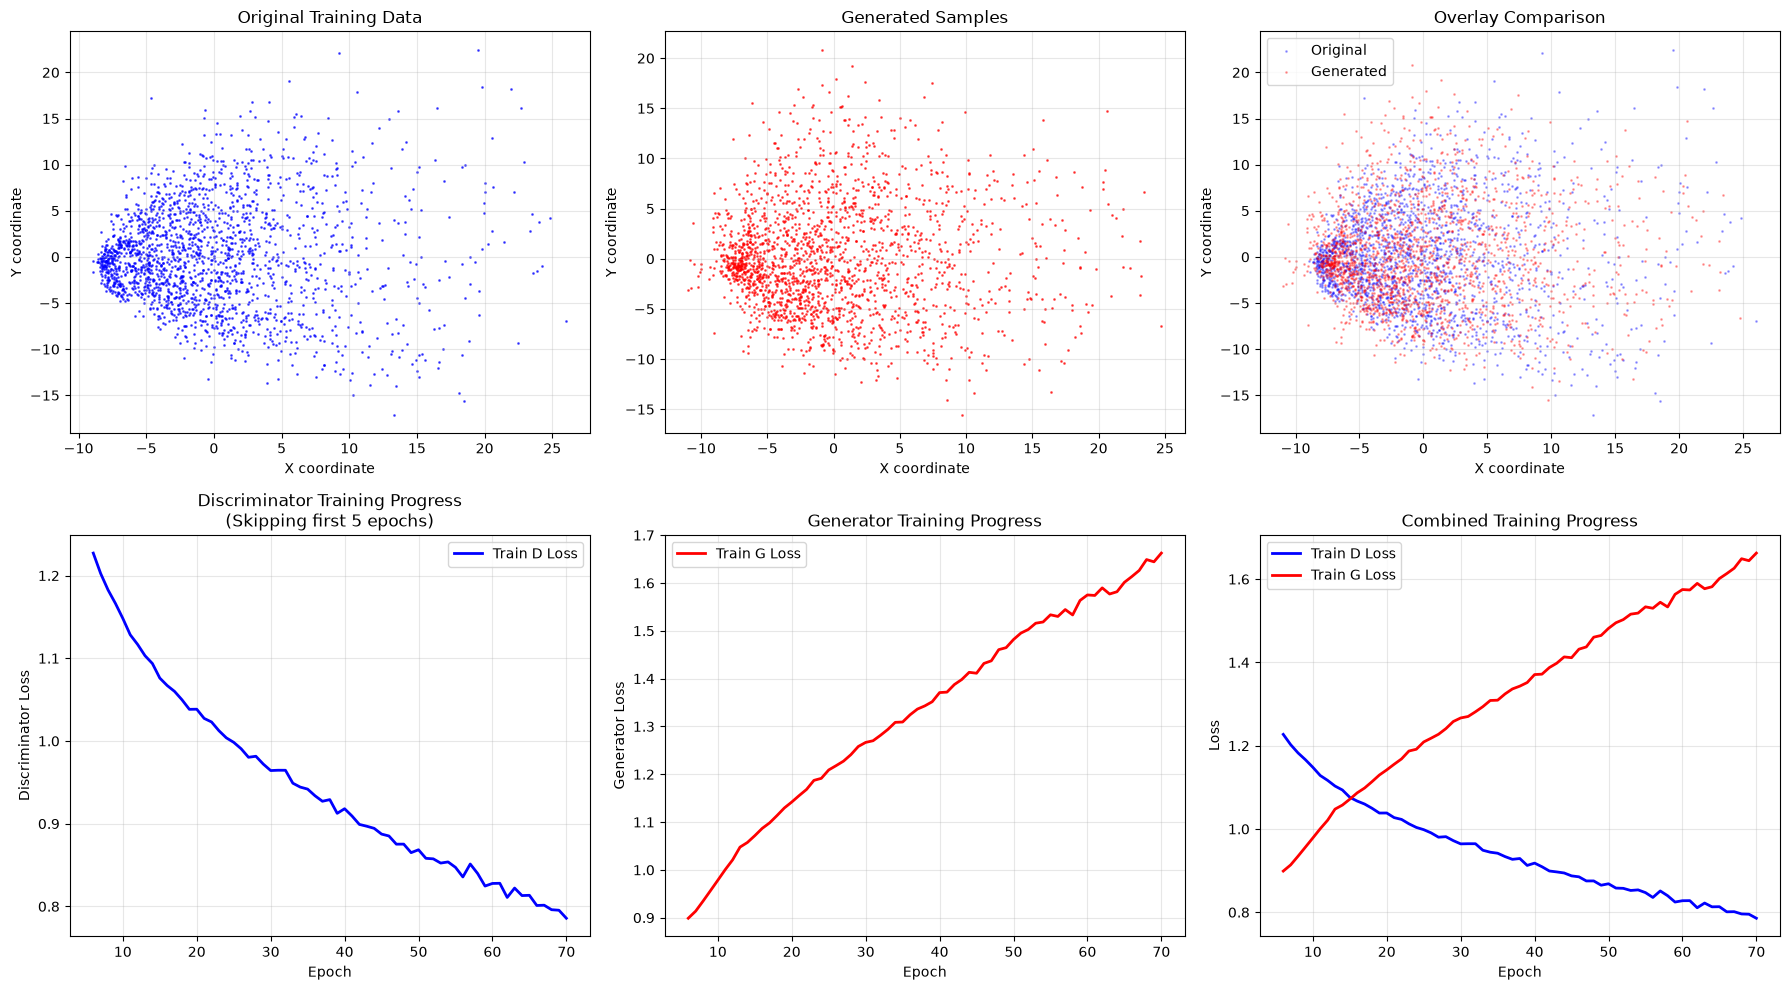

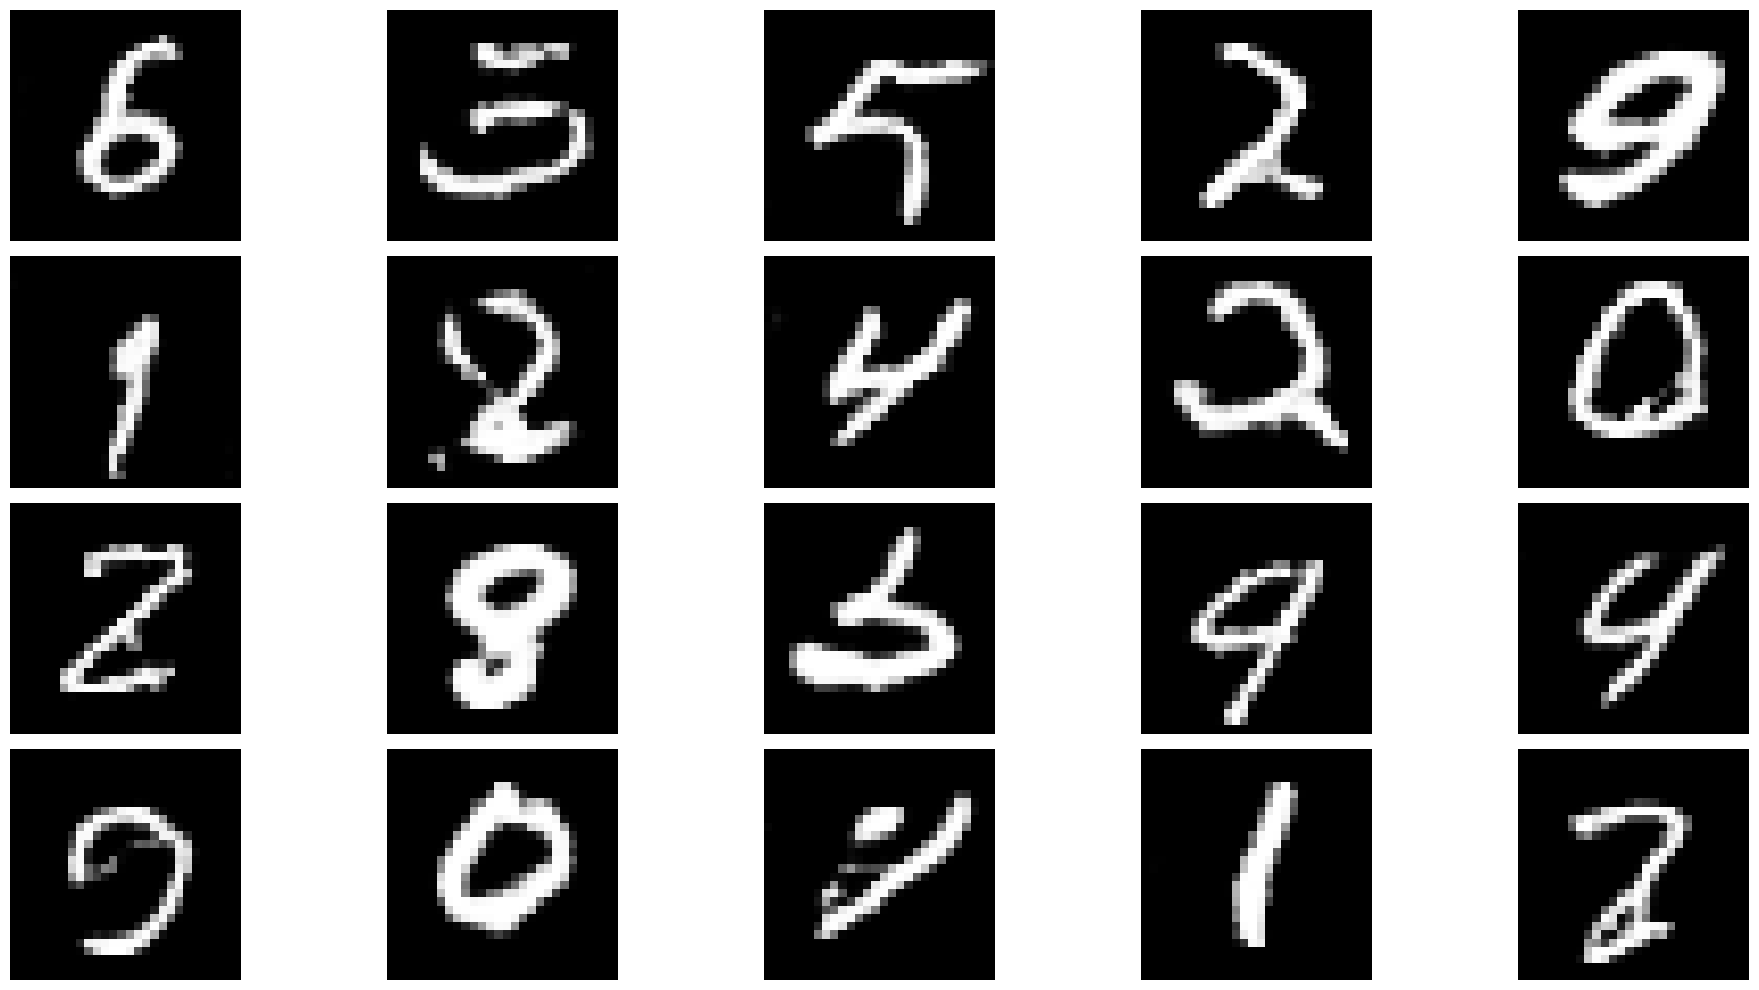

📈 Epoch 70 Summary:
   Train D Loss: 0.7857, Val D Loss: 1.2830
   Train G Loss: 1.6625, Val G Loss: 2.0699

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.771639	G_loss: 1.247938
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.925009	G_loss: 3.258059
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.738044	G_loss: 1.446137
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.618633	G_loss: 1.803427
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.720155	G_loss: 1.471882
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.778622	G_loss: 2.020292
Epoch: 71 [38400/60000 (64%)]	D_loss: 1.256587	G_loss: 1.518399
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.796957	G_loss: 1.308147
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.603725	G_loss: 1.844377
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.799992	G_loss: 1.022638
====> Epoch: 71 Train D_loss: 0.7901, Train G_loss: 1.6683
====> Epoch: 71 Val D_loss: 1.1933, Val G_loss: 0.8328
📈 Epoch 71 Summary:
   Train D Loss: 0.7901, Val D Loss: 1.1933
   Train G Loss: 1.6683

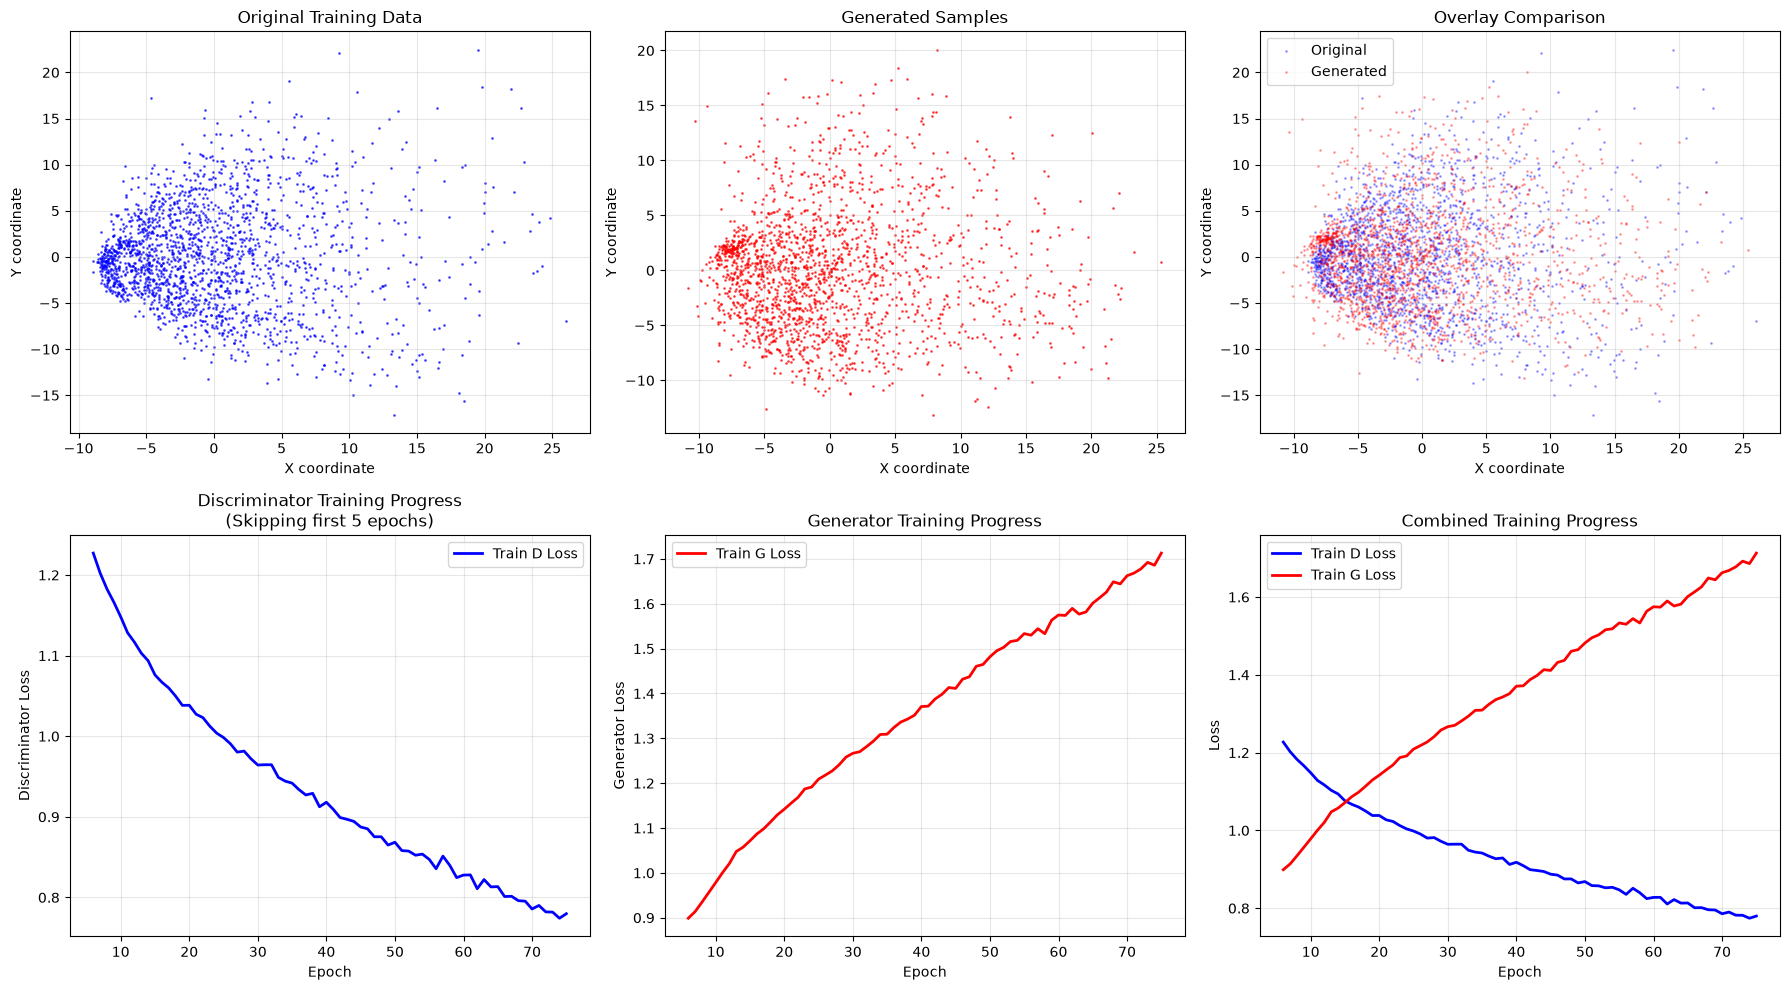

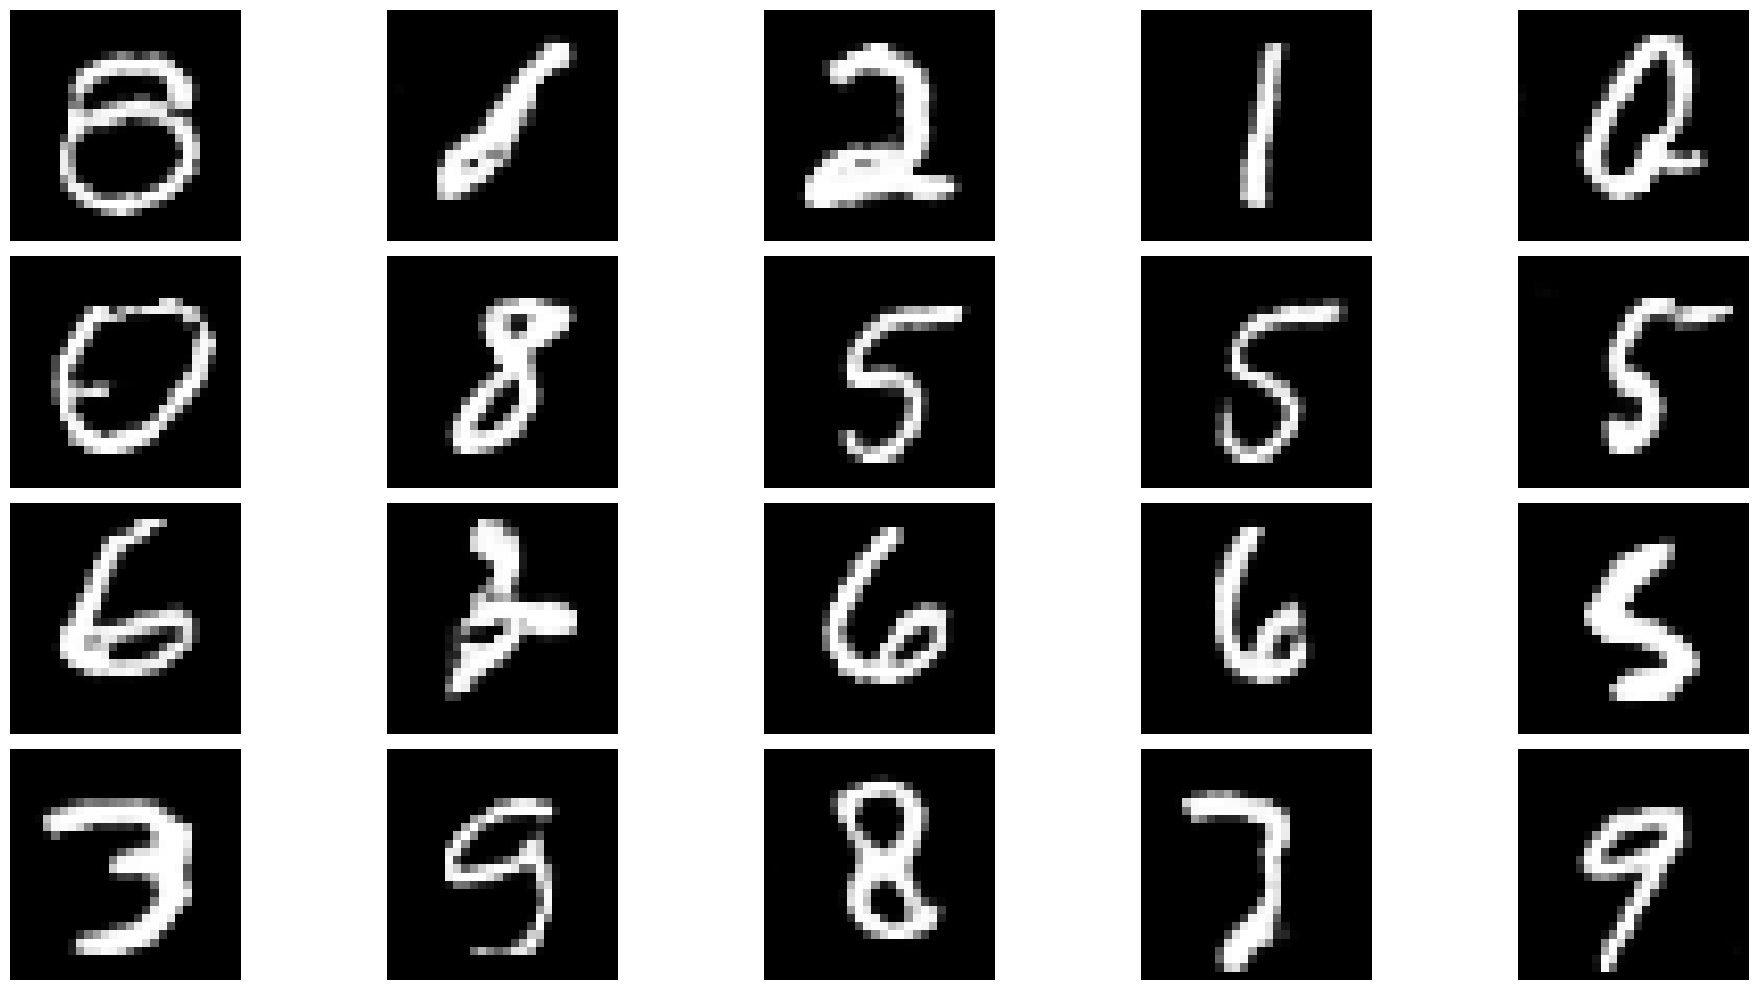

📈 Epoch 75 Summary:
   Train D Loss: 0.7798, Val D Loss: 1.1397
   Train G Loss: 1.7130, Val G Loss: 0.8908

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.712332	G_loss: 1.942047
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.818194	G_loss: 1.361144
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.726690	G_loss: 1.704212
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.753334	G_loss: 1.522648
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.574201	G_loss: 1.554860
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.676271	G_loss: 1.694626
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.795457	G_loss: 1.952245
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.804420	G_loss: 2.568964
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.802765	G_loss: 1.987342
Epoch: 76 [57600/60000 (96%)]	D_loss: 1.079126	G_loss: 0.775707
====> Epoch: 76 Train D_loss: 0.7678, Train G_loss: 1.7223
====> Epoch: 76 Val D_loss: 1.0781, Val G_loss: 1.0119
📈 Epoch 76 Summary:
   Train D Loss: 0.7678, Val D Loss: 1.0781
   Train G Loss: 1.7223

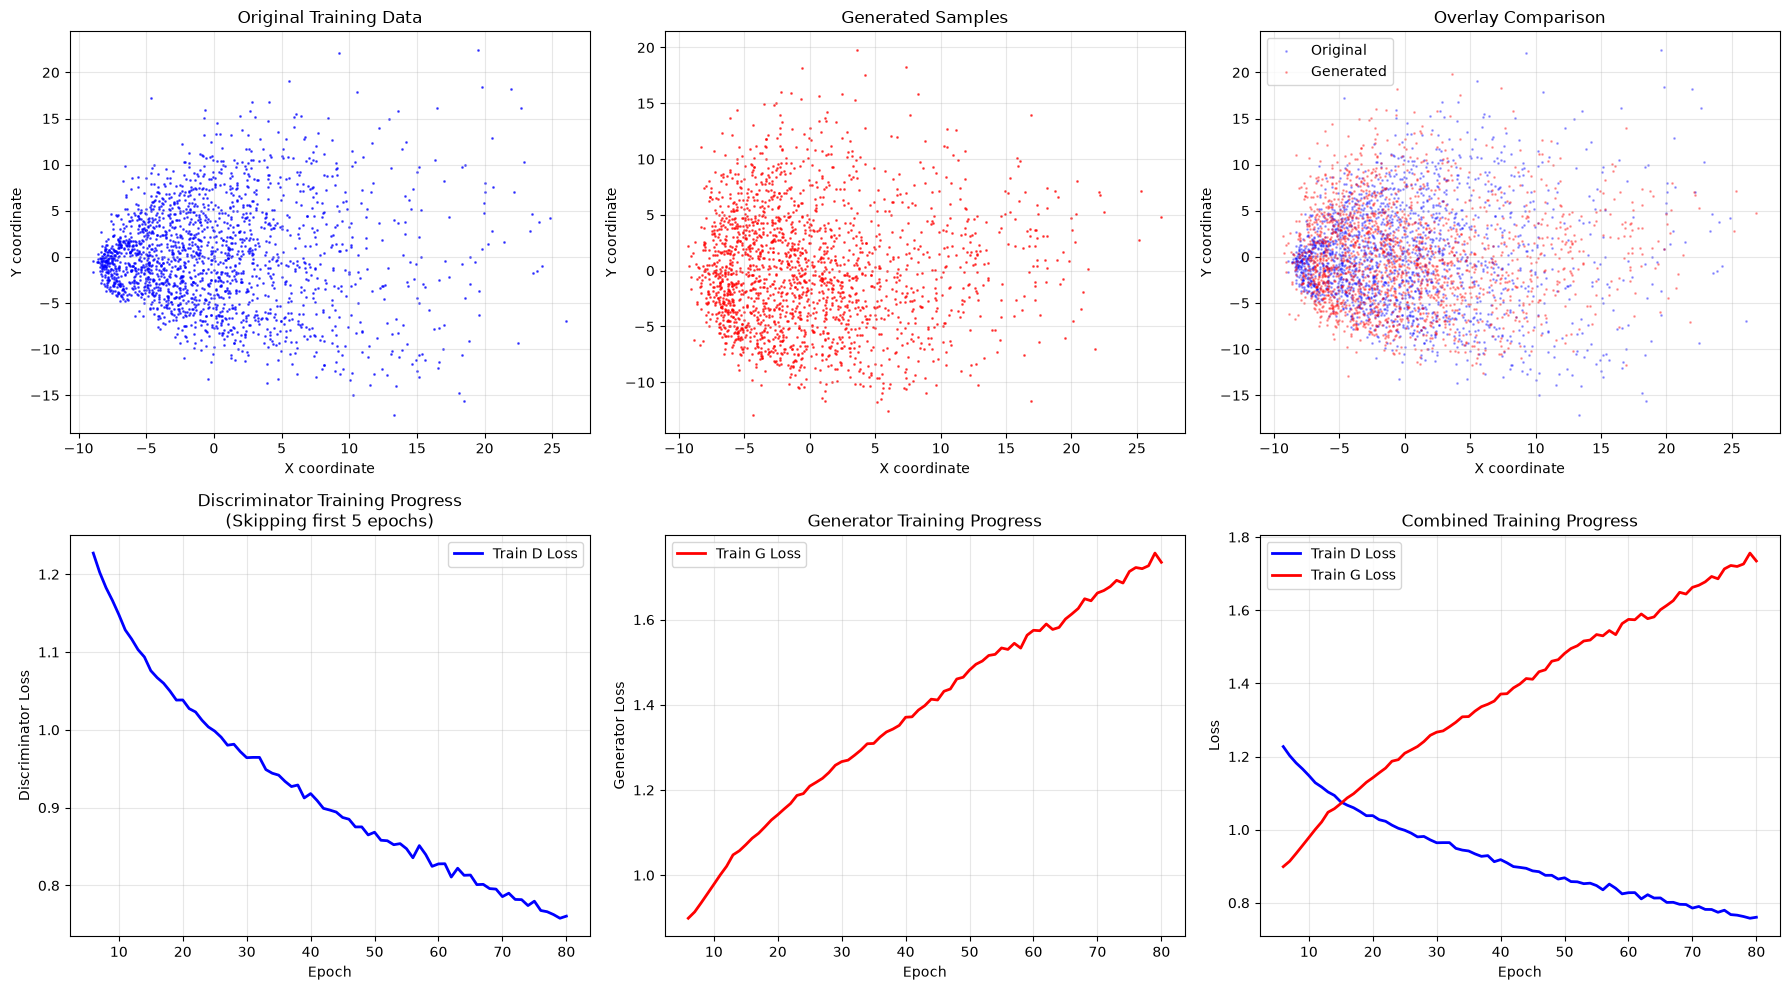

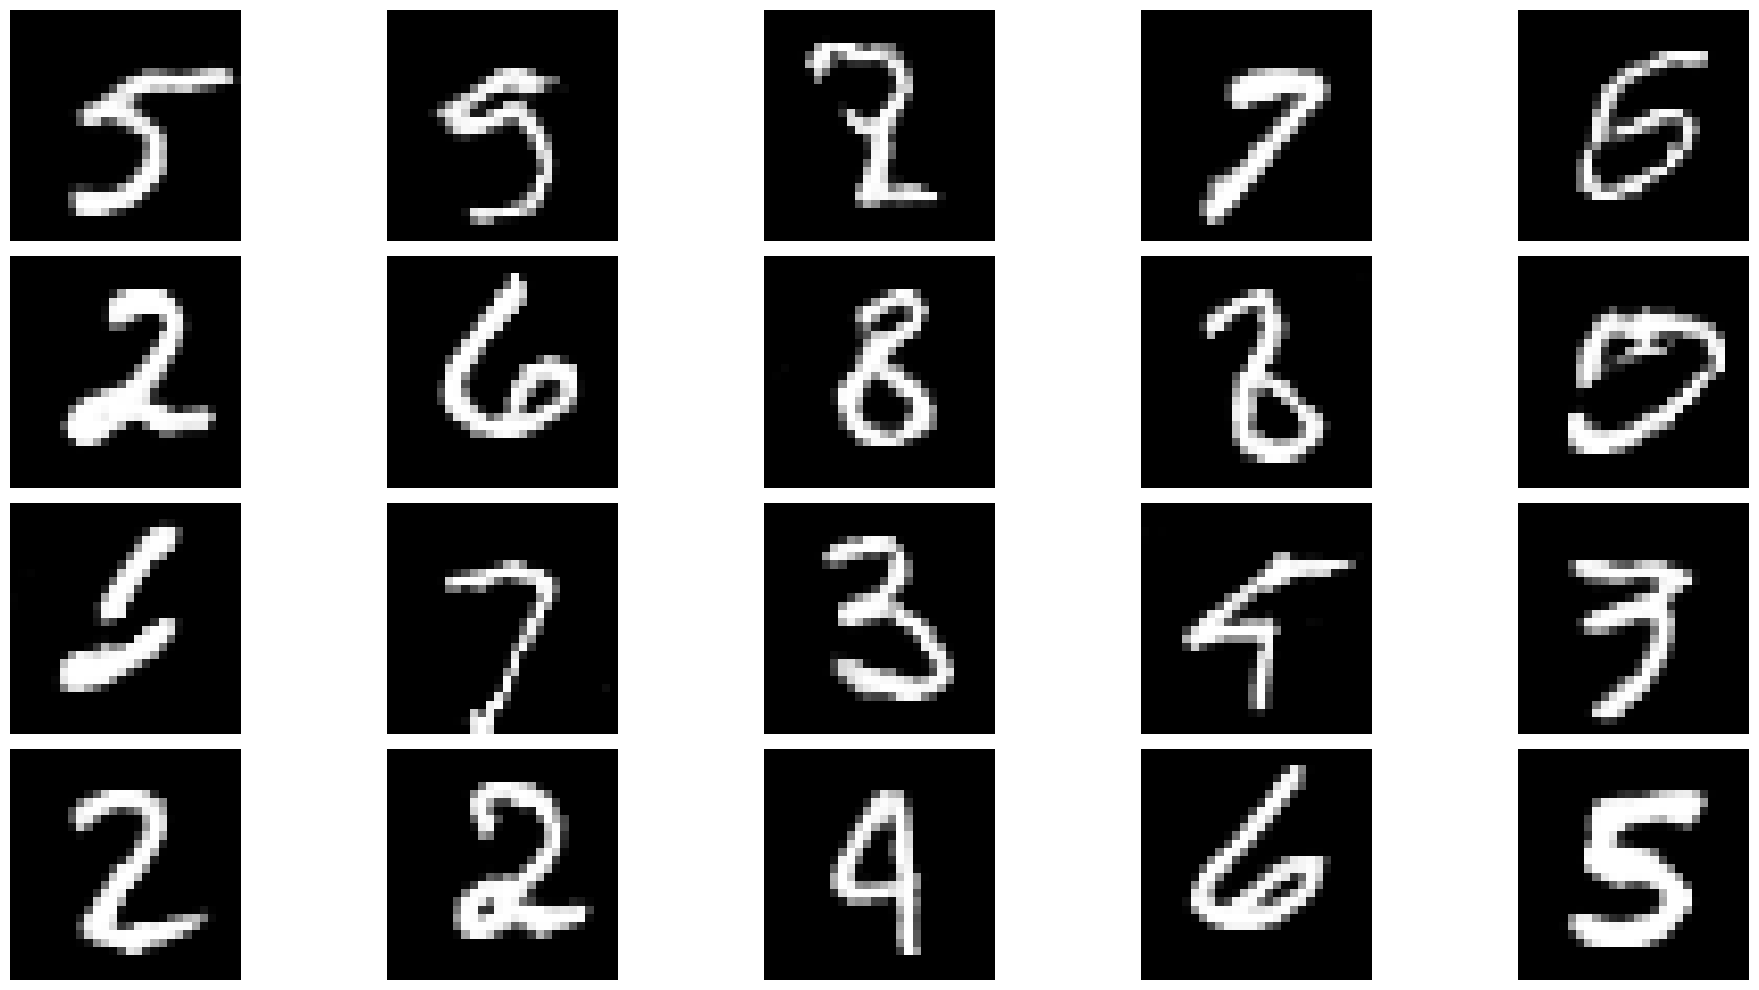

📈 Epoch 80 Summary:
   Train D Loss: 0.7606, Val D Loss: 1.2849
   Train G Loss: 1.7346, Val G Loss: 2.1342

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.865217	G_loss: 1.477605
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.916447	G_loss: 1.985539
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.805334	G_loss: 1.686089
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.892506	G_loss: 0.682138
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.613144	G_loss: 1.962363
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.661598	G_loss: 1.461579
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.665242	G_loss: 2.144398
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.816118	G_loss: 0.837034
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.700209	G_loss: 1.458407
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.644262	G_loss: 1.885429
====> Epoch: 81 Train D_loss: 0.7512, Train G_loss: 1.7461
====> Epoch: 81 Val D_loss: 1.3005, Val G_loss: 2.1463
📈 Epoch 81 Summary:
   Train D Loss: 0.7512, Val D Loss: 1.3005
   Train G Loss: 1.7461

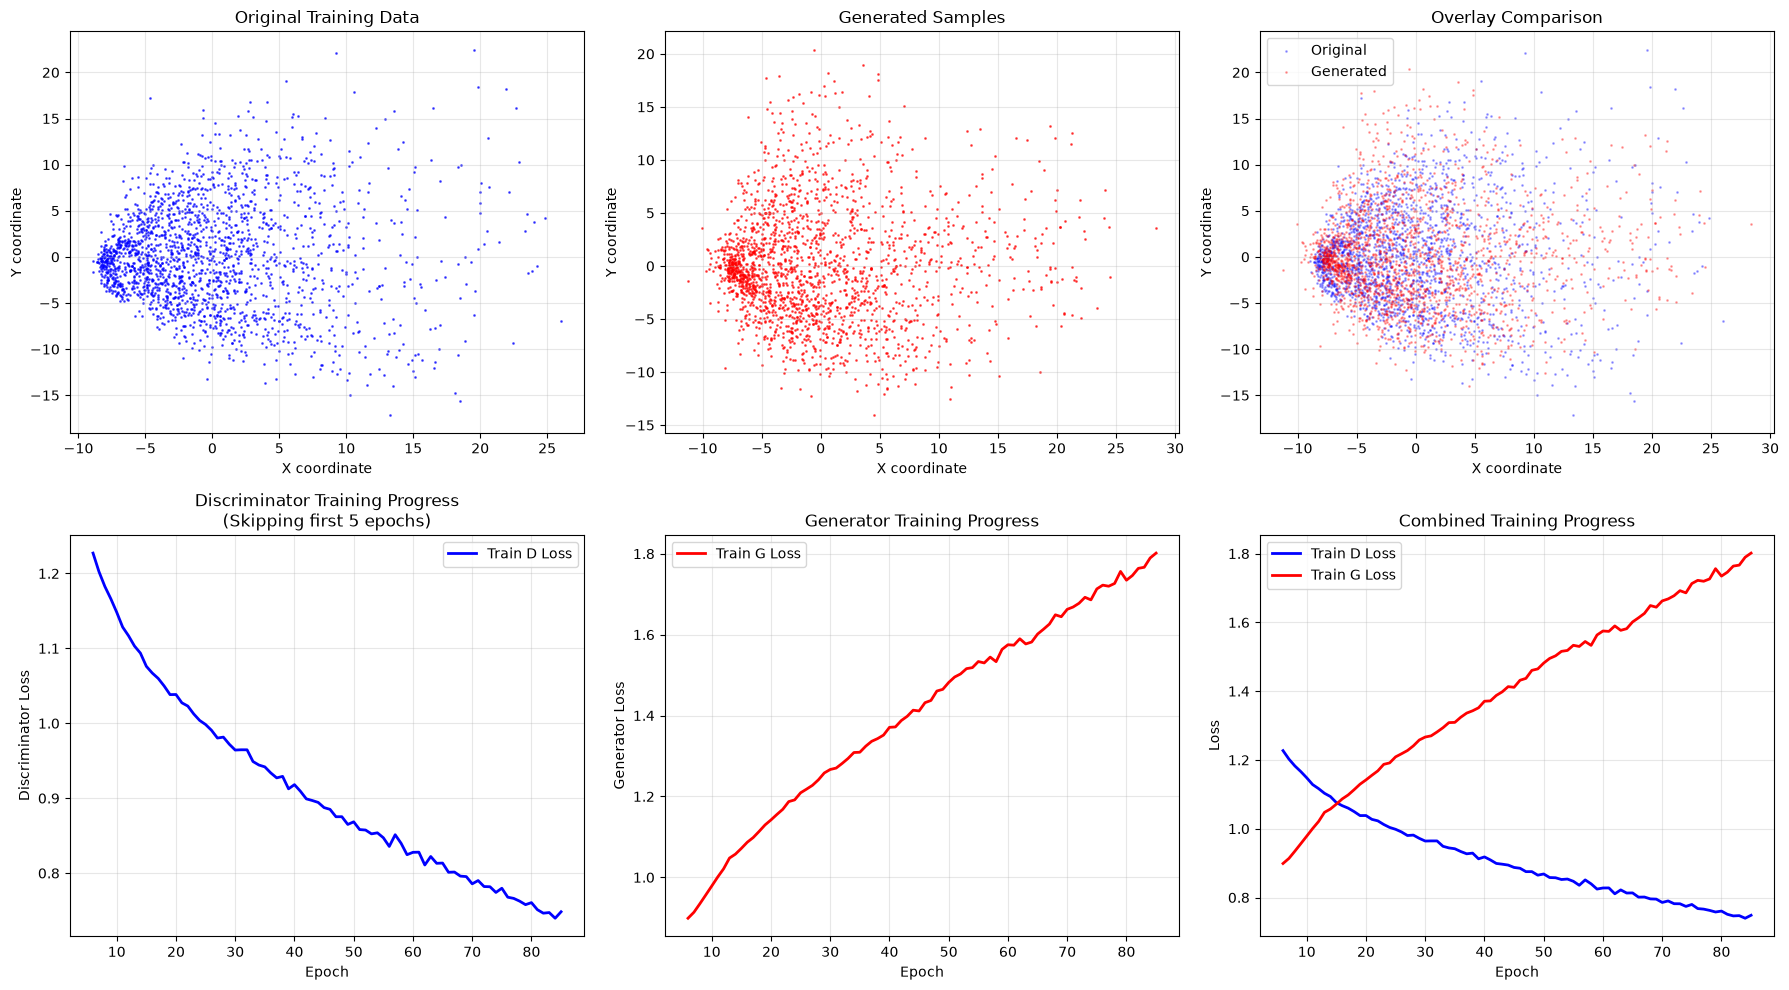

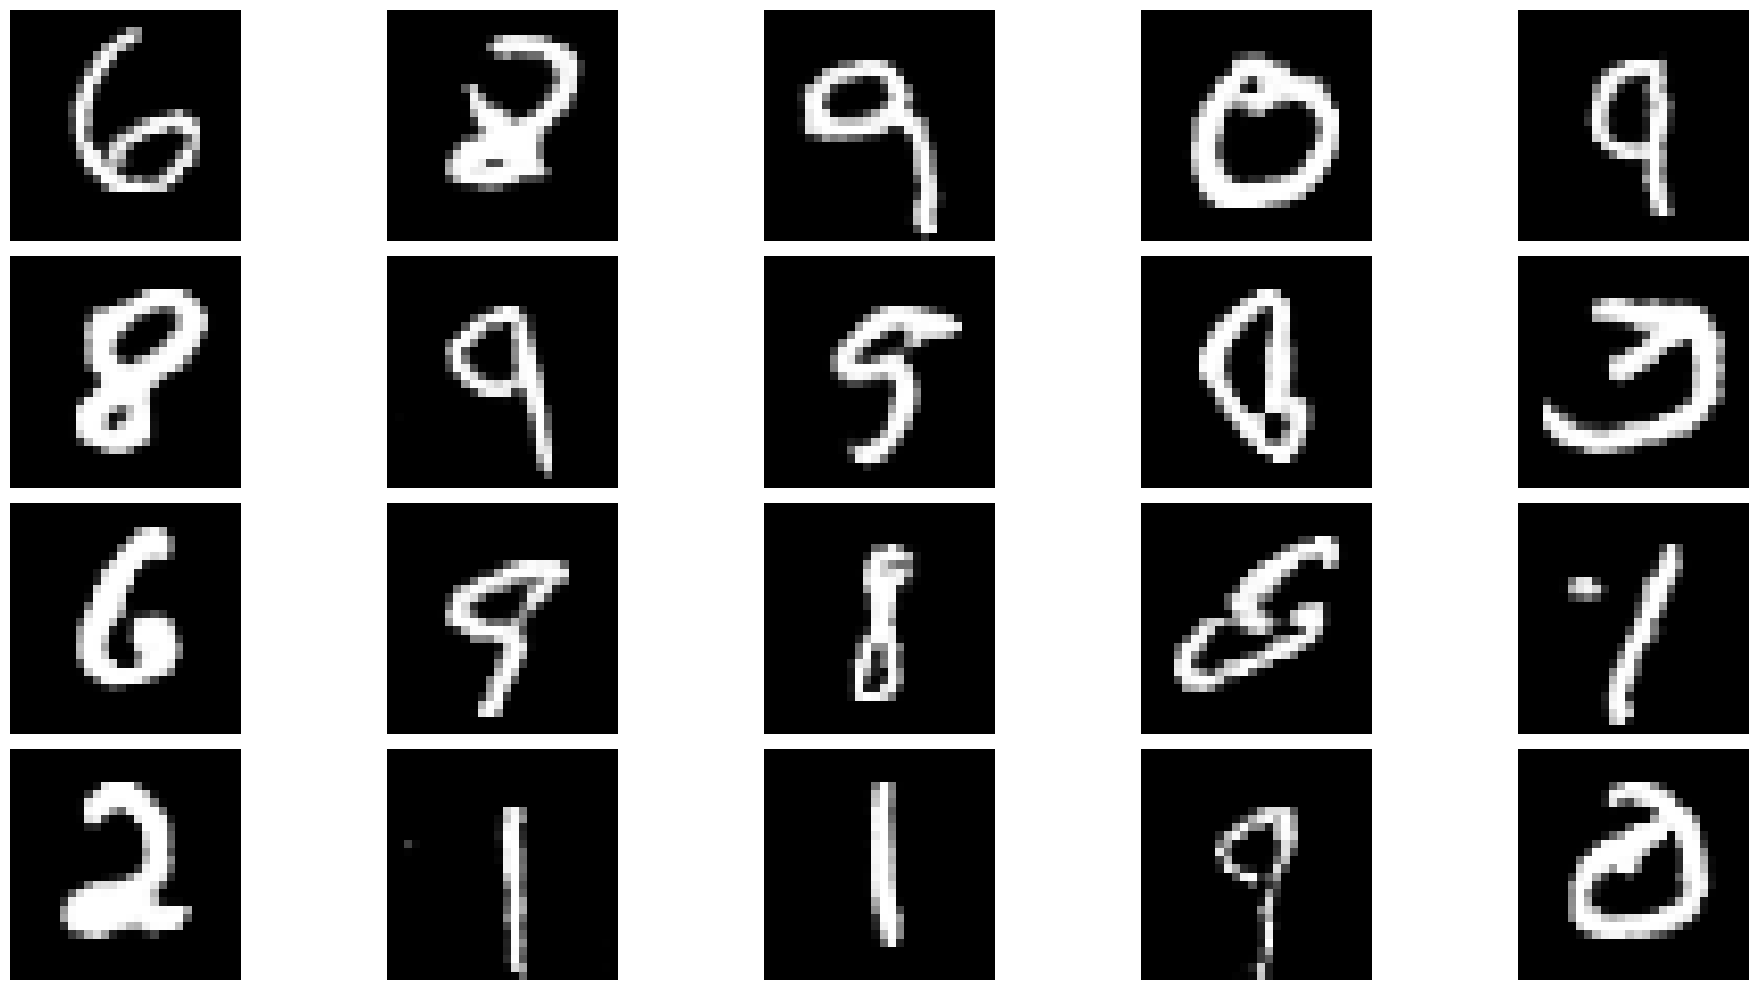

📈 Epoch 85 Summary:
   Train D Loss: 0.7484, Val D Loss: 1.0819
   Train G Loss: 1.8015, Val G Loss: 1.3963

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.738566	G_loss: 2.050236
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.770451	G_loss: 1.543417
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.669940	G_loss: 1.328095
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.905478	G_loss: 1.492116
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.903305	G_loss: 0.939307
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.630815	G_loss: 1.778389
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.706642	G_loss: 1.753042
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.769023	G_loss: 1.138010
Epoch: 86 [51200/60000 (85%)]	D_loss: 1.158284	G_loss: 2.844896
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.596354	G_loss: 1.611453
====> Epoch: 86 Train D_loss: 0.7335, Train G_loss: 1.7970
====> Epoch: 86 Val D_loss: 1.2044, Val G_loss: 1.9868
📈 Epoch 86 Summary:
   Train D Loss: 0.7335, Val D Loss: 1.2044
   Train G Loss: 1.7970

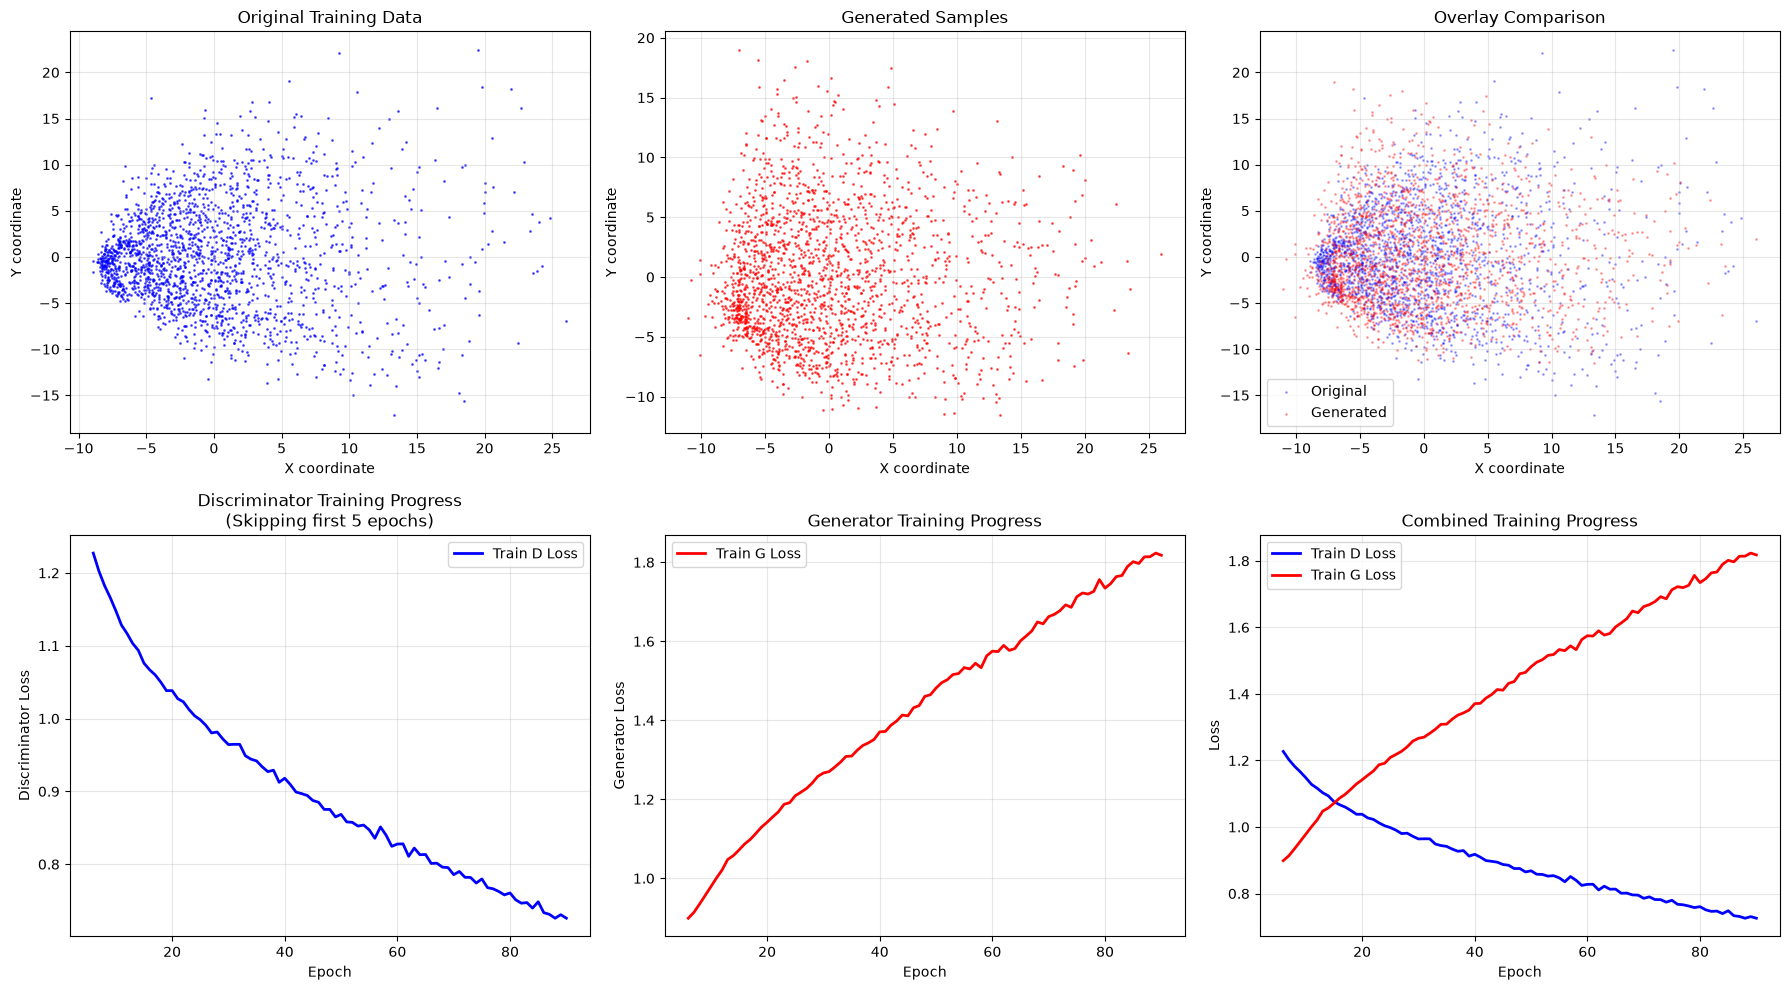

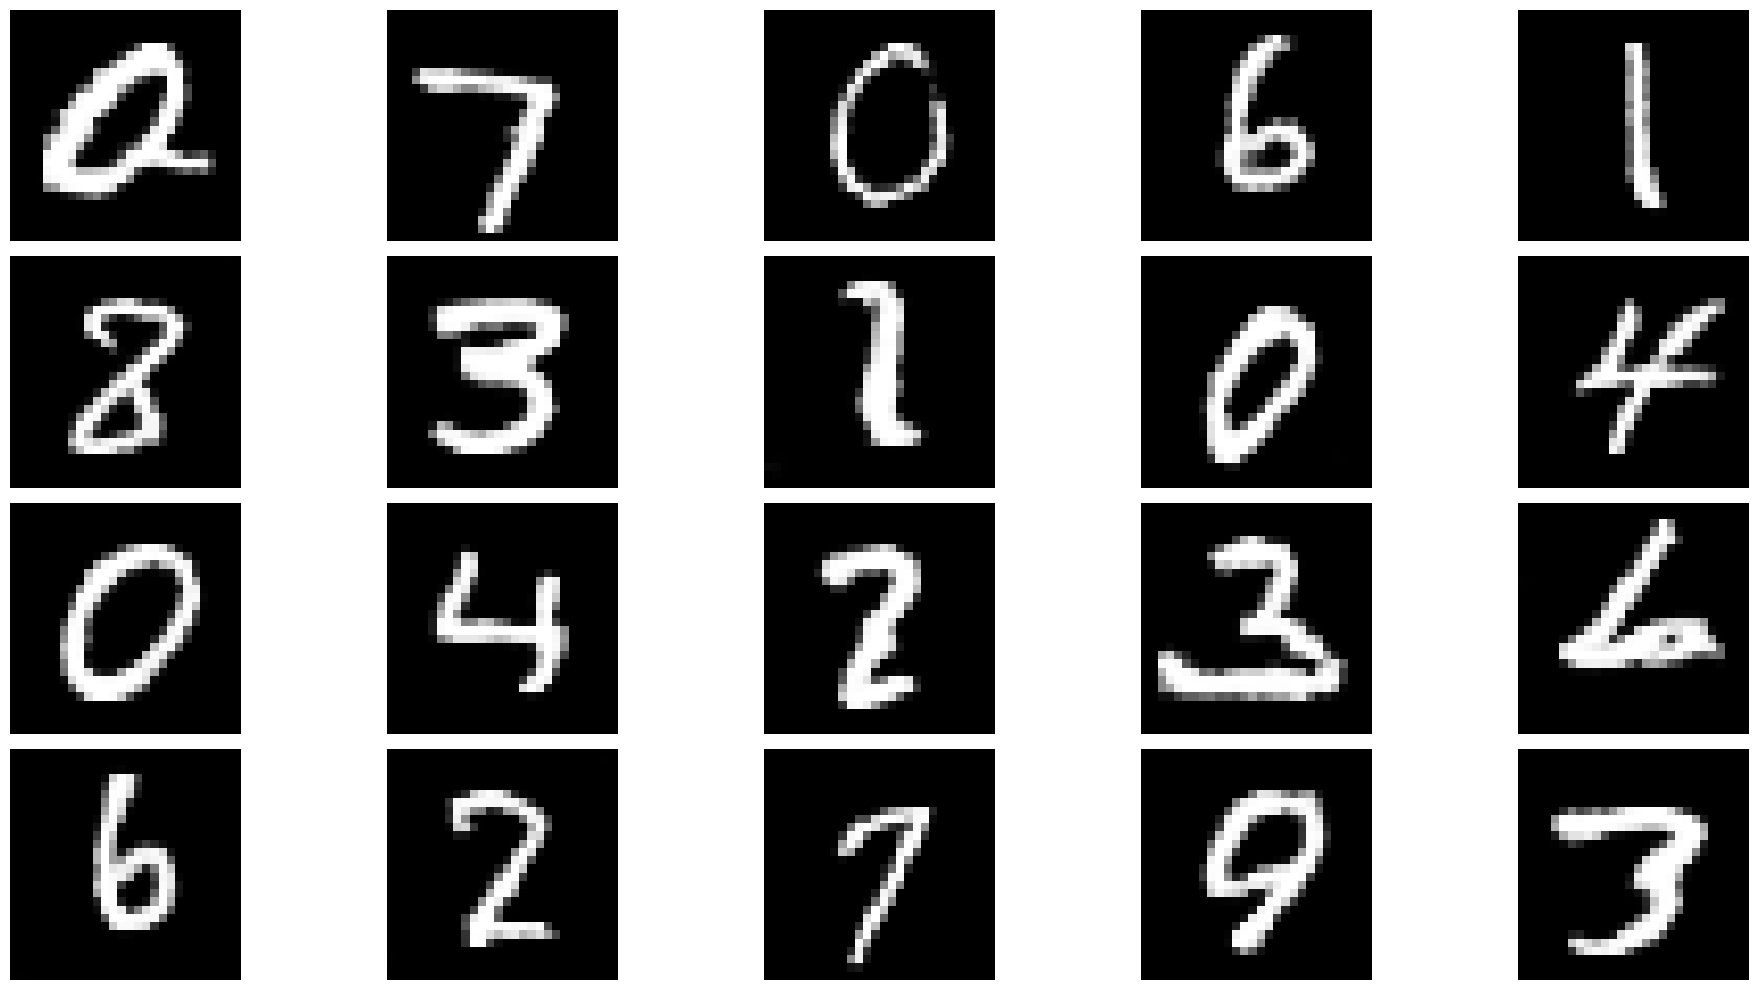

📈 Epoch 90 Summary:
   Train D Loss: 0.7260, Val D Loss: 1.1614
   Train G Loss: 1.8179, Val G Loss: 1.9397

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.675117	G_loss: 1.429508
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.784689	G_loss: 1.353321
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.828095	G_loss: 2.792400
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.515090	G_loss: 1.340369
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.611384	G_loss: 1.798718
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.698995	G_loss: 1.598308
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.885810	G_loss: 2.353645
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.658160	G_loss: 1.617527
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.791623	G_loss: 2.538173
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.776171	G_loss: 1.464034
====> Epoch: 91 Train D_loss: 0.7205, Train G_loss: 1.8489
====> Epoch: 91 Val D_loss: 1.3925, Val G_loss: 2.3900
📈 Epoch 91 Summary:
   Train D Loss: 0.7205, Val D Loss: 1.3925
   Train G Loss: 1.8489

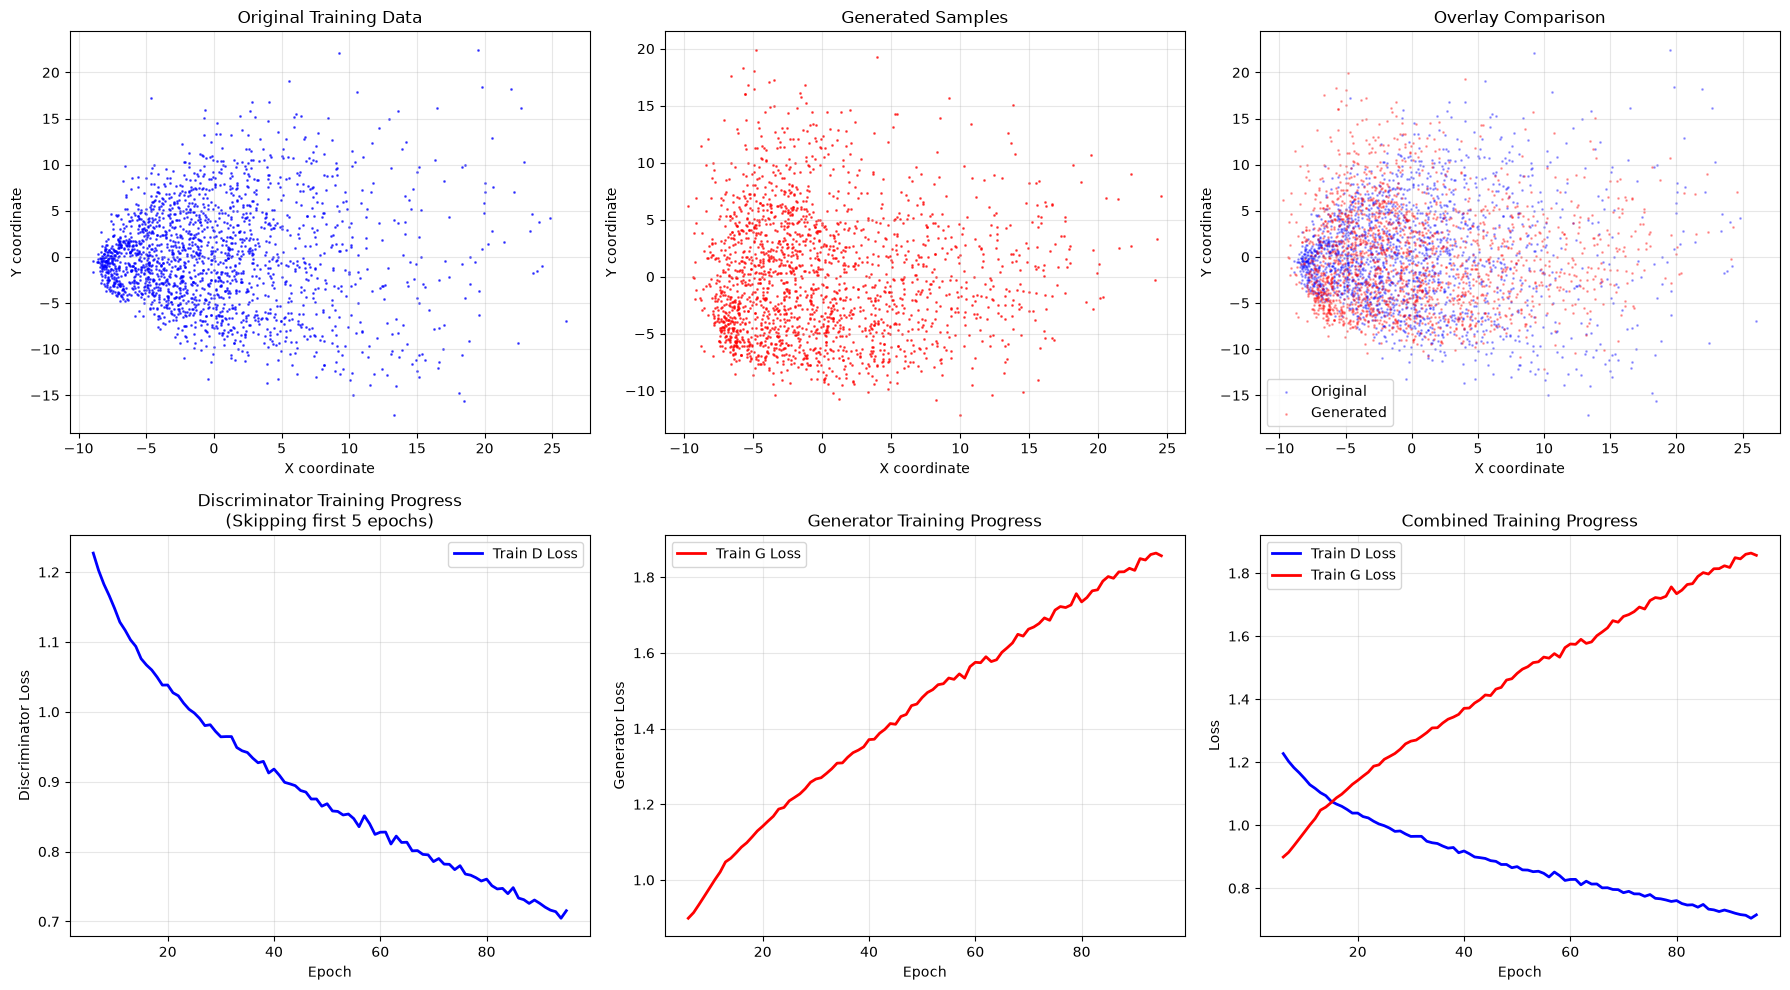

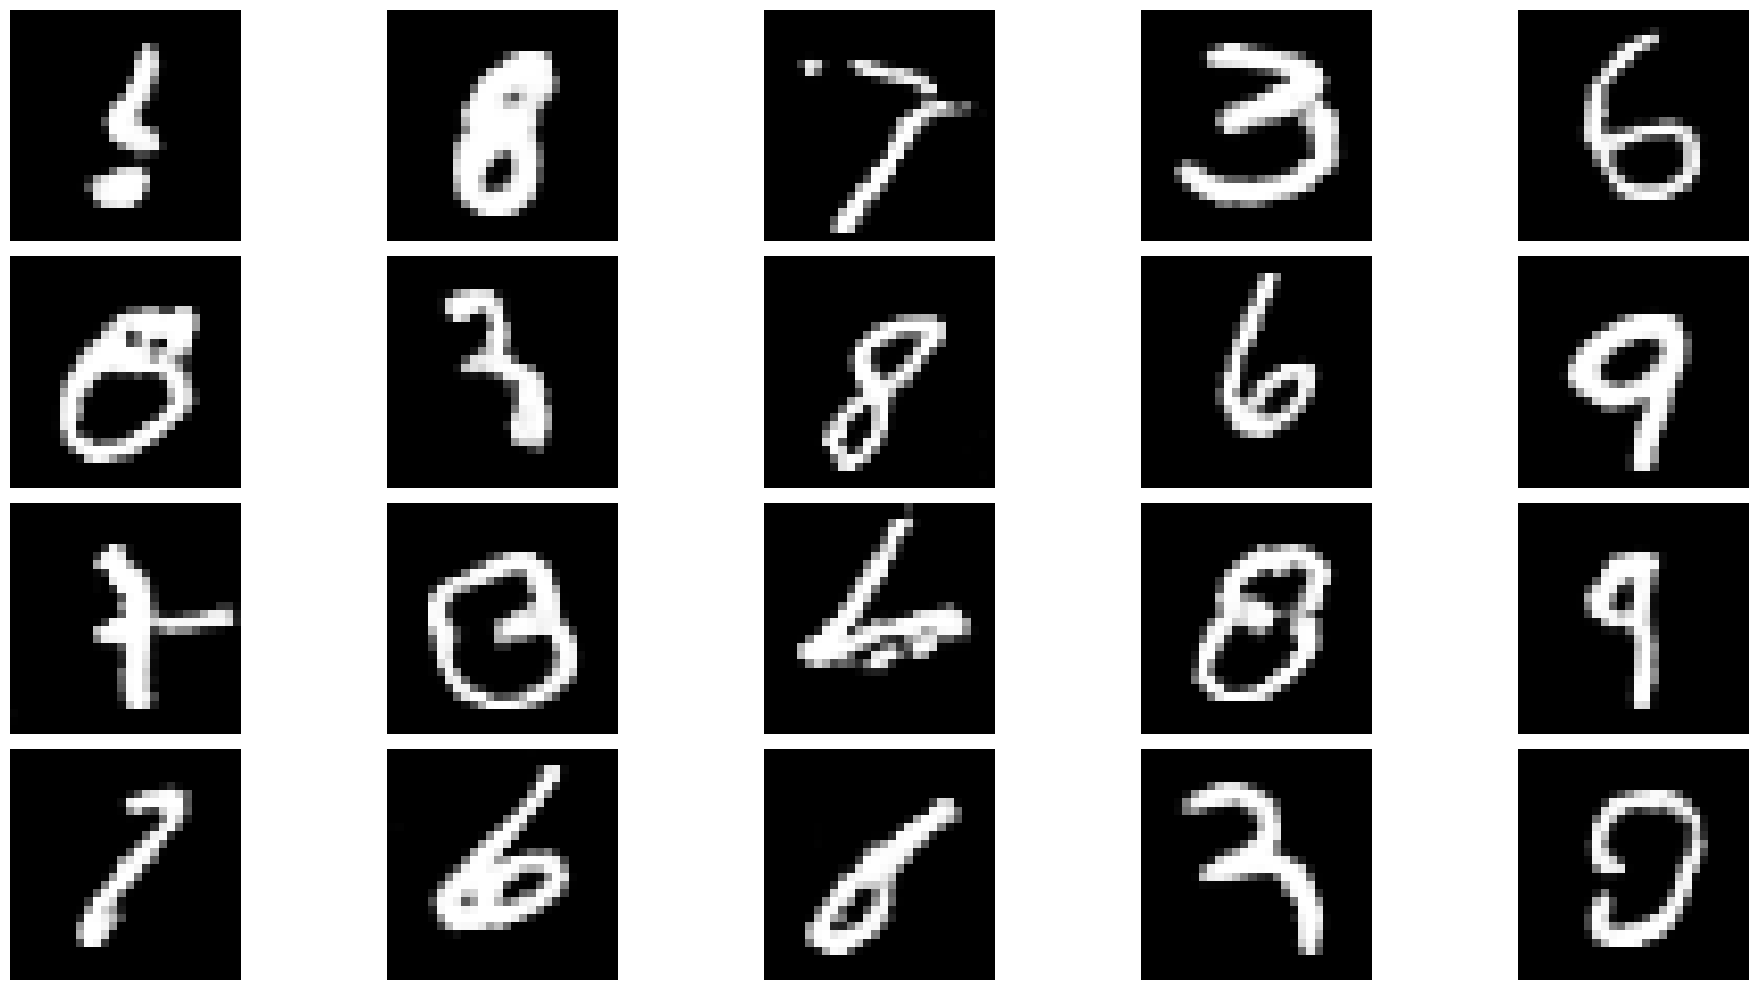

📈 Epoch 95 Summary:
   Train D Loss: 0.7154, Val D Loss: 1.0383
   Train G Loss: 1.8564, Val G Loss: 1.4957

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.619915	G_loss: 1.986751
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.622735	G_loss: 2.181662
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.618840	G_loss: 2.682448
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.503493	G_loss: 2.058391
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.791159	G_loss: 0.984741
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.864742	G_loss: 1.738777
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.610680	G_loss: 2.463002
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.912588	G_loss: 4.014221
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.702694	G_loss: 1.380777
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.723145	G_loss: 1.678125
====> Epoch: 96 Train D_loss: 0.7090, Train G_loss: 1.8768
====> Epoch: 96 Val D_loss: 1.7203, Val G_loss: 2.9044
📈 Epoch 96 Summary:
   Train D Loss: 0.7090, Val D Loss: 1.7203
   Train G Loss: 1.8768

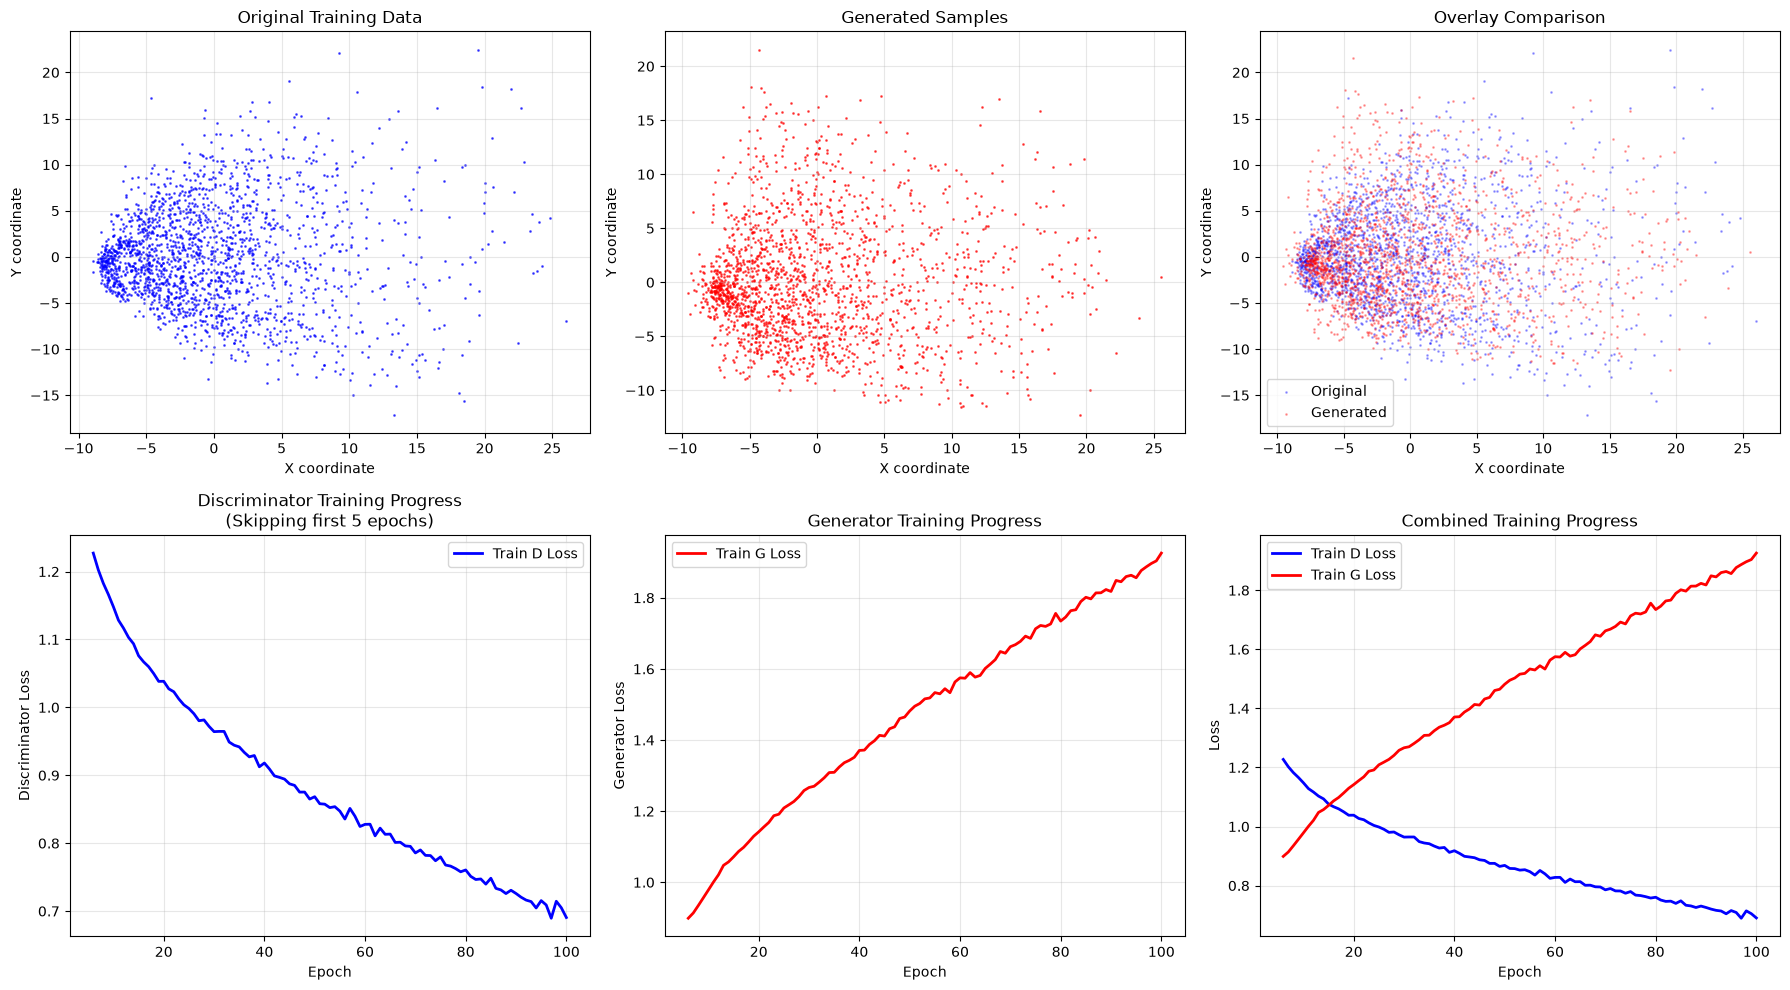

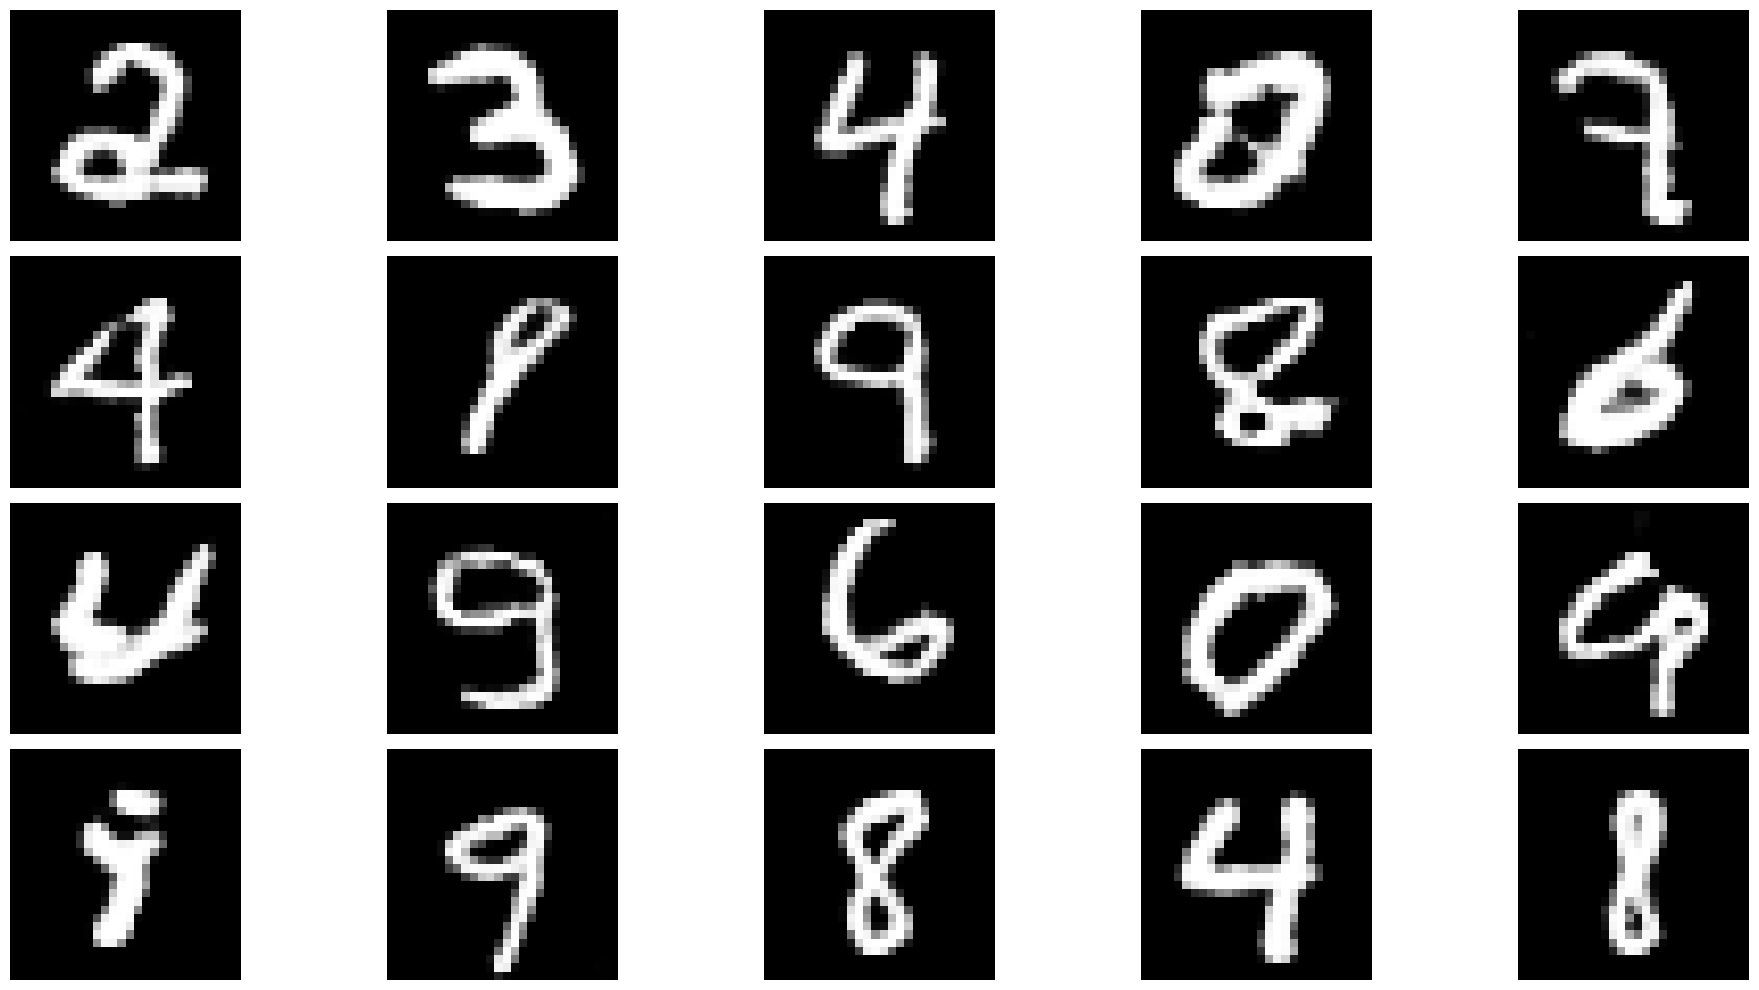

📈 Epoch 100 Summary:
   Train D Loss: 0.6906, Val D Loss: 1.1260
   Train G Loss: 1.9258, Val G Loss: 1.7789

🎉 Training completed!

🎨 Final comprehensive visualization:


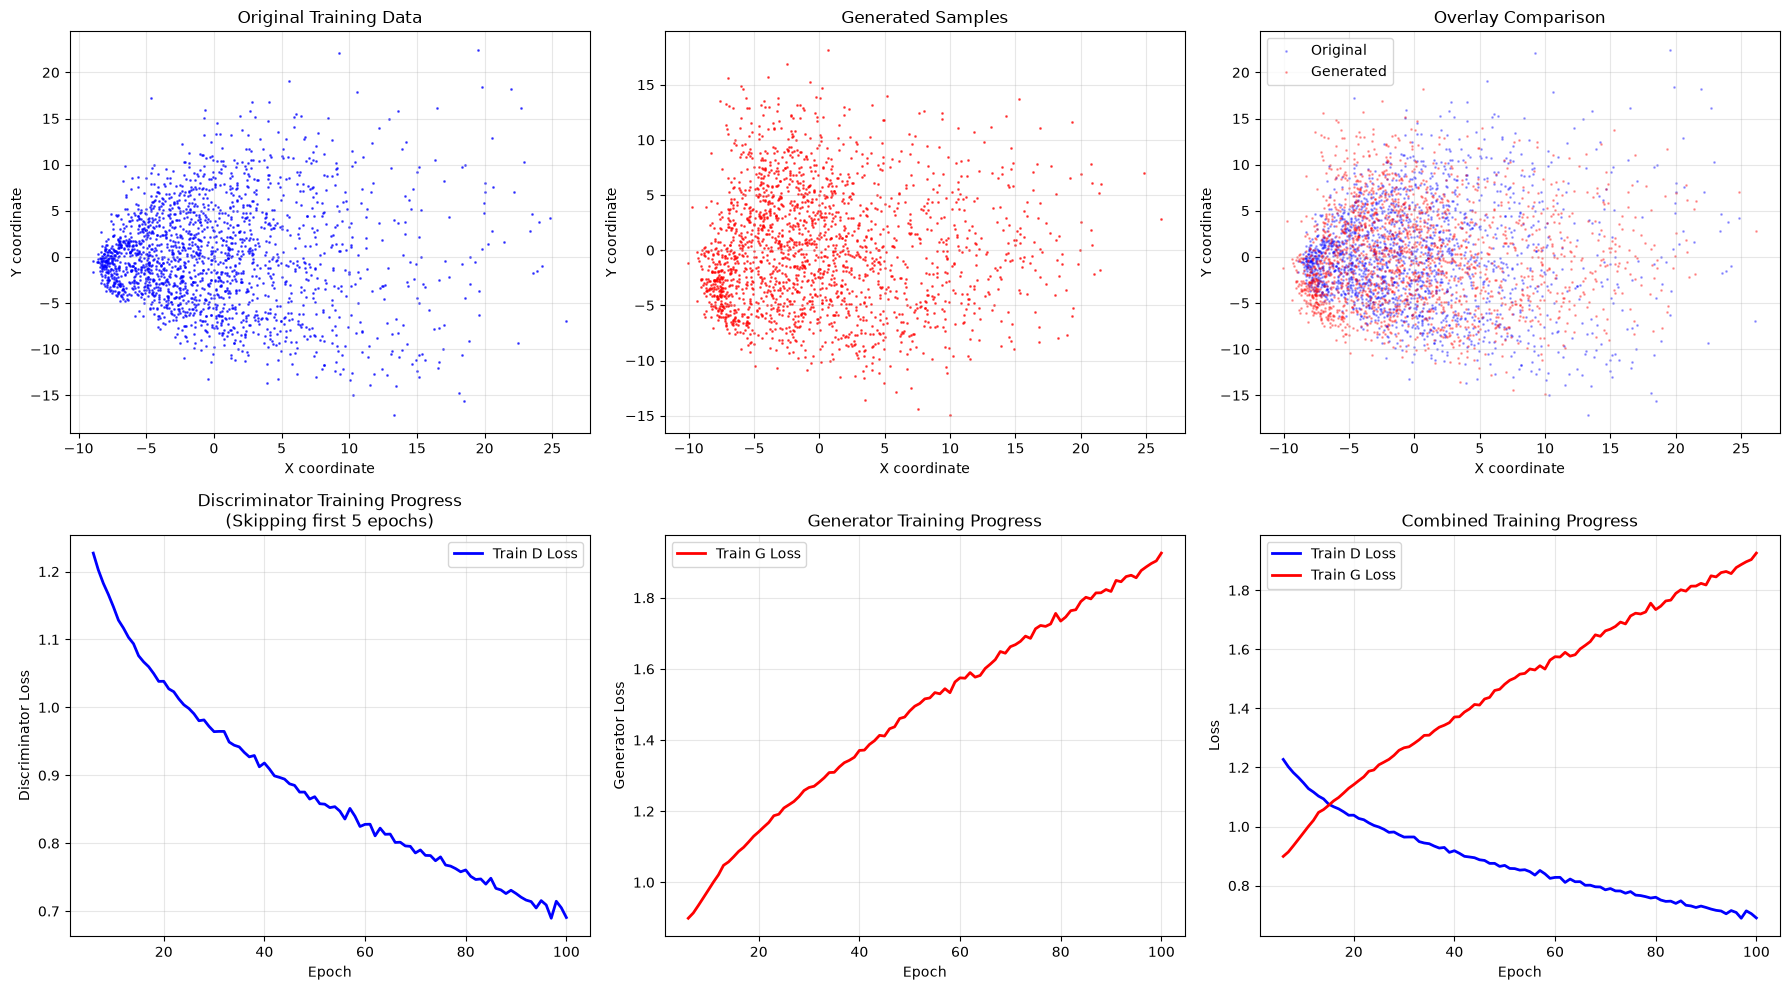

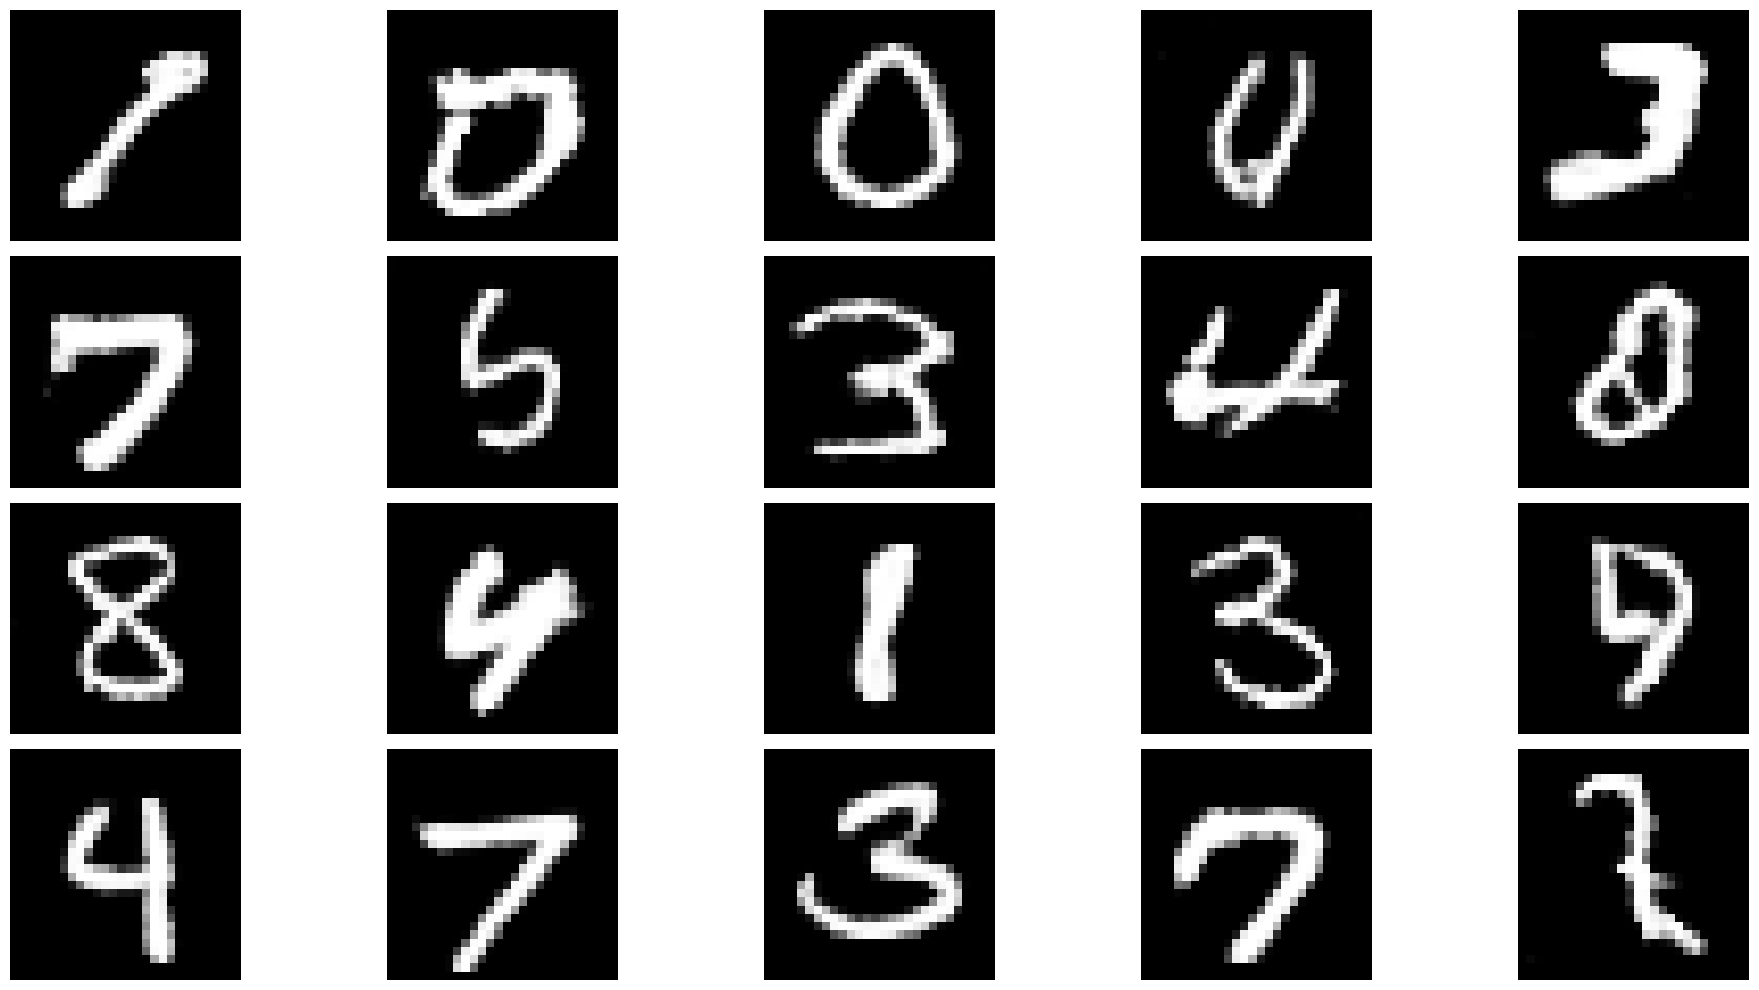

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


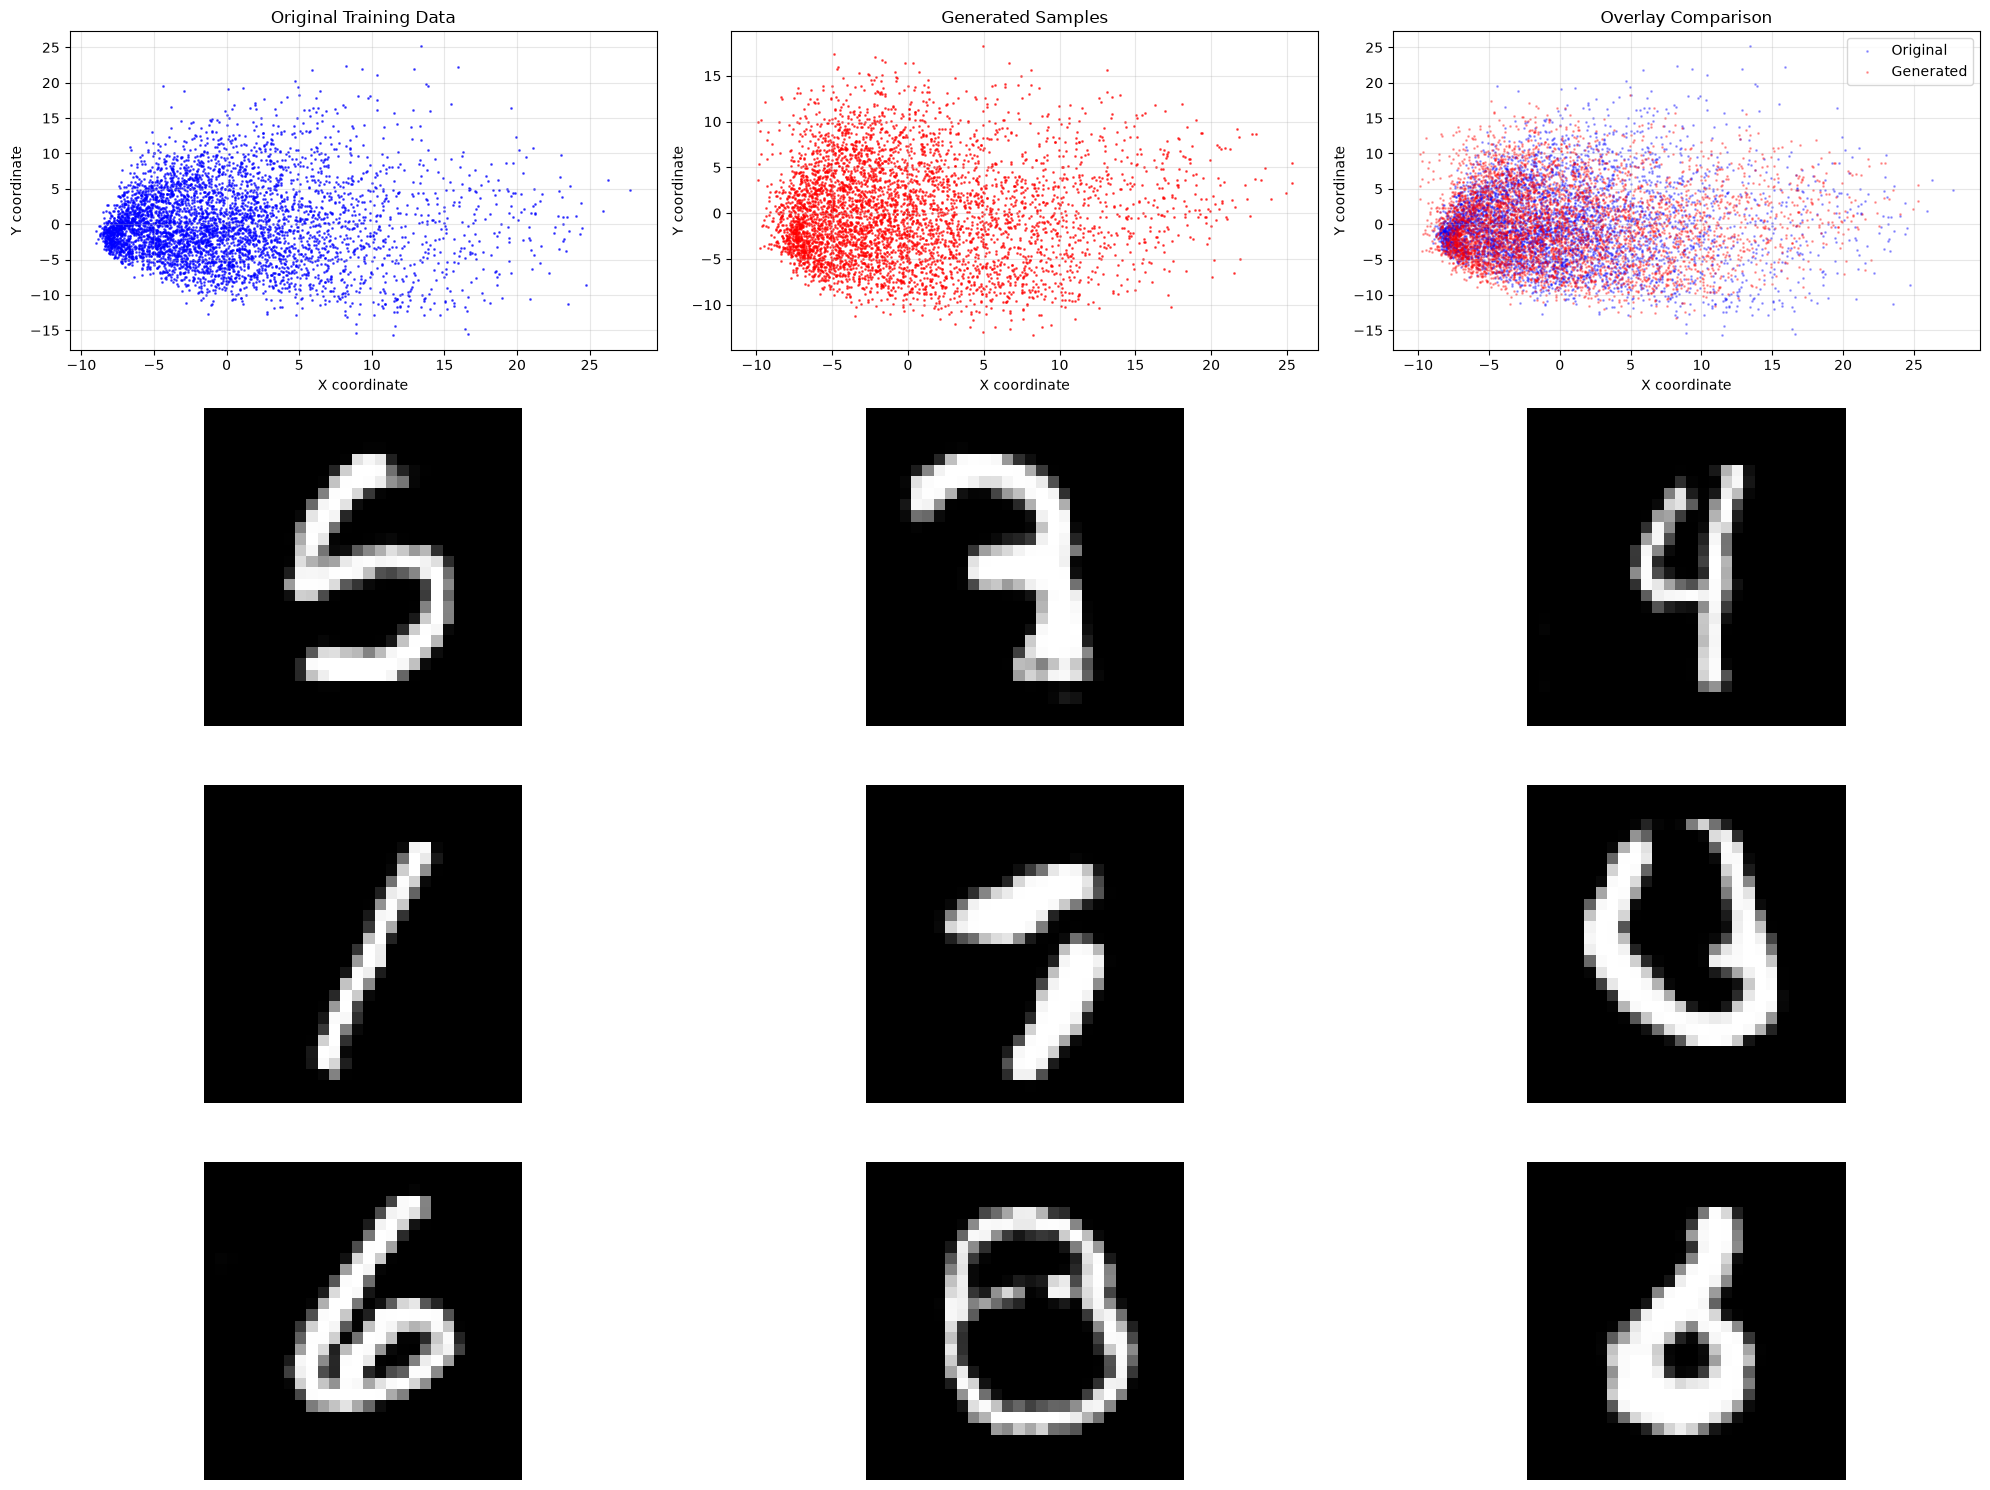

Real data confidence: 0.633
Fake data confidence: 0.272


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
